# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos Regresión para la Predicción de Precios de Casas**

**Integrantes del Equipo:**

* Sergio Alberto Chávez Velazquez A01099484
* Jonathan Chávez Medina A01841047
* Liliana Charles Cruz A01840600
* Juan Carlos Chavez Hernandez A01840818

<div style="background-color:#F3F0FA; border-left:6px solid #5E35B1; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Declaración de uso de IA generativa**

Para el desarrollo de esta actividad el equipo utilizó **Claude Opus 5.5 (Anthropic)** como herramienta de apoyo en la exploración de alternativas de preprocesamiento, la generación y depuración de código, y la revisión de la redacción. Todas las decisiones metodológicas se validaron con evidencia del propio conjunto de datos y fueron revisadas por el equipo. El detalle por pregunta (uso del LLM, verificación realizada y correcciones del equipo) se presenta en el **Anexo**, junto con los prompts más relevantes.

Google. (2026). Gemini (Versión de 2026) [Modelo de lenguaje de gran escala]. https://gemini.google.com utilizado para depuracion y creación de código


</div>

# **Introducción: valuación automática de viviendas en Ames, Iowa**

### **Contexto del problema**

* El valor de una vivienda depende de cientos de atributos —tamaño, materiales, comodidades y ubicación— que un valuador humano no puede ponderar simultáneamente de forma consistente. Los **modelos automáticos de valuación** permiten estimar el precio en segundos y con criterios homogéneos.

* El reto para el equipo de ciencia de datos es elegir el algoritmo que mejor equilibre tres objetivos: **exactitud** de la estimación, **costo computacional** y **facilidad para explicar** cómo se llegó al resultado.

* Se comparan seis familias de modelos: regresión lineal múltiple (con regularización), árbol de decisión, bosque aleatorio, XGBoost, red neuronal de perceptrón multicapa y máquina de vector soporte. Después se evalúa si combinarlos mediante **VotingRegressor** y **StackingRegressor** aporta valor.

### **Datos**

* Conjunto `train.csv` del reto de Kaggle *House Prices – Advanced Regression Techniques*: **1,460 ventas residenciales** en Ames, Iowa (2006-2010), con 79 variables explicativas y la variable objetivo **`SalePrice`** (precio de cierre en dólares). El conjunto fue compilado por Dean De Cock (2011, *Journal of Statistics Education*) a partir de los registros de la oficina de avalúos de Ames.

* El archivo `test.csv` de Kaggle **no incluye `SalePrice`**, por lo que no sirve para evaluar; toda la partición en entrenamiento y prueba se obtiene de `train.csv`.

### **Restricciones de la actividad**

* La valuación se realiza en un **plano temporal estático**: se elimina `YrSold`; `YearBuilt` y `YearRemodAdd` se convierten en las edades `AgeHouse` y `AgeRemod`, con respecto a 2026; y se decide el tratamiento de `MoSold`.

* La **métrica de referencia es el RMSE** en dólares, evitando cualquier filtrado de información. Además se reportan MAE, R², MAPE y tiempo de entrenamiento. Kaggle evalúa el RMSE sobre el logaritmo del precio; en este cuaderno los modelos se entrenan sobre el logaritmo, pero se seleccionan y se reportan en dólares, como pide la actividad.

<div style="background-color:#F3F0FA; border-left:6px solid #5E35B1; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Mapa del cuaderno: dónde se responde cada pregunta**

| Sección | Contenido | Preguntas |
|---|---|---|
| 1. Carga y conocimiento de los datos | Verificación, clasificación de variables, reserva del conjunto de prueba, análisis exploratorio, atípicos y valores faltantes | Evidencia para P4 y P5 |
| 2. Restricciones temporales | `YrSold`, edades de la vivienda y mes de venta | **P1, P2, P3** |
| 3. Limpieza y preprocesamiento | Imputación, transformaciones, NA estructurales y One-Hot | **P4, P5, P6** |
| 4. Partición y modelo base | Esquema de validación y RMSE del modelo ingenuo | **P7, P8** |
| 5. Entrenamiento y ajuste | Seis modelos con curvas de aprendizaje y tabla de métricas | **P9 a-f** |
| 6. Factores y selección | Factores del mejor modelo y los tres mejores según RMSE + MAE | **P10, P11** |
| 7. Modelos de ensamble | Investigación, VotingRegressor, StackingRegressor y comparación | **P12 a P15** |
| 8. Reportes y conclusiones | Reporte técnico, reporte ejecutivo y conclusiones | **P16, P17** |

**Principio rector:** el conjunto de prueba se separa antes de cualquier análisis. Toda decisión (imputación, transformaciones, atípicos, hiperparámetros, selección de modelos) se toma solo con el conjunto de entrenamiento, y el de prueba se usa únicamente para la evaluación final.

</div>

## **Configuración del entorno**

<div style="background-color:#F3F0FA; border-left:6px solid #5E35B1; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Reproducibilidad**

* La siguiente celda verifica las **versiones exactas** de scikit-learn (1.9.1) y xgboost (3.4.1) con las que se ejecutó y validó este cuaderno, y **las instala solo si la versión disponible es distinta**. Las cifras citadas en las celdas de texto provienen de esa ejecución; con otras versiones, los resultados pueden variar ligeramente. En Colab conviene ejecutar el cuaderno en un **entorno de ejecución nuevo**, con `train.csv` cargado en la sesión.
* **Tiempo de ejecución aproximado:** 10 a 12 minutos con 2 núcleos de CPU, como en Colab. La mayor parte corresponde a las búsquedas de hiperparámetros y a las validaciones cruzadas repetidas.

</div>

In [10]:
# Versiones con las que se ejecutó y validó este cuaderno; se instalan solo si la versión disponible es distinta.
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

import pandas as pd

VERSIONES_VALIDADAS = {'scikit-learn': '1.9.1', 'xgboost': '3.4.1'}

def version_instalada(paquete):
    try:
        return version(paquete)
    except PackageNotFoundError:
        return 'no instalado'

por_instalar = [f'{p}=={v}' for p, v in VERSIONES_VALIDADAS.items() if version_instalada(p) != v]
if por_instalar:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--root-user-action=ignore', *por_instalar],
                   check=True, capture_output=True)
display(pd.DataFrame({'Paquete': list(VERSIONES_VALIDADAS), 'Versión validada': list(VERSIONES_VALIDADAS.values()),
                      'Versión disponible': [version_instalada(p) for p in VERSIONES_VALIDADAS],
                      'Acción': ['Instalada en esta ejecución' if f'{p}=={v}' in por_instalar else 'Ya disponible'
                                 for p, v in VERSIONES_VALIDADAS.items()]}))

,Paquete,Versión validada,Versión disponible,Acción
0,scikit-learn,1.9.1,1.9.1,Ya disponible
1,xgboost,3.4.1,3.4.1,Ya disponible


In [11]:
# Librerías y configuración general del cuaderno.
import warnings
from datetime import date
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sklearn
import xgboost
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_score, cross_validate,
                                     cross_val_predict, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, PowerTransformer,
                                   StandardScaler, FunctionTransformer)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (root_mean_squared_error, mean_absolute_error, r2_score,
                             mean_absolute_percentage_error, root_mean_squared_log_error)

RANDOM_STATE = 11   # Semilla única para todas las particiones, búsquedas y modelos.
N_FOLDS = 5

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 220)
sns.set_theme(style='whitegrid')

VALIDADAS = {'scikit-learn': '1.9.1', 'xgboost': '3.4.1'}
versiones = pd.DataFrame({'Librería': ['Python', 'pandas', 'numpy', 'scikit-learn', 'xgboost'],
                          'Versión': [__import__('platform').python_version(), pd.__version__,
                                      np.__version__, sklearn.__version__, xgboost.__version__]})
versiones['Versión validada'] = versiones['Librería'].map(VALIDADAS).fillna('-')
display(versiones)

,Librería,Versión,Versión validada
0,Python,3.13.18,-
1,pandas,2.2.3,-
2,numpy,2.1.3,-
3,scikit-learn,1.9.1,1.9.1
4,xgboost,3.4.1,3.4.1


# **1. Carga y conocimiento de los datos**

Por omisión, `pandas.read_csv` interpreta como valor faltante tanto el texto `NA` como el texto `None`. En este conjunto, **`None` es una categoría válida** de `MasVnrType` ("sin recubrimiento de mampostería"), por lo que la lectura por omisión fabricaría cientos de faltantes inexistentes. Por ello el archivo se lee indicando que **solo `NA` es faltante**, y la diferencia se cuantifica.

*Para ejecutar en Google Colab:* subir `train.csv` (descargado de Kaggle) al almacenamiento de la sesión, en la misma carpeta que el cuaderno, antes de ejecutar todas las celdas.

In [12]:
from google.colab import drive
import pandas as pd

# Montamos temporalmente para lectura rápida
drive.mount('/content/drive', force_remount=True)

# Carga del archivo train.csv de Kaggle (debe estar en la misma carpeta que el cuaderno).
ARCHIVO = '/content/drive/MyDrive/Colab Notebooks/train.csv'

# Lectura por omisión de pandas: interpreta como faltante tanto 'NA' como el texto 'None'.
df_omision = pd.read_csv(ARCHIVO)

# Lectura corregida: solo 'NA' es valor faltante; 'None' es una categoría válida de MasVnrType.
df = pd.read_csv(ARCHIVO, keep_default_na=False, na_values=['NA'])

variables_revisar = ['MasVnrType', 'MasVnrArea', 'PoolQC', 'GarageType', 'LotFrontage']
comparacion_lectura = pd.DataFrame({
    'Faltantes con lectura por omisión': df_omision[variables_revisar].isna().sum(),
    'Faltantes con lectura corregida': df[variables_revisar].isna().sum(),
})
comparacion_lectura['Diferencia'] = (comparacion_lectura.iloc[:, 0] - comparacion_lectura.iloc[:, 1])
display(comparacion_lectura)

display(pd.DataFrame({'Filas': [df.shape[0]], 'Columnas': [df.shape[1]],
                      'Id duplicados': [df['Id'].duplicated().sum()],
                      'Registros duplicados (sin Id)': [df.drop(columns='Id').duplicated().sum()],
                      'Variable objetivo presente': ['SalePrice' in df.columns]}))

Mounted at /content/drive


,Faltantes con lectura por omisión,Faltantes con lectura corregida,Diferencia
MasVnrType,872,8,864
MasVnrArea,8,8,0
PoolQC,1453,1453,0
GarageType,81,81,0
LotFrontage,259,259,0


,Filas,Columnas,Id duplicados,Registros duplicados (sin Id),Variable objetivo presente
0,1460,81,0,0,True


In [13]:
display(df.head())
display(df.tail())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,1999,2000,Gable,CompShg,VinylSd,VinylSd,None,0.0,TA,TA,PConc,Gd,TA,No,Unf,0,Unf,0,953,953,GasA,Ex,Y,SBrkr,953,694,0,1647,0,0,2,1,3,1,TA,7,Typ,1,TA,Attchd,1999.0,RFn,2,460,TA,TA,Y,0,40,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,1Fam,1Story,6,6,1978,1988,Gable,CompShg,Plywood,Plywood,Stone,119.0,TA,TA,CBlock,Gd,TA,No,ALQ,790,Rec,163,589,1542,GasA,TA,Y,SBrkr,2073,0,0,2073,1,0,2,0,3,1,TA,7,Min1,2,TA,Attchd,1978.0,Unf,2,500,TA,TA,Y,349,0,0,0,0,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,9,1941,2006,Gable,CompShg,CemntBd,CmentBd,None,0.0,Ex,Gd,Stone,TA,Gd,No,GLQ,275,Unf,0,877,1152,GasA,Ex,Y,SBrkr,1188,1152,0,2340,0,0,2,0,4,1,Gd,9,Typ,2,Gd,Attchd,1941.0,RFn,1,252,TA,TA,Y,0,60,0,0,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,6,1950,1996,Hip,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,TA,TA,Mn,GLQ,49,Rec,1029,0,1078,GasA,Gd,Y,FuseA,1078,0,0,1078,1,0,1,0,2,1,Gd,5,Typ,0,NaN,Attchd,1950.0,Unf,1,240,TA,TA,Y,366,0,112,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Norm,Norm,1Fam,1Story,5,6,1965,1965,Gable,CompShg,HdBoard,HdBoard,None,0.0,Gd,TA,CBlock,TA,TA,No,BLQ,830,LwQ,290,136,1256,GasA,Gd,Y,SBrkr,1256,0,0,1256,1,0,1,1,3,1,TA,6,Typ,0,NaN,Attchd,1965.0,Fin,1,276,TA,TA,Y,736,68,0,0,0,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis de la carga**

* El archivo tiene **1,460 registros y 81 columnas** (Id, 79 variables explicativas y `SalePrice`), sin identificadores ni registros duplicados. Coincide con lo publicado por Kaggle.
* La lectura por omisión reportaría **872 faltantes en `MasVnrType` (59.7 %)**, cuando en realidad solo hay **8**: los otros **864 son la categoría `None`**. Con la lectura por omisión, la variable parecería candidata a eliminarse por exceso de faltantes, y además se imputaría una categoría inexistente. Las demás variables no cambian, lo que confirma que el ajuste solo corrige ese error de interpretación.

</div>

## **1.1 Clasificación de las variables según el diccionario de datos**

In [65]:
# Clasificación de variables con base en data_description.txt.
# Escalas ordinales de menor a mayor; 'None' representa la ausencia del elemento (NA estructural).
CALIDAD = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
ORDINALES = {
    'ExterQual': CALIDAD, 'ExterCond': CALIDAD, 'HeatingQC': CALIDAD, 'KitchenQual': CALIDAD,
    'BsmtQual': ['None'] + CALIDAD, 'BsmtCond': ['None'] + CALIDAD,
    'FireplaceQu': ['None'] + CALIDAD, 'GarageQual': ['None'] + CALIDAD,
    'GarageCond': ['None'] + CALIDAD, 'PoolQC': ['None', 'Fa', 'TA', 'Gd', 'Ex'],
    'BsmtExposure': ['None', 'No', 'Mn', 'Av', 'Gd'],
    'BsmtFinType1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'BsmtFinType2': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'GarageFinish': ['None', 'Unf', 'RFn', 'Fin'],
    'Functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'LotShape': ['IR3', 'IR2', 'IR1', 'Reg'], 'LandSlope': ['Sev', 'Mod', 'Gtl'],
    'PavedDrive': ['N', 'P', 'Y'], 'Fence': ['None', 'MnWw', 'GdWo', 'MnPrv', 'GdPrv'],
}
TEMPORALES = ['YrSold', 'MoSold', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt']
ORDINALES_NUMERICAS = ['OverallQual', 'OverallCond']   # escalas 1-10 ya codificadas como enteros

def tipo_variable(col):
    if col == 'Id': return 'Identificador'
    if col == 'SalePrice': return 'Objetivo'
    if col in TEMPORALES: return 'Temporal'
    if col in ORDINALES: return 'Ordinal (texto)'
    if col in ORDINALES_NUMERICAS: return 'Ordinal (numérica)'
    if col == 'MSSubClass': return 'Nominal (código numérico)'
    return 'Numérica' if pd.api.types.is_numeric_dtype(df[col]) else 'Nominal'

clasificacion = pd.DataFrame({'Variable': df.columns, 'Tipo': [tipo_variable(c) for c in df.columns]})
display(clasificacion['Tipo'].value_counts().rename_axis('Tipo').reset_index(name='Número de variables'))

# Verificación: todo valor observado de las ordinales pertenece a la escala del diccionario.
fuera_de_escala = {c: sorted(set(df[c].dropna()) - set(ORDINALES[c])) for c in ORDINALES}
display(pd.DataFrame({'Valores fuera de la escala': fuera_de_escala}).astype(str))

,Tipo,Número de variables
0,Numérica,28
1,Nominal,24
2,Ordinal (texto),19
3,Temporal,5
4,Ordinal (numérica),2
5,Nominal (código numérico),1
6,Identificador,1
7,Objetivo,1


,Valores fuera de la escala
ExterQual,[]
ExterCond,[]
HeatingQC,[]
KitchenQual,[]
BsmtQual,[]
BsmtCond,[]
FireplaceQu,[]
GarageQual,[]
GarageCond,[]
PoolQC,[]


<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis de la clasificación**

* La clasificación sigue el diccionario `data_description.txt`: **28 numéricas, 24 nominales, 19 ordinales de texto, 2 ordinales numéricas** (`OverallQual`, `OverallCond`, escalas de 1 a 10 ya ordenadas), **5 temporales** (tratadas en la Sección 2), el identificador y el objetivo.
* `MSSubClass` es un **código** de tipo de vivienda (20 = "1 piso 1946 y posterior", 60 = "2 pisos 1946 y posterior"…). Sus valores numéricos no tienen orden ni distancia, por lo que se trata como **nominal**.
* Las 19 ordinales se codifican con el **orden explícito del diccionario** (por ejemplo, Po < Fa < TA < Gd < Ex), y `None` es el nivel más bajo cuando significa ausencia del elemento. La verificación confirma que **ningún valor observado queda fuera de su escala**, así que el `OrdinalEncoder` nunca encontrará categorías desconocidas.

</div>

## **1.2 Reserva del conjunto de prueba**

In [66]:
# Reserva del conjunto de prueba ANTES de cualquier análisis (detalle y justificación en la P7).
# Se estratifica por deciles del precio para que ambas particiones cubran todo el rango de precios.
estratos_precio = pd.qcut(df['SalePrice'], q=10, labels=False)
df_train, df_test = train_test_split(df, test_size=0.20, stratify=estratos_precio,
                                     random_state=RANDOM_STATE)

display(pd.DataFrame({'Conjunto': ['Entrenamiento', 'Prueba'],
                      'Registros': [len(df_train), len(df_test)],
                      'Porcentaje': [len(df_train) / len(df) * 100, len(df_test) / len(df) * 100]}).round(1))

,Conjunto,Registros,Porcentaje
0,Entrenamiento,1168,80.0
1,Prueba,292,20.0


<div style="background-color:#FFF4DC; border-left:6px solid #B7791F; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Decisión: separar el conjunto de prueba antes de explorar**

Se reserva el **20 % (292 casas)** como conjunto de prueba **antes** del análisis exploratorio. Así, ninguna decisión (umbral de atípicos, estrategia de imputación, transformaciones o hiperparámetros) se informa con datos que después se usarán para evaluar, lo que evita la **fuga de información**. La justificación completa de la partición se presenta en la **P7**.

</div>

## **1.3 Análisis exploratorio (solo entrenamiento)**

In [16]:
# Estadísticos de las variables numéricas (solo entrenamiento).
cols_numericas = df_train.drop(columns='Id').select_dtypes(include='number').columns
desc_num = df_train[cols_numericas].describe().T
desc_num['skewness'] = df_train[cols_numericas].skew()
desc_num['kurtosis'] = df_train[cols_numericas].kurt()
desc_num['% faltantes'] = df_train[cols_numericas].isna().mean() * 100
display(desc_num.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,% faltantes
MSSubClass,1168.0,56.69,42.03,20.0,20.00,50.0,70.00,190.0,1.39,1.51,0.00
LotFrontage,956.0,69.73,23.66,21.0,59.00,69.0,80.00,313.0,1.78,13.23,18.15
LotArea,1168.0,10596.05,10804.17,1477.0,7500.00,9500.0,11588.00,215245.0,11.88,184.11,0.00
OverallQual,1168.0,6.10,1.36,1.0,5.00,6.0,7.00,10.0,0.27,0.10,0.00
OverallCond,1168.0,5.57,1.11,1.0,5.00,5.0,6.00,9.0,0.69,1.19,0.00
YearBuilt,1168.0,1971.39,30.10,1872.0,1954.00,1972.0,2001.00,2010.0,-0.63,-0.37,0.00
YearRemodAdd,1168.0,1984.90,20.63,1950.0,1967.00,1994.0,2004.00,2010.0,-0.49,-1.29,0.00
MasVnrArea,1162.0,103.78,180.66,0.0,0.00,0.0,162.75,1600.0,2.64,10.09,0.51
BsmtFinSF1,1168.0,456.12,463.58,0.0,0.00,395.5,732.00,5644.0,1.80,12.76,0.00
BsmtFinSF2,1168.0,47.75,160.93,0.0,0.00,0.0,0.00,1127.0,4.05,17.49,0.00


<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis de las variables numéricas**

* **Sesgo fuerte en superficies y montos.** `MiscVal` (skewness 19.8), `PoolArea` (14.1), `LotArea` (11.9, curtosis 184), `3SsnPorch` (11.0) y `LowQualFinSF` (9.2) tienen colas derechas extremas: la mayoría de las casas tiene 0 y unas pocas tienen valores muy grandes. Esto motiva una **transformación de potencia (Yeo-Johnson)** para los modelos sensibles a la escala (P4).
* **Faltantes numéricos:** `LotFrontage` (18.2 %), `GarageYrBlt` (5.5 %, coincide con las casas sin garaje) y `MasVnrArea` (0.5 %). Su naturaleza se diagnostica en la Sección 1.5.
* **Objetivo:** `SalePrice` tiene media de 180,921 USD y mediana de 163,000 USD. Que la media supere a la mediana indica asimetría a la derecha (skewness 1.66), que se analiza más adelante.
* `YrSold` y `MoSold` aparecen como numéricas, pero se tratan como **temporales** (Sección 2).

</div>

In [17]:
# Estadísticos de las variables categóricas (solo entrenamiento).
cols_categoricas = df_train.select_dtypes(exclude='number').columns
desc_cat = df_train[cols_categoricas].describe().T
desc_cat['% moda'] = desc_cat['freq'].astype(float) / len(df_train) * 100
desc_cat['% faltantes'] = df_train[cols_categoricas].isna().mean() * 100
display(desc_cat.sort_values('% moda', ascending=False).round(2))

,count,unique,top,freq,% moda,% faltantes
Utilities,1168,2,AllPub,1167,99.91,0.00
Street,1168,2,Pave,1163,99.57,0.00
Condition2,1168,6,Norm,1156,98.97,0.00
RoofMatl,1168,7,CompShg,1148,98.29,0.00
Heating,1168,5,GasA,1145,98.03,0.00
LandSlope,1168,3,Gtl,1107,94.78,0.00
CentralAir,1168,2,Y,1093,93.58,0.00
Functional,1168,7,Typ,1091,93.41,0.00
PavedDrive,1168,3,Y,1077,92.21,0.00
Electrical,1168,4,SBrkr,1072,91.78,0.00


In [18]:
# Tablas de frecuencia (conteo y %) de TODAS las variables categóricas (solo entrenamiento).
def tabla_frecuencias(serie):
    conteo = serie.fillna('NA (sin dato)').value_counts()
    return pd.DataFrame({'Conteo': conteo, '%': (conteo / conteo.sum() * 100).round(2)})

frecuencias = pd.concat({v: tabla_frecuencias(df_train[v]) for v in cols_categoricas}, names=['Variable', 'Categoría'])
display(pd.DataFrame({'Variables categóricas': [len(cols_categoricas)], 'Categorías distintas (incluye NA)': [len(frecuencias)]}))
display(frecuencias.head(20))
display(frecuencias.tail(20))

# Detalle de las variables que intervienen en las decisiones de limpieza.
display(frecuencias.loc[['MasVnrType', 'PoolQC', 'GarageType', 'SaleCondition', 'Utilities']])

,Variables categóricas,Categorías distintas (incluye NA)
0,43,261


Conteo      %
Variable    Categoría                   
MSZoning    RL                921  78.85
            RM                173  14.81
            FV                 55   4.71
            RH                 12   1.03
            C (all)             7   0.60
Street      Pave             1163  99.57
            Grvl                5   0.43
Alley       NA (sin dato)    1095  93.75
            Grvl               42   3.60
            Pave               31   2.65
LotShape    Reg               744  63.70
            IR1               382  32.71
            IR2                33   2.83
            IR3                 9   0.77
LandContour Lvl              1053  90.15
            Bnk                48   4.11
            HLS                37   3.17
            Low                30   2.57
Utilities   AllPub           1167  99.91
            NoSeWa              1   0.09

Conteo      %
Variable      Categoría                   
Fence         MnWw                7   0.60
MiscFeature   NA (sin dato)    1129  96.66
              Shed               37   3.17
              Gar2                1   0.09
              TenC                1   0.09
SaleType      WD               1015  86.90
              New                97   8.30
              COD                36   3.08
              ConLD               7   0.60
              CWD                 4   0.34
              ConLI               4   0.34
              Con                 2   0.17
              ConLw               2   0.17
              Oth                 1   0.09
SaleCondition Normal            959  82.11
              Partial           100   8.56
              Abnorml            83   7.11
              Family             13   1.11
              Alloca              9   0.77
              AdjLand             4   0.34

Conteo      %
Variable      Categoría                   
MasVnrType    None              690  59.08
              BrkFace           351  30.05
              Stone             107   9.16
              BrkCmn             14   1.20
              NA (sin dato)       6   0.51
PoolQC        NA (sin dato)    1162  99.49
              Ex                  2   0.17
              Gd                  2   0.17
              Fa                  2   0.17
GarageType    Attchd            698  59.76
              Detchd            306  26.20
              BuiltIn            70   5.99
              NA (sin dato)      64   5.48
              Basment            18   1.54
              CarPort             8   0.68
              2Types              4   0.34
SaleCondition Normal            959  82.11
              Partial           100   8.56
              Abnorml            83   7.11
              Family             13   1.11
              Alloca              9   0.77
              AdjLand             4   0.34
Utilities     AllPub           1167  99.91
              NoSeWa              1   0.09

<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis de las variables categóricas**

* **Casi constantes:** `Utilities` (99.9 % `AllPub`; una sola casa `NoSeWa`), `Street` (99.6 %), `Condition2` (99.0 %), `RoofMatl` (98.3 %) y `Heating` (98.0 %). Aportan poca información, y sus categorías raras pueden faltar en algunos folds de validación (este efecto se cuantifica en la P6). La decisión de conservarlas o eliminarlas se toma con evidencia en la P4.
* **Faltantes masivos con significado:** `PoolQC` (99.5 %), `MiscFeature` (96.7 %), `Alley` (93.8 %) y `Fence` (80.8 %). Un porcentaje tan alto no implica "variable inútil": en la Sección 1.5 se demuestra que el NA significa "la casa no tiene ese elemento".
* `MasVnrType` muestra `None` como categoría más frecuente (59.1 %) y **solo 6 faltantes reales**, lo que confirma la corrección hecha en la carga.
* `SaleCondition = Partial` (8.6 %) corresponde a casas nuevas no terminadas al momento del avalúo, una condición relevante para los atípicos.

</div>

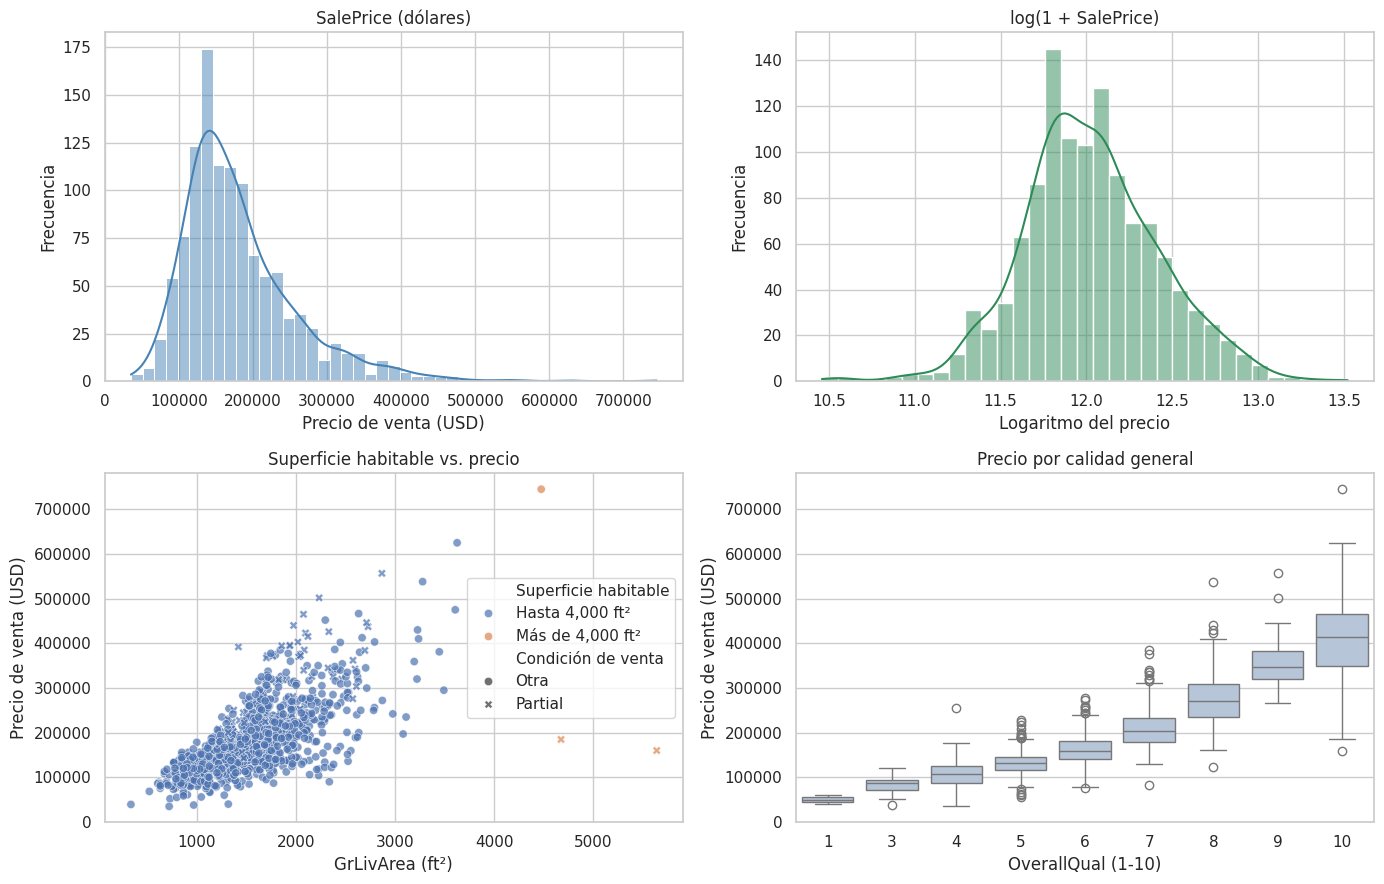

,Sesgo (skewness),Curtosis
SalePrice,1.659,4.896
log(1 + SalePrice),0.109,0.630


In [19]:
# Distribución de la variable objetivo y relación con las variables más asociadas al precio.
precio_log = np.log1p(df_train['SalePrice'])
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df_train['SalePrice'], kde=True, ax=ejes[0, 0], color='steelblue')
ejes[0, 0].set(title='SalePrice (dólares)', xlabel='Precio de venta (USD)', ylabel='Frecuencia')

sns.histplot(precio_log, kde=True, ax=ejes[0, 1], color='seagreen')
ejes[0, 1].set(title='log(1 + SalePrice)', xlabel='Logaritmo del precio', ylabel='Frecuencia')

atipico = (df_train['GrLivArea'] > 4000)
superficie = atipico.map({True: 'Más de 4,000 ft²', False: 'Hasta 4,000 ft²'}).rename('Superficie habitable')
condicion = df_train['SaleCondition'].eq('Partial').map({True: 'Partial', False: 'Otra'}).rename('Condición de venta')
sns.scatterplot(data=df_train, x='GrLivArea', y='SalePrice', hue=superficie, style=condicion, ax=ejes[1, 0], alpha=0.7)
ejes[1, 0].set(title='Superficie habitable vs. precio', xlabel='GrLivArea (ft²)', ylabel='Precio de venta (USD)')

sns.boxplot(data=df_train, x='OverallQual', y='SalePrice', ax=ejes[1, 1], color='lightsteelblue')
ejes[1, 1].set(title='Precio por calidad general', xlabel='OverallQual (1-10)', ylabel='Precio de venta (USD)')
plt.tight_layout()
plt.show()

display(pd.DataFrame({'Sesgo (skewness)': [df_train['SalePrice'].skew(), precio_log.skew()],
                      'Curtosis': [df_train['SalePrice'].kurt(), precio_log.kurt()]},
                     index=['SalePrice', 'log(1 + SalePrice)']).round(3))

<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis de la variable objetivo**

* `SalePrice` es asimétrica a la derecha (**skewness 1.66, curtosis 4.90**). Con `log(1 + SalePrice)` la distribución es prácticamente simétrica (**skewness 0.11, curtosis 0.63**).
* Entrenar sobre el logaritmo tiene dos ventajas: (1) los modelos lineales suponen errores homogéneos, y en dólares el error crece con el precio; (2) un error del 10 % pesa igual en una casa de 100 mil que en una de 500 mil, que es el criterio de la métrica oficial de Kaggle. La comparación empírica está en la **P4**.
* La gráfica de superficie contra precio muestra el patrón descrito por De Cock (2011): **dos casas de más de 4,000 ft² vendidas como `Partial` con precios muy por debajo de la tendencia** (se analizan en la Sección 1.4).
* La mediana del precio crece de forma monótona con `OverallQual`, y la dispersión aumenta en las calidades altas (heterocedasticidad).

</div>

In [20]:
# Asociación monótona (Spearman) de las variables numéricas con el precio.
corr_precio = (df_train[cols_numericas].corr(method='spearman')['SalePrice']
               .drop('SalePrice').sort_values(key=np.abs, ascending=False))
corr_precio = corr_precio.rename('Spearman con SalePrice').to_frame()
display(corr_precio.head(10).round(3))
display(corr_precio.tail(5).round(3))

,Spearman con SalePrice
OverallQual,0.816
GrLivArea,0.714
GarageCars,0.693
YearBuilt,0.658
GarageArea,0.651
FullBath,0.621
TotalBsmtSF,0.607
GarageYrBlt,0.597
YearRemodAdd,0.573
1stFlrSF,0.568


,Spearman con SalePrice
MiscVal,-0.052
BsmtFinSF2,-0.045
YrSold,-0.039
BsmtHalfBath,-0.017
MSSubClass,-0.005


<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis de correlaciones**

* Las variables más asociadas con el precio son la **calidad general** (`OverallQual`, ρ = 0.82), la **superficie habitable** (`GrLivArea`, 0.71), el **garaje** (`GarageCars` 0.69 y `GarageArea` 0.65), la **antigüedad** (`YearBuilt`, 0.66), los baños completos (0.62) y el sótano (`TotalBsmtSF`, 0.61).
* Hay grupos redundantes: `GarageCars` y `GarageArea` miden lo mismo, y `GarageYrBlt` replica a `YearBuilt`. Esto anticipa multicolinealidad, un argumento para usar **regularización** en los modelos lineales.
* `YrSold` (ρ = −0.04) prácticamente no se asocia con el precio, lo cual es evidencia para la P1.

</div>

## **1.4 Valores atípicos**

In [21]:
# Atípicos documentados por el autor del conjunto (De Cock, 2011): casas de más de 4,000 ft².
cols_atipicos = ['Id', 'GrLivArea', 'SalePrice', 'SaleCondition', 'OverallQual', 'Neighborhood']
grandes_train = df_train.loc[df_train['GrLivArea'] > 4000, cols_atipicos].assign(
    precio_por_ft2=lambda d: (d['SalePrice'] / d['GrLivArea']).round(1), Conjunto='Entrenamiento')
grandes_test = df_test.loc[df_test['GrLivArea'] > 4000, cols_atipicos].assign(
    precio_por_ft2=lambda d: (d['SalePrice'] / d['GrLivArea']).round(1), Conjunto='Prueba')
mediana_ft2 = (df_train['SalePrice'] / df_train['GrLivArea']).median()
display(pd.concat([grandes_train, grandes_test]))
display(pd.DataFrame({'Mediana de precio por ft² (entrenamiento)': [round(mediana_ft2, 1)]}))

,Id,GrLivArea,SalePrice,SaleCondition,OverallQual,Neighborhood,precio_por_ft2,Conjunto
523,524,4676,184750,Partial,10,Edwards,39.5,Entrenamiento
1298,1299,5642,160000,Partial,10,Edwards,28.4,Entrenamiento
1182,1183,4476,745000,Abnorml,10,NoRidge,166.4,Entrenamiento
691,692,4316,755000,Normal,10,NoRidge,174.9,Prueba


,Mediana de precio por ft² (entrenamiento)
0,120.3


In [22]:
# Eliminación de las ventas 'Partial' de más de 4,000 ft², solo en el entrenamiento (el conjunto de prueba no cambia).
atipicos = df_train.query("GrLivArea > 4000 and SaleCondition == 'Partial'")
df_train = df_train.drop(index=atipicos.index)
display(pd.DataFrame({'Id eliminados': [atipicos['Id'].tolist()],
                      'Registros de entrenamiento resultantes': [len(df_train)]}))

,Id eliminados,Registros de entrenamiento resultantes
0,"[524, 1299]",1166


<div style="background-color:#FFF4DC; border-left:6px solid #B7791F; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Decisión sobre atípicos**

* En el entrenamiento hay **tres casas de más de 4,000 ft²**. Dos de ellas (**Id 524 y 1299**) son ventas `Partial` de calidad 10 vendidas a **39.5 y 28.4 USD/ft²**, frente a una mediana de **120.3 USD/ft²**: precios que, según el propio autor del conjunto (De Cock, 2011), "probablemente no representan valores reales de mercado". La tercera (Id 1183, 166.4 USD/ft²) es una casa grande con un precio coherente.
* **Se eliminan solo las dos ventas `Partial`** (entrenamiento: 1,166 casas). El criterio es de dominio y está documentado (venta incompleta), no un umbral estadístico ajustado para mejorar métricas. La casa grande con precio coherente se conserva, porque representa un segmento real del mercado.
* **El conjunto de prueba no se modifica.** Incluye la casa Id 692 (4,316 ft², 755,000 USD), y el modelo debe enfrentarla como cualquier caso real. Eliminar atípicos del conjunto de prueba maquillaría el desempeño.

</div>

## **1.5 Valores faltantes: ¿ausencia del elemento o dato perdido?**

In [23]:
# Diagnóstico de valores faltantes: ¿el NA significa "no tiene el elemento" o es un dato realmente perdido?
# Para cada variable se usa una variable de soporte que indica si la casa tiene el elemento.
SOPORTE = {'PoolQC': 'PoolArea', 'MiscFeature': 'MiscVal', 'FireplaceQu': 'Fireplaces',
           'GarageType': 'GarageArea', 'GarageYrBlt': 'GarageArea', 'GarageFinish': 'GarageArea',
           'GarageQual': 'GarageArea', 'GarageCond': 'GarageArea',
           'BsmtQual': 'TotalBsmtSF', 'BsmtCond': 'TotalBsmtSF', 'BsmtExposure': 'TotalBsmtSF',
           'BsmtFinType1': 'TotalBsmtSF', 'BsmtFinType2': 'TotalBsmtSF'}
NA_SEGUN_DICCIONARIO = ['Alley', 'Fence']   # el diccionario define NA = "No alley access" / "No Fence"

filas = []
for var, n in df_train.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False).items():
    if var in SOPORTE:
        sin_elemento = df_train[SOPORTE[var]].eq(0)
        estructural = (df_train[var].isna() & sin_elemento).sum()
        evidencia = f'{SOPORTE[var]} = 0'
    elif var in NA_SEGUN_DICCIONARIO:
        estructural, evidencia = n, 'Definido en data_description.txt'
    else:
        estructural, evidencia = 0, 'Sin significado en el diccionario'
    filas.append({'Variable': var, 'Faltantes': n, '% faltantes': round(n / len(df_train) * 100, 2),
                  'NA estructural (no tiene)': estructural, 'NA real (dato perdido)': n - estructural,
                  'Evidencia': evidencia})
diagnostico_na = pd.DataFrame(filas).set_index('Variable')
display(diagnostico_na)

,Faltantes,% faltantes,NA estructural (no tiene),NA real (dato perdido),Evidencia
Variable,,,,,
PoolQC,1161,99.57,1161,0,PoolArea = 0
MiscFeature,1127,96.66,1127,0,MiscVal = 0
Alley,1093,93.74,1093,0,Definido en data_description.txt
Fence,942,80.79,942,0,Definido en data_description.txt
FireplaceQu,551,47.26,551,0,Fireplaces = 0
LotFrontage,212,18.18,0,212,Sin significado en el diccionario
GarageType,64,5.49,64,0,GarageArea = 0
GarageYrBlt,64,5.49,64,0,GarageArea = 0
GarageFinish,64,5.49,64,0,GarageArea = 0


<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis de los valores faltantes**

Se distinguen **dos tipos de NA**, y tratarlos igual sería un error metodológico:

| Tipo | Variables | Evidencia | Tratamiento |
|---|---|---|---|
| **Estructural**: la casa no tiene el elemento | `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, garaje (5), sótano (5) | En **todos** los casos la variable de soporte vale 0: sin alberca, sin chimenea, sin garaje o sin sótano | Categoría explícita **`None`** (información, no ausencia de dato) |
| **Real**: dato perdido | `LotFrontage` (212), `MasVnrType` y `MasVnrArea` (6), `BsmtExposure` y `BsmtFinType2` (1 cada una) | El diccionario no asigna significado al NA, o la casa sí tiene el elemento (sótano con área > 0) | **Imputación** dentro del pipeline (P4) |

* El caso del sótano muestra por qué el diagnóstico debe hacerse fila por fila: de los 29 NA de `BsmtExposure`, **28 son casas sin sótano**, pero **1 casa sí tiene sótano** y le falta el dato. Rellenar ese caso con `None` sería afirmar algo falso.
* `GarageYrBlt` tiene 64 NA estructurales: una casa sin garaje no tiene año de construcción del garaje (decisión en la P2).

</div>

In [24]:
# Consistencia entre el tipo y el área de recubrimiento de mampostería (solo entrenamiento).
inconsistencias = pd.concat({
    "Tipo 'None' con área > 0": df_train.loc[df_train['MasVnrType'].eq('None') & df_train['MasVnrArea'].gt(0), ['Id', 'MasVnrType', 'MasVnrArea']],
    'Tipo con recubrimiento y área = 0': df_train.loc[df_train['MasVnrType'].notna() & df_train['MasVnrType'].ne('None') & df_train['MasVnrArea'].eq(0), ['Id', 'MasVnrType', 'MasVnrArea']],
}, names=['Inconsistencia', 'Índice'])
display(inconsistencias)
display(pd.DataFrame({'Registros inconsistentes': [len(inconsistencias)],
                      '% del entrenamiento': [round(len(inconsistencias) / len(df_train) * 100, 2)]}))

Id MasVnrType  MasVnrArea
Inconsistencia                    Índice                             
Tipo 'None' con área > 0          624      625       None       288.0
                                  773      774       None         1.0
                                  1230    1231       None         1.0
                                  1300    1301       None       344.0
                                  1334    1335       None       312.0
Tipo con recubrimiento y área = 0 1241    1242      Stone         0.0
                                  688      689    BrkFace         0.0

,Registros inconsistentes,% del entrenamiento
0,7,0.6


<div style="background-color:#FFF4DC; border-left:6px solid #B7791F; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Decisión sobre las inconsistencias de `MasVnrType` y `MasVnrArea`**

* Hay **7 registros (0.6 % del entrenamiento)** donde el tipo y el área del recubrimiento se contradicen: 5 casas con tipo `None` pero área positiva (dos con apenas 1 ft² y tres con 288 a 344 ft²), y 2 casas con un tipo de recubrimiento (`Stone`, `BrkFace`) pero área 0.
* **Se conservan sin modificar.** Con los datos disponibles no hay forma de saber cuál de los dos campos es el erróneo: el tipo podría estar mal capturado o el área podría ser un error de captura. Cualquier corrección sería **inventar información**. Por su bajo número, su efecto sobre los modelos es despreciable, y quedan documentadas para una futura depuración con la fuente original (la oficina de avalúos).

</div>

# **2. Restricciones temporales (P1, P2 y P3)**

La siguiente celda define las **funciones que implementan las decisiones** del cuaderno, para reutilizarlas de forma idéntica en cada experimento y modelo. Cada decisión se justifica con evidencia en la pregunta correspondiente.

* **`preparar`**: transformaciones fila por fila (P1, P2, P3 y el NA estructural de la P5). No usa estadísticas del conjunto (medias, frecuencias), por lo que puede aplicarse a entrenamiento y prueba **sin fuga de información**.
* **`construir_preprocesador`**: imputación, codificación y transformación (P4 y P6). Al vivir dentro de un `Pipeline`, se ajusta **solo con los datos de entrenamiento de cada fold**.
* **`armar_modelo`**: une el preprocesador y el modelo, y transforma el objetivo con logaritmo más estandarización mediante `TransformedTargetRegressor`. Las predicciones regresan automáticamente a dólares.

In [25]:
# Año actual obtenido por código; la actividad fija las edades con respecto a 2026.
ANIO_ACTUAL = date.today().year
assert ANIO_ACTUAL == 2026, 'Las edades deben calcularse con respecto a 2026 (fecha del sistema distinta).'

# Variables que se rellenan con 'None' SOLO cuando la variable de soporte confirma que no hay elemento.
SIN_ELEMENTO = {'TotalBsmtSF': ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2'],
                'GarageArea': ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond'],
                'PoolArea': ['PoolQC'], 'Fireplaces': ['FireplaceQu'], 'MiscVal': ['MiscFeature']}


def preparar(datos, opcion_mosold):
    """Transformaciones fila a fila (sin estadísticas del conjunto, por lo que no generan fuga)."""
    d = datos.drop(columns=['Id', 'YrSold', 'SalePrice'], errors='ignore').copy()      # P1
    d['AgeHouse'] = ANIO_ACTUAL - d['YearBuilt']                                        # P2
    d['AgeRemod'] = ANIO_ACTUAL - d['YearRemodAdd']
    d = d.drop(columns=['YearBuilt', 'YearRemodAdd', 'GarageYrBlt'])
    if opcion_mosold == 'eliminar':                                                     # P3
        d = d.drop(columns='MoSold')
    elif opcion_mosold == 'categorica':
        d['MoSold'] = d['MoSold'].astype(str)
    elif opcion_mosold == 'ciclica':
        d['MoSold_sin'] = np.sin(2 * np.pi * d['MoSold'] / 12)
        d['MoSold_cos'] = np.cos(2 * np.pi * d['MoSold'] / 12)
        d = d.drop(columns='MoSold')
    d['MSSubClass'] = d['MSSubClass'].astype(str)          # código de tipo de vivienda: nominal
    for soporte, columnas in SIN_ELEMENTO.items():          # P5: NA estructural -> categoría 'None'
        sin_elemento = d[soporte].eq(0)
        for c in columnas:
            d.loc[sin_elemento & d[c].isna(), c] = 'None'
    d[['Alley', 'Fence']] = d[['Alley', 'Fence']].fillna('None')
    return d


def construir_preprocesador(X, modelo_arbol=False, transformacion='yeo-johnson',
                            imputacion='median', drop=None, ordinales_como='ordinal'):
    """ColumnTransformer: numéricas, ordinales y nominales. Se ajusta dentro de cada fold."""
    numericas = X.select_dtypes(include='number').columns.tolist()
    ordinales = [c for c in ORDINALES if c in X.columns] if ordinales_como == 'ordinal' else []
    nominales = [c for c in X.columns if c not in numericas + ordinales]
    pasos_num = [('imputar', SimpleImputer(strategy=imputacion))]
    pasos_ord = [('imputar', SimpleImputer(strategy='most_frequent')),
                 ('codificar', OrdinalEncoder(categories=[ORDINALES[c] for c in ordinales]))]
    if not modelo_arbol:     # los árboles son invariantes a transformaciones monótonas
        if transformacion == 'yeo-johnson':     # standardize=True por omisión: no requiere escalador extra
            pasos_num.append(('transformar', PowerTransformer(method='yeo-johnson')))
        elif transformacion == 'estandarizar':
            pasos_num.append(('transformar', StandardScaler()))
        pasos_ord.append(('estandarizar', StandardScaler()))
    pasos_nom = [('imputar', SimpleImputer(strategy='most_frequent')),
                 ('one_hot', OneHotEncoder(drop=drop, handle_unknown='ignore', sparse_output=False))]
    return ColumnTransformer([('num', Pipeline(pasos_num), numericas),
                              ('ord', Pipeline(pasos_ord), ordinales),
                              ('nom', Pipeline(pasos_nom), nominales)])


def armar_modelo(modelo, X, modelo_arbol=False, objetivo='log', **opciones):
    """Pipeline completo; el objetivo se transforma (log + estandarización) y se regresa a dólares."""
    flujo = Pipeline([('prepro', construir_preprocesador(X, modelo_arbol, **opciones)), ('modelo', modelo)])
    pasos_y = [('estandarizar', StandardScaler())]
    if objetivo == 'log':
        pasos_y.insert(0, ('log', FunctionTransformer(np.log1p, inverse_func=np.expm1)))
    return TransformedTargetRegressor(regressor=flujo, transformer=Pipeline(pasos_y))


def rmse_cv(estimador, X, y, cv):
    """RMSE (dólares) promedio y desviación estándar en validación cruzada."""
    puntajes = -cross_val_score(estimador, X, y, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    return puntajes.mean(), puntajes.std()


y_train, y_test = df_train['SalePrice'], df_test['SalePrice']
CV = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
CV_REPETIDA = RepeatedKFold(n_splits=N_FOLDS, n_repeats=3, random_state=RANDOM_STATE)   # para decisiones

# Modelos de referencia (hiperparámetros fijos) para comparar decisiones de preprocesamiento.
def ref_lineal(): return Ridge(alpha=10)
def ref_svr(): return SVR(C=3, gamma=1e-3, epsilon=0.1)
def ref_arbol(): return XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.8,
                                     colsample_bytree=0.5, random_state=RANDOM_STATE, n_jobs=1)

## **P1. Decisión sobre la variable `YrSold`**

In [26]:
# P1. ¿Existe una tendencia del precio con el año de venta? (solo entrenamiento)
resumen_anio = df_train.groupby('YrSold')['SalePrice'].agg(Ventas='count', Mediana='median', Media='mean').round(0)
display(resumen_anio)
grupos = [g['SalePrice'].values for _, g in df_train.groupby('YrSold')]
kruskal = stats.kruskal(*grupos)
display(pd.DataFrame({'Estadístico H (Kruskal-Wallis)': [round(kruskal.statistic, 3)],
                      'p-valor': [round(kruskal.pvalue, 4)],
                      'Spearman YrSold vs SalePrice': [round(df_train['YrSold'].corr(df_train['SalePrice'], method='spearman'), 4)]}))

,Ventas,Mediana,Media
YrSold,,,
2006,252,165000.0,187144.0
2007,254,162750.0,183248.0
2008,243,165000.0,177699.0
2009,282,162750.0,177952.0
2010,135,155000.0,177058.0


,Estadístico H (Kruskal-Wallis),p-valor,Spearman YrSold vs SalePrice
0,1.888,0.7564,-0.039


<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P1. Se elimina `YrSold`**

**Decisión: eliminar `YrSold`.**

1. **Restricción del problema.** La valuación se plantea en un **plano temporal estático**: el modelo debe estimar el precio a partir de las características de la casa, no del calendario. `YrSold` es una tendencia cronológica absoluta, y un modelo entrenado con ella aprendería "cuánto valía el mercado en 2006-2010", algo que no puede extrapolarse a 2026 ni a ningún otro año.
2. **Evidencia de los datos.** La mediana del precio es prácticamente igual en los cinco años (entre **155,000 y 165,000 USD**). La prueba de Kruskal-Wallis **no detecta diferencias** entre años (H = 1.89, **p = 0.76**), y la correlación de Spearman es casi nula (**ρ = −0.04**). Eliminarla no sacrifica capacidad predictiva.
3. **Riesgo de conservarla.** Cualquier casa nueva tendría un valor de `YrSold` fuera del rango observado (2006-2010). Los modelos de árboles lo tratarían como "2010" y los lineales lo extrapolarían, introduciendo un sesgo sin fundamento.

</div>

## **P2. Decisión sobre `YearBuilt` y `YearRemodAdd`**

In [27]:
# P2. Transformación de años calendario a edades relativas a 2026 y análisis de redundancia.
edades = pd.DataFrame({'YearBuilt': df_train['YearBuilt'], 'AgeHouse': ANIO_ACTUAL - df_train['YearBuilt'],
                       'YearRemodAdd': df_train['YearRemodAdd'], 'AgeRemod': ANIO_ACTUAL - df_train['YearRemodAdd'],
                       'GarageYrBlt': df_train['GarageYrBlt'], 'SalePrice': df_train['SalePrice']})
display(pd.DataFrame({'Año actual (calculado por código)': [ANIO_ACTUAL]}))
display(edades[['AgeHouse', 'AgeRemod']].describe().T.round(1))
display(edades.corr(method='pearson').round(3))

con_garaje = df_train['GarageYrBlt'].notna()
display(pd.DataFrame({
    'Casas sin garaje (GarageYrBlt faltante)': [(~con_garaje).sum()],
    '% con GarageYrBlt = YearBuilt': [round((df_train.loc[con_garaje, 'GarageYrBlt'] == df_train.loc[con_garaje, 'YearBuilt']).mean() * 100, 1)],
    'Correlación GarageYrBlt-YearBuilt': [round(df_train['GarageYrBlt'].corr(df_train['YearBuilt']), 3)]}))

,Año actual (calculado por código)
0,2026


,count,mean,std,min,25%,50%,75%,max
AgeHouse,1166.0,54.7,30.1,16.0,26.0,54.0,72.0,154.0
AgeRemod,1166.0,41.1,20.6,16.0,22.0,32.5,59.0,76.0


,YearBuilt,AgeHouse,YearRemodAdd,AgeRemod,GarageYrBlt,SalePrice
YearBuilt,1.000,-1.000,0.594,-0.594,0.828,0.537
AgeHouse,-1.000,1.000,-0.594,0.594,-0.828,-0.537
YearRemodAdd,0.594,-0.594,1.000,-1.000,0.640,0.518
AgeRemod,-0.594,0.594,-1.000,1.000,-0.640,-0.518
GarageYrBlt,0.828,-0.828,0.640,-0.640,1.000,0.498
SalePrice,0.537,-0.537,0.518,-0.518,0.498,1.000


,Casas sin garaje (GarageYrBlt faltante),% con GarageYrBlt = YearBuilt,Correlación GarageYrBlt-YearBuilt
0,64,79.2,0.828


<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P2. Edades relativas a 2026 y eliminación de los años originales**

**Decisión:** `AgeHouse = 2026 − YearBuilt` y `AgeRemod = 2026 − YearRemodAdd`, con el año actual **obtenido por código** y verificado como 2026.

**Justificación de la transformación.**
* Una fecha calendario es un dato absoluto. Lo que influye en el valor de una casa es su **antigüedad** (desgaste, estándares de construcción, necesidad de mantenimiento) y el **tiempo desde su última remodelación**. Expresarlo como edad es coherente con la valuación estática y mantiene el significado si el modelo se aplica en otro año.
* La edad es interpretable directamente para el negocio: en la P10, cada desviación estándar de antigüedad transformada se asocia con una reducción de 4.7 % en el precio.

**¿Se conservan los años originales? No, se eliminan.**
* `YearBuilt` y `AgeHouse` tienen **correlación exactamente −1.000** (igual para `YearRemodAdd` y `AgeRemod`): son la misma información con signo opuesto. Conservar ambas crea **multicolinealidad perfecta**: en un modelo lineal, los coeficientes de esas dos variables no se pueden estimar por separado y pierden interpretabilidad. En los árboles, la importancia se repartiría artificialmente entre dos copias de la misma variable.
* Mantener el año calendario reintroduciría la referencia temporal absoluta que la restricción busca eliminar.
* Las **nuevas** variables sí se conservan como entradas: conservan la asociación con el precio (ρ = −0.54 para `AgeHouse` y −0.52 para `AgeRemod`).

**Decisión adicional: `GarageYrBlt` también se elimina.** El enunciado no la menciona, pero es otro año calendario y debe recibir el mismo tratamiento. Convertirla en edad no aporta información nueva: tiene correlación de **0.83** con `YearBuilt` y en el **79.2 %** de las casas con garaje es **idéntica** al año de construcción. Además, sus **64 NA estructurales** (casas sin garaje) obligarían a imputar la "edad" de un garaje inexistente. La presencia y calidad del garaje ya se describen con `GarageType`, `GarageCars`, `GarageArea`, `GarageFinish`, `GarageQual` y `GarageCond`.

</div>

## **P3. Decisión sobre la variable `MoSold`**

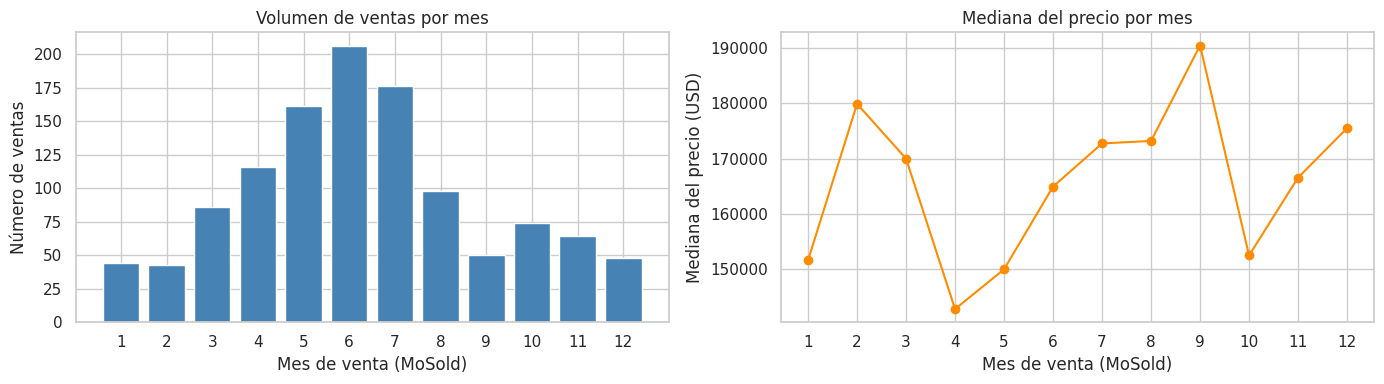

MoSold,1,2,3,4,5,6,7,8,9,10,11,12
Ventas,44.0,43.0,86.0,116.0,161.0,206.0,176.0,98.0,50.0,74.0,64.0,48.0
Mediana,151650.0,179900.0,170000.0,142812.0,150000.0,164950.0,172750.0,173200.0,190450.0,152500.0,166575.0,175500.0
% de ventas,3.8,3.7,7.4,9.9,13.8,17.7,15.1,8.4,4.3,6.3,5.5,4.1


,Spearman MoSold vs SalePrice,p-valor Kruskal-Wallis (precio entre meses)
0,0.0665,0.0468


In [28]:
# P3. Comportamiento del mes de venta (solo entrenamiento).
resumen_mes = df_train.groupby('MoSold')['SalePrice'].agg(Ventas='count', Mediana='median').round(0)
resumen_mes['% de ventas'] = (resumen_mes['Ventas'] / resumen_mes['Ventas'].sum() * 100).round(1)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
ejes[0].bar(resumen_mes.index, resumen_mes['Ventas'], color='steelblue')
ejes[0].set(title='Volumen de ventas por mes', xlabel='Mes de venta (MoSold)', ylabel='Número de ventas', xticks=range(1, 13))
ejes[1].plot(resumen_mes.index, resumen_mes['Mediana'], marker='o', color='darkorange')
ejes[1].set(title='Mediana del precio por mes', xlabel='Mes de venta (MoSold)', ylabel='Mediana del precio (USD)', xticks=range(1, 13))
plt.tight_layout()
plt.show()

display(resumen_mes.T)
display(pd.DataFrame({'Spearman MoSold vs SalePrice': [round(df_train['MoSold'].corr(df_train['SalePrice'], method='spearman'), 4)],
                      'p-valor Kruskal-Wallis (precio entre meses)': [round(stats.kruskal(*[g['SalePrice'].values for _, g in df_train.groupby('MoSold')]).pvalue, 4)]}))

<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis descriptivo del mes de venta**

* **El mes influye mucho más en el volumen de ventas que en el precio.** Mayo, junio y julio concentran el **46.6 %** de las operaciones (junio: 17.7 %), mientras que enero y febrero apenas representan el 3.8 % y el 3.7 %, respectivamente. Es la estacionalidad típica del mercado inmobiliario de Estados Unidos (mudanzas en verano, fuera del ciclo escolar).
* La mediana del precio fluctúa entre **142,812 USD (abril)** y **190,450 USD (septiembre)** sin una tendencia clara. La asociación monótona es casi nula (**ρ = 0.07**), pero la prueba de Kruskal-Wallis es marginalmente significativa (**p = 0.047**): existen diferencias entre meses, aunque no siguen un patrón lineal de enero a diciembre.
* Este resultado anticipa el problema de la codificación numérica: tratar `MoSold` como número supone que diciembre (12) está "lejos" de enero (1), cuando en el calendario son meses consecutivos.
**Limitación** Se debe considerar que el mes efectivo de venta no necesariamente se conoce al momento de realizar una valuación, por lo que habría que considerar su disponibilidad en una aplicación real.

</div>

In [29]:
# P3. Comparación empírica de las cuatro opciones para MoSold (CV repetida 5x3, solo entrenamiento).
resultados_mosold = []
for opcion in ['numerica', 'eliminar', 'categorica', 'ciclica']:
    X_op = preparar(df_train, opcion)
    for nombre, modelo, arbol in [('Ridge (lineal)', ref_lineal(), False), ('XGBoost (árboles)', ref_arbol(), True)]:
        media, desv = rmse_cv(armar_modelo(modelo, X_op, modelo_arbol=arbol), X_op, y_train, CV_REPETIDA)
        resultados_mosold.append({'Opción MoSold': opcion, 'Modelo': nombre, 'RMSE': media, 'Desv. estándar': desv})

tabla_mosold = pd.DataFrame(resultados_mosold).pivot(index='Opción MoSold', columns='Modelo', values=['RMSE', 'Desv. estándar'])
tabla_mosold[('Diferencia vs. mejor (%)', 'Ridge (lineal)')] = (tabla_mosold[('RMSE', 'Ridge (lineal)')] / tabla_mosold[('RMSE', 'Ridge (lineal)')].min() - 1) * 100
tabla_mosold[('Diferencia vs. mejor (%)', 'XGBoost (árboles)')] = (tabla_mosold[('RMSE', 'XGBoost (árboles)')] / tabla_mosold[('RMSE', 'XGBoost (árboles)')].min() - 1) * 100
display(tabla_mosold.round(2))

RMSE                   Desv. estándar                   Diferencia vs. mejor (%)                  
Modelo        Ridge (lineal) XGBoost (árboles) Ridge (lineal) XGBoost (árboles)           Ridge (lineal) XGBoost (árboles)
Opción MoSold                                                                                                             
categorica          20389.10          22711.79        1789.89           3443.06                     0.55              0.85
ciclica             20278.01          22520.52        1791.73           3483.36                     0.00              0.00
eliminar            20312.90          22803.56        1825.90           3610.19                     0.17              1.26
numerica            20316.89          23020.45        1826.36           3584.17                     0.19              2.22

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P3. `MoSold` se transforma de forma cíclica (seno y coseno)**

**Opciones evaluadas** con validación cruzada repetida (5 folds × 3 repeticiones, solo entrenamiento) y dos familias de modelos, para no depender de un solo algoritmo:

| Opción | Ridge (lineal) | XGBoost (árboles) |
|---|---|---|
| **Cíclica (sen, cos)** | **20,278** (mejor) | **22,521** (mejor) |
| Eliminar | +0.17 % | +1.26 % |
| Numérica | +0.19 % | +2.22 % |
| Categórica | +0.55 % | +0.85 % |

**Decisión, tomada por código** (rango promedio en ambas familias de modelos; la cíclica obtiene 1.0, es decir, es la primera en las dos): **transformación cíclica**, `MoSold_sin = sin(2π·mes/12)` y `MoSold_cos = cos(2π·mes/12)`.
* Es la **única opción que obtiene el menor RMSE en ambas familias de modelos**. Las diferencias son pequeñas frente a la variabilidad entre folds (≈1.8k y ≈3.5k USD), lo cual es coherente con un efecto estacional débil, pero consistente (Kruskal-Wallis p = 0.047).
* **Conceptualmente es la representación correcta de una variable circular:** con seno y coseno, diciembre y enero quedan contiguos y todos los meses equidistan de sus vecinos. La codificación numérica impone una distancia falsa (12 − 1 = 11), y la categórica usa 12 columnas sin ninguna noción de cercanía entre meses, con mayor riesgo de sobreajuste.
* **Es compatible con la valuación estática:** a diferencia de `YrSold`, el mes no es una tendencia cronológica absoluta, sino un patrón estacional que se repite cada año. Al valuar una casa se usa el mes previsto de la operación.

**¿Se elimina la variable original? Sí.** `MoSold_sin` y `MoSold_cos` son funciones deterministas de `MoSold` y contienen toda su información: el par (sen, cos) identifica cada mes de forma única. Conservar la original agregaría una tercera representación **redundante**, reintroduciría la distancia artificial entre diciembre y enero que justamente se quiere corregir, y repartiría la importancia entre variables equivalentes. Se necesitan **ambas** componentes: solo con el seno, enero y mayo quedarían con el mismo valor.

</div>

In [30]:
# Decisión de la P3 por código: la opción con el mejor rango promedio en ambas familias de modelos.
rango_promedio = tabla_mosold['RMSE'].rank().mean(axis=1).sort_values()
OPCION_MOSOLD = rango_promedio.idxmin()
display(rango_promedio.rename('Rango promedio (1 = mejor)').to_frame())
display(pd.DataFrame({'Opción elegida para MoSold': [OPCION_MOSOLD]}))

X_train = preparar(df_train, OPCION_MOSOLD)
X_test = preparar(df_test, OPCION_MOSOLD)
display(pd.DataFrame({'Conjunto': ['Entrenamiento', 'Prueba'], 'Filas': [X_train.shape[0], X_test.shape[0]],
                      'Variables de entrada': [X_train.shape[1], X_test.shape[1]]}))
display(X_train.head())
display(X_train.tail())

,Rango promedio (1 = mejor)
Opción MoSold,
ciclica,1.0
eliminar,2.5
categorica,3.0
numerica,3.5


,Opción elegida para MoSold
0,ciclica


,Conjunto,Filas,Variables de entrada
0,Entrenamiento,1166,78
1,Prueba,292,78


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,SaleType,SaleCondition,AgeHouse,AgeRemod,MoSold_sin,MoSold_cos
598,20,RL,80.0,12984,Pave,None,Reg,Bnk,AllPub,Inside,Gtl,Crawfor,Norm,Norm,1Fam,1Story,5,6,Gable,CompShg,Plywood,Plywood,BrkFace,459.0,TA,TA,CBlock,Gd,TA,Mn,ALQ,1283,LwQ,147,0,1430,GasA,Ex,Y,SBrkr,1647,0,0,1647,1,0,2,0,3,1,Gd,7,Typ,1,TA,Attchd,Fin,2,621,TA,TA,Y,0,0,0,0,0,0,None,None,None,0,WD,Normal,49,49,1.000000e+00,6.123234e-17
324,80,RL,96.0,11275,Pave,None,Reg,Lvl,AllPub,Corner,Gtl,NAmes,PosN,Norm,1Fam,SLvl,7,7,Mansard,WdShake,Wd Sdng,Wd Sdng,BrkFace,300.0,Gd,Gd,CBlock,Gd,TA,No,Unf,0,Unf,0,710,710,GasA,Ex,Y,SBrkr,1898,1080,0,2978,0,0,2,1,5,1,Gd,11,Typ,1,Gd,BuiltIn,Fin,2,564,TA,TA,Y,240,0,0,0,0,0,None,None,None,0,WD,Normal,59,19,1.224647e-16,-1.000000e+00
1145,50,RM,52.0,6240,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,Norm,1Fam,1.5Fin,5,6,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0,Unf,0,1042,1042,GasA,Ex,Y,SBrkr,1042,534,0,1576,0,0,1,0,3,1,TA,8,Typ,1,Gd,Detchd,Unf,1,225,TA,TA,Y,0,0,0,0,0,0,None,None,None,0,WD,Family,98,76,-8.660254e-01,-5.000000e-01
477,60,RL,105.0,13693,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,NridgHt,Norm,Norm,1Fam,2Story,9,5,Hip,CompShg,VinylSd,VinylSd,BrkFace,772.0,Ex,TA,PConc,Gd,TA,Av,Unf,0,Unf,0,2153,2153,GasA,Ex,Y,SBrkr,2069,574,0,2643,0,0,2,1,3,1,Ex,9,Typ,1,Gd,BuiltIn,Fin,3,694,TA,TA,Y,414,84,0,0,0,0,None,None,None,0,WD,Normal,20,20,1.000000e+00,6.123234e-17
641,60,FV,NaN,7050,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,1Fam,2Story,7,5,Gable,CompShg,VinylSd,VinylSd,None,0.0,Gd,TA,PConc,Gd,TA,No,GLQ,738,Unf,0,319,1057,GasA,Ex,Y,SBrkr,1057,872,0,1929,1,0,2,1,3,1,Gd,7,Typ,1,TA,Attchd,Fin,2,650,TA,TA,Y,0,235,0,0,0,0,None,None,None,0,WD,Normal,25,25,5.000000e-01,-8.660254e-01


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,SaleType,SaleCondition,AgeHouse,AgeRemod,MoSold_sin,MoSold_cos
1271,20,RL,NaN,9156,Pave,None,IR1,Lvl,AllPub,Inside,Gtl,NWAmes,PosN,Norm,1Fam,1Story,6,7,Hip,CompShg,BrkFace,BrkFace,None,0.0,TA,TA,CBlock,TA,TA,No,Unf,0,Unf,0,1489,1489,GasA,Gd,Y,SBrkr,1489,0,0,1489,0,0,2,0,3,1,Gd,7,Typ,1,Gd,Attchd,RFn,2,462,TA,TA,Y,0,0,0,0,0,0,None,None,None,0,WD,Normal,58,58,-0.866025,-0.500000
11,60,RL,85.0,11924,Pave,None,IR1,Lvl,AllPub,Inside,Gtl,NridgHt,Norm,Norm,1Fam,2Story,9,5,Hip,CompShg,WdShing,Wd Shng,Stone,286.0,Ex,TA,PConc,Ex,TA,No,GLQ,998,Unf,0,177,1175,GasA,Ex,Y,SBrkr,1182,1142,0,2324,1,0,3,0,4,1,Ex,11,Typ,2,Gd,BuiltIn,Fin,3,736,TA,TA,Y,147,21,0,0,0,0,None,None,None,0,New,Partial,21,20,-0.500000,-0.866025
849,80,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,SLvl,6,7,Hip,CompShg,Plywood,Plywood,BrkFace,360.0,Gd,Gd,CBlock,TA,TA,No,Unf,0,Unf,0,528,528,GasA,Ex,Y,SBrkr,1094,761,0,1855,0,0,2,1,3,1,TA,7,Typ,1,TA,Attchd,RFn,2,512,TA,TA,Y,113,100,0,0,0,0,None,None,None,0,WD,Normal,50,32,-0.866025,-0.500000
466,20,RL,85.0,10628,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,Flat,Tar&Grv,Plywood,Plywood,None,0.0,TA,Gd,CBlock,TA,Gd,Gd,GLQ,778,Unf,0,499,1277,GasA,TA,Y,SBrkr,1277,0,0,1277,1,0,1,0,2,1,TA,5,Typ,1,Po,Attchd,Unf,2,526,TA,TA,Y,0,0,0,0,176,0,None,GdWo,None,0,WD,Normal,56,56,0.866025,-0.500000
27,20,RL,98.0,11478,Pave,None,Reg,Lvl,AllPub,Inside,Gtl,NridgHt,Norm,Norm,1Fam,1Story,8,5,Gable,CompShg,VinylSd,VinylSd,Stone,200.0,Gd,TA,PConc,Ex,TA,No,GLQ,1218,Unf,0,486,1704,GasA,Ex,Y,SBrkr,1704,0,0,1704,1,0,2,0,3,1,Gd,7,Typ,1,Gd,Attchd,RFn,3,772,TA,TA,Y,0,50,0,0,0,0,None,None,None,0,WD,Normal,19,18,0.500000,-0.866025


# **3. Limpieza y preprocesamiento (P4, P5 y P6)**

## **P4. Análisis, limpieza, imputación y transformaciones**

In [31]:
# P4. Tipos de variable finales y faltantes que quedan para el imputador (solo entrenamiento).
num_final = X_train.select_dtypes(include='number').columns
ord_final = [c for c in ORDINALES if c in X_train.columns]
nom_final = [c for c in X_train.columns if c not in list(num_final) + ord_final]
display(pd.DataFrame({'Grupo': ['Numéricas', 'Ordinales', 'Nominales'],
                      'Número de variables': [len(num_final), len(ord_final), len(nom_final)],
                      'Tratamiento (modelos no basados en árboles)': [
                          'Mediana + Yeo-Johnson o estandarización (elegida por CV en la P9)', 'Moda + OrdinalEncoder + StandardScaler',
                          'Moda + OneHotEncoder'],
                      'Tratamiento (árboles)': ['Mediana', 'Moda + OrdinalEncoder', 'Moda + OneHotEncoder']}))
faltantes_restantes = X_train.isna().sum().loc[lambda s: s > 0]
display(faltantes_restantes.rename('Faltantes reales por imputar').to_frame())

,Grupo,Número de variables,Tratamiento (modelos no basados en árboles),Tratamiento (árboles)
0,Numéricas,34,Mediana + Yeo-Johnson o estandarización (elegi...,Mediana
1,Ordinales,19,Moda + OrdinalEncoder + StandardScaler,Moda + OrdinalEncoder
2,Nominales,25,Moda + OneHotEncoder,Moda + OneHotEncoder


,Faltantes reales por imputar
LotFrontage,212
MasVnrType,6
MasVnrArea,6
BsmtExposure,1
BsmtFinType2,1


In [32]:
# P4. Comparación de estrategias de imputación numérica: media, mediana y moda.
resultados_imp = []
for estrategia in ['mean', 'median', 'most_frequent']:
    fila = {'Imputación numérica': estrategia}
    for nombre, modelo in [('Ridge', ref_lineal()), ('SVR', ref_svr())]:
        fila[f'RMSE {nombre}'], fila[f'Desv. {nombre}'] = rmse_cv(armar_modelo(modelo, X_train, imputacion=estrategia), X_train, y_train, CV_REPETIDA)
    resultados_imp.append(fila)
display(pd.DataFrame(resultados_imp).set_index('Imputación numérica').round(1))

# Evidencia adicional: sesgo de LotFrontage (variable con más faltantes reales).
display(pd.DataFrame({'Media': [X_train['LotFrontage'].mean()], 'Mediana': [X_train['LotFrontage'].median()],
                      'Moda': [X_train['LotFrontage'].mode()[0]], 'Skewness': [X_train['LotFrontage'].skew()]},
                     index=['LotFrontage']).round(2))

,RMSE Ridge,Desv. Ridge,RMSE SVR,Desv. SVR
Imputación numérica,,,,
mean,20279.9,1785.7,23719.7,6987.2
median,20278.0,1791.7,23721.4,6993.5
most_frequent,20274.3,1791.6,23712.3,6977.2


,Media,Mediana,Moda,Skewness
LotFrontage,69.41,69.0,60.0,0.79


<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis de la imputación**

* Las tres estrategias producen **RMSE prácticamente idénticos** (diferencias menores al 0.04 %, muy por debajo de la desviación entre folds de ≈1.8k USD en Ridge y ≈7.0k USD en SVR). Es esperable: solo quedan **218 valores numéricos por imputar** (212 de `LotFrontage` y 6 de `MasVnrArea`), más 8 categóricos, ya que los NA estructurales se resolvieron antes.
* Ante las diferencias pequeñas, el criterio decisivo es conceptual: **la mediana es robusta a la asimetría y a los atípicos**. `LotFrontage` tiene un máximo de 313 ft frente a una mediana de 69 y una curtosis de 13.2, y la moda (60) se aleja del centro de la distribución.
* **Decisión:** mediana para las numéricas y moda para las ordinales y nominales (`MasVnrType`, `BsmtExposure`, `BsmtFinType2`), la única medida de tendencia central válida para variables categóricas. Para `MasVnrArea` la mediana es 0, coherente con su categoría más frecuente (`None`).

</div>

In [33]:
# P4. Comparación de transformaciones numéricas y del objetivo (modelos sensibles a la escala).
opciones = [('Sin transformar', 'ninguna', 'log'), ('Estandarizar', 'estandarizar', 'log'),
            ('Yeo-Johnson', 'yeo-johnson', 'log'), ('Yeo-Johnson, objetivo SIN log', 'yeo-johnson', 'escala')]
resultados_tr = []
for etiqueta, transf, objetivo in opciones:
    fila = {'Configuración': etiqueta}
    for nombre, modelo in [('Ridge', ref_lineal()), ('SVR', ref_svr())]:
        fila[f'RMSE {nombre}'], fila[f'Desv. {nombre}'] = rmse_cv(
            armar_modelo(modelo, X_train, transformacion=transf, objetivo=objetivo), X_train, y_train, CV_REPETIDA)
    resultados_tr.append(fila)
display(pd.DataFrame(resultados_tr).set_index('Configuración').round(1))

# Efecto de Yeo-Johnson sobre el sesgo de las numéricas (ajustado solo con entrenamiento).
X_num = X_train[num_final].fillna(X_train[num_final].median())
X_yj = pd.DataFrame(PowerTransformer(method='yeo-johnson').fit_transform(X_num), columns=num_final)
sesgo = pd.DataFrame({'Skewness original': X_num.skew(), 'Skewness Yeo-Johnson': X_yj.skew().values}).round(2)
display(sesgo.sort_values('Skewness original', key=np.abs, ascending=False).head(10))
display(pd.DataFrame({'Variables con |skewness| > 1': [(sesgo['Skewness original'].abs() > 1).sum(),
                                                        (sesgo['Skewness Yeo-Johnson'].abs() > 1).sum()]},
                     index=['Original', 'Yeo-Johnson']))

,RMSE Ridge,Desv. Ridge,RMSE SVR,Desv. SVR
Configuración,,,,
Sin transformar,20519.4,4033.5,78283.8,7416.2
Estandarizar,20291.7,3229.0,23241.4,6985.5
Yeo-Johnson,20278.0,1791.7,23721.4,6993.5
"Yeo-Johnson, objetivo SIN log",27985.6,4305.1,26504.9,6378.7


,Skewness original,Skewness Yeo-Johnson
MiscVal,19.80,5.20
PoolArea,15.37,15.19
LotArea,12.27,0.01
3SsnPorch,10.98,8.11
LowQualFinSF,9.19,7.45
KitchenAbvGr,4.44,-2.44
BsmtHalfBath,4.26,3.95
ScreenPorch,4.06,3.06
BsmtFinSF2,4.05,2.33
EnclosedPorch,3.05,2.05


,Variables con |skewness| > 1
Original,13
Yeo-Johnson,9


<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis de las transformaciones**

**Variable objetivo: el logaritmo es indispensable.** Sin él, el RMSE empeora **38.0 % en Ridge** (27,986 contra 20,278) y **11.7 % en SVR**, porque los modelos dedican su capacidad a las casas caras y la varianza del error crece con el precio.

**Variables numéricas: no hay una ganadora universal.**
* **Escalar es obligatorio** para los modelos basados en distancias: la SVR sin transformar obtiene un RMSE de **78,284 USD, peor que el modelo base** (77,249), porque `LotArea` (en miles de ft²) domina el kernel RBF y anula al resto de las variables.
* En **Ridge**, Yeo-Johnson obtiene el menor RMSE (20,278) y además **reduce a casi la mitad la variabilidad entre folds** (±1,792 contra ±3,229 al estandarizar): al comprimir colas como la de `LotArea` (skewness de 12.3 a 0.0), evita que unas pocas casas extremas dominen los coeficientes. Las variables con |skewness| > 1 bajan de 13 a 9. Las que siguen sesgadas (`PoolArea`, `3SsnPorch`) son casi constantes en cero, algo que ninguna transformación corrige.
* En **SVR con hiperparámetros fijos**, estandarizar es 2.1 % mejor.

**Decisión:** como la transformación óptima depende del modelo, **se trata como un hiperparámetro más** (`PowerTransformer` o `StandardScaler`) dentro de la búsqueda de cada modelo sensible a la escala en la P9. Así, la decisión final de cada modelo es literalmente la mejor de las consideradas por validación cruzada.

</div>

In [34]:
# P4. Codificación de las ordinales (orden vs. One-Hot) y efecto de quitar las variables casi constantes.
CASI_CONSTANTES = [c for c in X_train.columns if X_train[c].value_counts(normalize=True, dropna=False).iloc[0] >= 0.99]
n_evaluaciones = CV_REPETIDA.get_n_splits()
escenarios = [('Ordinales codificadas en orden (base)', X_train, 'ordinal'),
              ('Ordinales con One-Hot', X_train, 'one_hot'),
              ('Sin variables casi constantes', X_train.drop(columns=CASI_CONSTANTES), 'ordinal')]
filas = []
for etiqueta, X_esc, ordinales_como in escenarios:
    columnas = construir_preprocesador(X_esc, ordinales_como=ordinales_como).fit(X_esc).get_feature_names_out().size
    fila = {'Escenario': etiqueta, 'Columnas generadas': columnas}
    for nombre, modelo, arbol in [('Ridge', ref_lineal(), False), ('XGBoost', ref_arbol(), True)]:
        estimador = armar_modelo(modelo, X_esc, modelo_arbol=arbol, ordinales_como=ordinales_como)
        media, desv = rmse_cv(estimador, X_esc, y_train, CV_REPETIDA)
        fila[f'RMSE {nombre}'], fila[f'Error estándar {nombre}'] = media, desv / np.sqrt(n_evaluaciones)
    filas.append(fila)
tabla_codificacion = pd.DataFrame(filas).set_index('Escenario')
for nombre in ['Ridge', 'XGBoost']:
    base = tabla_codificacion[f'RMSE {nombre}'].iloc[0]
    tabla_codificacion[f'Diferencia vs. base {nombre} (%)'] = (tabla_codificacion[f'RMSE {nombre}'] / base - 1) * 100
    tabla_codificacion[f'¿Diferencia mayor a 1 EE? ({nombre})'] = (tabla_codificacion[f'RMSE {nombre}'] - base).abs() > tabla_codificacion[f'Error estándar {nombre}']
display(tabla_codificacion.round(2))
display(pd.DataFrame({'Variables casi constantes (moda ≥ 99 %)': [CASI_CONSTANTES]}))

,Columnas generadas,RMSE Ridge,Error estándar Ridge,RMSE XGBoost,Error estándar XGBoost,Diferencia vs. base Ridge (%),¿Diferencia mayor a 1 EE? (Ridge),Diferencia vs. base XGBoost (%),¿Diferencia mayor a 1 EE? (XGBoost)
Escenario,,,,,,,,,
Ordinales codificadas en orden (base),232,20278.01,462.62,22520.52,899.40,0.00,False,0.00,False
Ordinales con One-Hot,308,19916.83,412.47,22978.15,931.75,-1.78,False,2.03,False
Sin variables casi constantes,220,20511.76,596.31,22769.76,890.27,1.15,False,1.11,False


,Variables casi constantes (moda ≥ 99 %)
0,"[Street, Utilities, Condition2, PoolArea, PoolQC]"


<div style="background-color:#EAF6EC; border-left:6px solid #2E7D32; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Análisis de la codificación de ordinales y de las variables casi constantes**

**¿Ordinales codificadas en orden o con One-Hot?**
* Con One-Hot, **Ridge mejora 1.8 %** (más flexible: no supone saltos iguales entre niveles), pero **XGBoost empeora 2.0 %** (necesita más cortes para recuperar el orden). Ambas diferencias son **menores que un error estándar** (Ridge: 361 contra 463 USD; XGBoost: 458 contra 899 USD), por lo que ambas quedan dentro del umbral adoptado.
* **Decisión: mantener la codificación ordinal.** Ante diferencias menores que un error estándar se prefiere la opción más simple, con el mismo criterio de la regla de 1 EE que se usa en la P9: **232 columnas contra 308**, conserva el orden del diccionario y es más interpretable (un coeficiente por escala de calidad).

**¿Eliminar las variables casi constantes?** (`Street`, `Utilities`, `Condition2`, `PoolArea` y `PoolQC`, con moda ≥ 99 %)
* Quitarlas **empeora ambos modelos** (Ridge +1.2 %, XGBoost +1.1 %), aunque dentro de un error estándar. Sus pocas observaciones distintas (por ejemplo, las 5 albercas) aportan algo de información. **Decisión: conservarlas.** Ahora la decisión está respaldada con evidencia y no solo con un argumento.

</div>

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P4. Procesamiento de los datos y justificación de cada decisión**

| Paso | Decisión | Justificación (evidencia) |
|---|---|---|
| Lectura | Solo `NA` es faltante | Evita fabricar 864 faltantes falsos en `MasVnrType` (Sección 1) |
| Limpieza de atípicos | Eliminar del entrenamiento las 2 ventas `Partial` de más de 4,000 ft² | Precio de 28 a 40 USD/ft² frente a una mediana de 120; recomendación del autor del conjunto. La prueba no se toca (Sección 1.4) |
| Variables temporales | Eliminar `YrSold`, `GarageYrBlt` y los años originales; crear `AgeHouse` y `AgeRemod`; `MoSold` cíclica | P1, P2 y P3 |
| `MSSubClass` | Nominal | Es un código, no una magnitud |
| NA estructurales | Categoría `None` | Validado fila por fila con la variable de soporte (Sección 1.5 y P5) |
| Imputación numérica | **Mediana** | Empate en RMSE entre media, mediana y moda; la mediana es robusta a la asimetría de `LotFrontage` |
| Imputación categórica | **Moda** | Única medida válida para categorías; afecta a 8 valores |
| Numéricas (modelos lineales, MLP y SVR) | **Yeo-Johnson o estandarización, elegida por CV para cada modelo** | Escalar es imprescindible (SVR sin escalar ≈ modelo base); Yeo-Johnson estabiliza los modelos lineales. Resultado en la P9: lineal y SVR → Yeo-Johnson; MLP → estandarización |
| Numéricas (árboles) | Sin transformar | Los árboles dividen por umbrales y son invariantes a transformaciones monótonas |
| Ordinales (19) | `OrdinalEncoder` con el orden del diccionario, más `StandardScaler` en los modelos no basados en árboles | One-Hot fue −1.8 % en Ridge y +2.0 % en XGBoost, ambos dentro de 1 EE; se prefiere la opción más simple (232 contra 308 columnas), que conserva el orden Po < … < Ex |
| Variables casi constantes (5) | Se conservan | Quitarlas empeora el RMSE en Ridge (+1.2 %) y en XGBoost (+1.1 %) |
| Inconsistencias de `MasVnrType`/`MasVnrArea` (7) | Se conservan y se documentan | No se sabe qué campo es el erróneo; corregir sería inventar datos (0.6 % de los registros) |
| Nominales (25) | `OneHotEncoder` | Sin orden natural; el valor de `drop` se justifica en la P6 |
| Variable objetivo | `log1p` + estandarización (`TransformedTargetRegressor`) | −27.5 % de RMSE en Ridge; estabiliza la MLP. Las métricas se reportan en dólares |

**Sin redundancias:** `PowerTransformer` estandariza por omisión (`standardize=True`), por lo que **no se agrega un `StandardScaler` adicional** después de Yeo-Johnson.

**Sin fuga:** todo lo que usa estadísticas del conjunto (medianas, modas, parámetros λ de Yeo-Johnson, medias y desviaciones de los escaladores) vive dentro del `Pipeline` y se reajusta en cada fold.

</div>

## **P5. Datos perdidos de `PoolQC` y `GarageType`**

In [35]:
# P5. Evidencia para PoolQC y GarageType: ¿el NA coincide con la ausencia del elemento?
evidencia_p5 = pd.DataFrame({
    'NA en la variable': [df_train['PoolQC'].isna().sum(), df_train['GarageType'].isna().sum()],
    'Casas sin el elemento (área = 0)': [df_train['PoolArea'].eq(0).sum(), df_train['GarageArea'].eq(0).sum()],
    'NA con área > 0 (dato perdido)': [(df_train['PoolQC'].isna() & df_train['PoolArea'].gt(0)).sum(),
                                       (df_train['GarageType'].isna() & df_train['GarageArea'].gt(0)).sum()],
    'Casas con el elemento': [df_train['PoolArea'].gt(0).sum(), df_train['GarageArea'].gt(0).sum()]},
    index=['PoolQC (PoolArea)', 'GarageType (GarageArea)'])
display(evidencia_p5)

precio_garaje = (df_train.assign(GarageType=X_train['GarageType'])
                 .groupby('GarageType')['SalePrice'].agg(Casas='count', Mediana='median').sort_values('Mediana'))
display(precio_garaje)
display(X_train['PoolQC'].value_counts().rename('Casas').to_frame())

,NA en la variable,Casas sin el elemento (área = 0),NA con área > 0 (dato perdido),Casas con el elemento
PoolQC (PoolArea),1161,1161,0,5
GarageType (GarageArea),64,64,0,1102


,Casas,Mediana
GarageType,,
None,64,99950.0
CarPort,8,108479.5
Detchd,306,129900.0
Basment,18,146500.0
2Types,4,158000.0
Attchd,697,185000.0
BuiltIn,69,233000.0


,Casas
PoolQC,
None,1161
Ex,2
Fa,2
Gd,1


<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P5. `PoolQC` y `GarageType`: el NA es información, no un dato perdido**

**Diagnóstico.** El diccionario define `NA = "No Pool"` en `PoolQC` y `NA = "No Garage"` en `GarageType`, y los datos lo confirman sin excepción:
* `PoolQC`: **1,161 NA y exactamente 1,161 casas con `PoolArea = 0`**; ningún NA corresponde a una casa con alberca. Solo **5 casas** tienen alberca.
* `GarageType`: **64 NA y exactamente 64 casas con `GarageArea = 0`**; ninguna casa con garaje tiene el tipo faltante.

**Decisión: sustituir el NA por la categoría explícita `None`** ("no tiene"), y **no imputar** con la moda. La regla se aplica en `preparar` solo cuando la variable de soporte vale 0.
* Imputar `GarageType` con la moda (`Attchd`) **inventaría garajes adosados** en 64 casas que no tienen garaje. La evidencia muestra que no tener garaje es un factor de precio importante: la mediana de esas casas es de **99,950 USD**, frente a 185,000 USD con garaje adosado y 233,000 USD con garaje integrado. La categoría `None` conserva esa señal.
* Imputar `PoolQC` con la moda daría a las 1,161 casas una alberca de calidad "Ex". En `PoolQC`, que es **ordinal**, `None` ocupa el nivel más bajo de la escala (`None` < Fa < TA < Gd < Ex), lo que es coherente con su significado.
* **No se elimina `PoolQC`** a pesar de su 99.5 % de NA: el porcentaje de faltantes no mide su información, porque sus NA no son faltantes. Su aporte real es limitado (solo 5 albercas), pero la P4 muestra que eliminar las variables casi constantes, `PoolQC` entre ellas, empeora ligeramente el RMSE, así que se conserva.
* Esta regla **no genera fuga de información**: usa solo datos de la misma fila (el área del elemento), no estadísticas del conjunto.

</div>

## **P6. Hiperparámetro `drop` del One-Hot-Encoding: árboles vs. resto de modelos**

In [36]:
# P6. Efecto del hiperparámetro drop del One-Hot en un modelo lineal y en uno de árboles.
# Se registran los avisos de "categorías desconocidas": cuántas veces una categoría del fold de validación
# no existía en el de entrenamiento (con drop='first' quedaría codificada igual que la categoría de referencia).
def evaluar_drop(modelo, arbol, drop):
    estimador = armar_modelo(modelo, X_train, modelo_arbol=arbol, drop=drop)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        puntajes = -cross_val_score(estimador, X_train, y_train, cv=CV, scoring='neg_root_mean_squared_error', n_jobs=1)
    eventos = sum('unknown categories' in str(a.message) for a in avisos)
    n_columnas = construir_preprocesador(X_train, arbol, drop=drop).fit(X_train).get_feature_names_out().size
    return {'RMSE': puntajes.mean(), 'Desv. estándar': puntajes.std(), 'Columnas generadas': n_columnas,
            'Folds con categorías no vistas': eventos}

filas = []
for nombre, modelo, arbol in [('Ridge (lineal)', ref_lineal(), False), ('XGBoost (árboles)', ref_arbol(), True)]:
    for drop in ['first', None]:
        filas.append({'Modelo': nombre, 'drop': str(drop), **evaluar_drop(modelo, arbol, drop)})
display(pd.DataFrame(filas).set_index(['Modelo', 'drop']).round(1))

RMSE  Desv. estándar  Columnas generadas  Folds con categorías no vistas
Modelo            drop                                                                              
Ridge (lineal)    first  19869.9          1675.0                 207                               5
                  None   19830.1          1601.9                 232                               0
XGBoost (árboles) first  23225.9          3920.5                 207                               5
                  None   22717.4          3968.0                 232                               0

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P6. Sí hay diferencia: `drop='first'` solo en la regresión lineal sin regularizar; `drop=None` en árboles y modelos regularizados**

**Teoría.**
* **Modelos lineales sin regularizar (OLS con intercepto):** si se conservan todas las columnas dummy de una variable, su suma es siempre 1, igual a la columna del intercepto. Esto produce **multicolinealidad perfecta** (la "trampa de las variables dummy"): la matriz XᵀX no es invertible y los coeficientes no son únicos. En OLS **es necesario `drop='first'`**, y cada coeficiente se interpreta contra la categoría eliminada.
* **Modelos regularizados, SVM y MLP:** la penalización (L1/L2 en Ridge, Lasso y Elastic Net; C en la SVM; alpha en la MLP) permite trabajar con colinealidad, aunque no garantiza una solución única en todos estos modelos, así que eliminar una categoría **no es necesario**.

* **Modelos basados en árboles:** **se prefiere `drop=None`**. Un árbol no estima coeficientes y no sufre colinealidad, pero si se elimina una categoría, solo puede identificarla como "ninguna de las otras" y necesita varias divisiones para aislarla. Con todas las columnas, cada categoría se separa con **un solo corte**.

**Evidencia (CV de 5 folds):**

| Modelo | `drop='first'` | `drop=None` | Folds con categorías no vistas (`first`) |
|---|---|---|---|
| Ridge | 19,870 | **19,830** | 5 de 5 |
| XGBoost | 23,226 | **22,717 (−2.2 %)** | 5 de 5 |

* En el árbol, `drop=None` mejora el RMSE un **2.2 %**, como predice la teoría.
* En Ridge el resultado es equivalente (diferencia del 0.2 %, dentro del ruido).
* Hallazgo práctico decisivo: con `drop='first'`, **en los 5 folds apareció al menos una categoría rara que no existía en el entrenamiento** (por ejemplo, materiales de techo o recubrimientos exteriores poco frecuentes). Con `drop='first'`, esa categoría desconocida se codifica con todos sus valores en cero, **exactamente igual que la categoría de referencia eliminada**: el modelo la confunde en silencio con otra. Con `drop=None` y `handle_unknown='ignore'`, la categoría desconocida queda como "ninguna conocida", sin hacerse pasar por otra.

**Decisión:**
* **Árboles y modelos regularizados (Ridge, Lasso, Elastic Net, SVR y MLP): `drop=None`.**
* **Regresión lineal sin regularizar (OLS): `drop='first'`**, como exige la teoría. Se implementa como **modelo de referencia en la P9a**, donde se confirma el riesgo práctico: la OLS generó **6 avisos de categorías no vistas** (5 en los folds de validación y 1 en prueba), y en cada uno la categoría desconocida se trató como la de referencia.

</div>

# **4. Partición y modelo base (P7 y P8)**

## **P7. Partición en entrenamiento, validación y prueba**

In [37]:
# P7. Verificación de la partición: ambas muestras deben representar la misma distribución de precios.
comparacion_part = pd.DataFrame({'Entrenamiento': y_train.describe(), 'Prueba': y_test.describe()}).T
comparacion_part['skewness'] = [y_train.skew(), y_test.skew()]
display(comparacion_part.round(1))
ks = stats.ks_2samp(y_train, y_test)
display(pd.DataFrame({'Estadístico KS': [round(ks.statistic, 4)], 'p-valor': [round(ks.pvalue, 4)],
                      'Registros por fold de validación (aprox.)': [len(X_train) // N_FOLDS]}))

,count,mean,std,min,25%,50%,75%,max,skewness
Entrenamiento,1166.0,180936.0,77605.6,34900.0,130000.0,163000.0,214800.0,745000.0,1.7
Prueba,292.0,180920.6,86773.1,35311.0,128750.0,162825.0,210250.0,755000.0,2.5


,Estadístico KS,p-valor,Registros por fold de validación (aprox.)
0,0.0268,0.9942,233


<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P7. Partición 80/20 estratificada con validación cruzada de 5 folds**

**Esquema.** Se usa **validación cruzada**, por lo que basta con dos particiones:
* **Entrenamiento (80 %, 1,166 casas tras quitar los 2 atípicos):** se usa para todas las decisiones de preprocesamiento y para ajustar hiperparámetros mediante **validación cruzada `KFold` de 5 folds** con barajado (unas 233 casas por fold de validación). Para las decisiones de preprocesamiento se usa CV **repetida** (5 × 3), que reduce la varianza de la comparación.
* **Prueba (20 %, 292 casas):** reservada desde el inicio y usada **una sola vez** para la evaluación final de cada modelo.

**Justificación.**
* Con 1,460 registros, una división fija entrenamiento/validación/prueba de tipo 60/20/20 dejaría solo ~290 casas para validar, y la elección de hiperparámetros dependería de qué casas cayeron en ese bloque. La validación cruzada **usa todo el entrenamiento para validar** y reporta la variabilidad entre folds (desviación estándar).
* **5 folds** equilibran el sesgo (cada modelo entrena con el 80 % del entrenamiento) y el costo computacional; con 10 folds el tiempo se duplicaría sin un beneficio material con este tamaño de muestra.
* Se **estratificó por deciles del precio** para que ambas particiones cubran todo el rango, desde las casas baratas hasta las de lujo. La verificación lo confirma: medias de **180,936 y 180,921 USD**, medianas de **163,000 y 162,825 USD**, y la prueba de Kolmogorov-Smirnov **no detecta diferencias** entre ambas distribuciones (**p = 0.99**).
* **Nota metodológica:** los deciles usados para estratificar se calculan con el precio de los 1,460 registros, porque es la única forma de definir los estratos antes de partir. Solo determinan **qué casas van a cada conjunto**; ninguna estadística de prueba entra a los modelos ni al preprocesamiento.
* El conjunto de prueba tiene una desviación estándar mayor (86,773 contra 77,606 USD) porque conserva la casa Id 692 de 755,000 USD. Es esperable, y por eso el RMSE de prueba puede ser algo mayor que el de validación.

</div>

## **P8. Desempeño del modelo base (ingenuo)**

In [38]:
# P8. Modelo base (ingenuo): predice siempre la media o la mediana del entrenamiento.
filas = []
for estrategia in ['mean', 'median']:
    base = DummyRegressor(strategy=estrategia)
    rmse_val = -cross_val_score(base, X_train, y_train, cv=CV, scoring='neg_root_mean_squared_error')
    base.fit(X_train, y_train)
    filas.append({'Estrategia': estrategia, 'Predicción constante (USD)': base.predict(X_test.iloc[:1])[0],
                  'RMSE validación cruzada': rmse_val.mean(), 'Desv. estándar': rmse_val.std(),
                  'RMSE prueba': root_mean_squared_error(y_test, base.predict(X_test)),
                  'MAE prueba': mean_absolute_error(y_test, base.predict(X_test))})
tabla_base = pd.DataFrame(filas).set_index('Estrategia').round(0)
display(tabla_base)
RMSE_BASE = tabla_base['RMSE validación cruzada'].min()

,Predicción constante (USD),RMSE validación cruzada,Desv. estándar,RMSE prueba,MAE prueba
Estrategia,,,,,
mean,180936.0,77249.0,8924.0,86624.0,58749.0
median,163000.0,79222.0,9833.0,88459.0,56693.0


<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P8. RMSE del modelo base: 77,249 USD**

El **modelo ingenuo** (`DummyRegressor`) ignora las características de la casa y predice siempre el mismo valor:

| Estrategia | Predicción | RMSE CV | RMSE prueba | MAE prueba |
|---|---|---|---|---|
| Media | 180,936 USD | **77,249** ± 8,924 | 86,624 | 58,749 |
| Mediana | 163,000 USD | 79,222 ± 9,833 | 88,459 | 56,693 |

* La **media** minimiza el error cuadrático, por lo que es el modelo base correcto para el **RMSE**: su error coincide con la desviación estándar del precio. La mediana minimiza el error absoluto, y por eso tiene menor MAE pero mayor RMSE.
* **Referencia de desempeño:** cualquier modelo útil debe estar **muy por debajo de 77,249 USD** en validación cruzada. En la P9 se considera **subentrenado** a un modelo cuyo RMSE de validación supere el 50 % de este valor, es decir, que no logre reducir al menos a la mitad el error de "no saber nada de la casa".

</div>

# **5. Entrenamiento y ajuste de hiperparámetros (P9)**

<div style="background-color:#F3F0FA; border-left:6px solid #5E35B1; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Metodología común para los seis modelos**

**1. Sin filtrado de información.** Cada modelo es un `Pipeline` completo (preprocesamiento + modelo) envuelto en `TransformedTargetRegressor`. La búsqueda de hiperparámetros (`GridSearchCV`, o `RandomizedSearchCV` en XGBoost) **reajusta el imputador, el codificador y la transformación dentro de cada fold**, de modo que el fold de validación nunca participa en el cálculo de medianas, modas, parámetros de Yeo-Johnson ni medias del escalador. El conjunto de prueba también se inspecciona durante el análisis; la selección se basa en la validación cruzada.

**2. Métrica de referencia: RMSE en dólares.** Los modelos se entrenan sobre `log(1 + SalePrice)` estandarizado, pero `TransformedTargetRegressor` regresa las predicciones a dólares antes de calcular las métricas, así que el RMSE se selecciona y se reporta en USD. En la misma búsqueda se registran **MAE, R², MAPE** y, como complemento, el **RMSLE** (RMSE del logaritmo), la métrica oficial de Kaggle, que permite comparar con la competencia.

**3. Cuidado del sobre y subentrenamiento: regla de un error estándar.** Elegir solo la configuración con el menor RMSE de validación favorece a los modelos más flexibles, aunque su ventaja esté dentro del ruido entre folds. Por eso se aplica una adaptación de la **regla de un error estándar** (Hastie, Tibshirani y Friedman, *The Elements of Statistical Learning*, §7.10): se identifican las configuraciones cuyo RMSE de validación está a menos de un error estándar (σ/√5) de la mejor —dentro del umbral de selección— y, entre ellas, se elige la de **menor brecha relativa** entre entrenamiento y validación.

**4. Criterio de diagnóstico** (brecha = (RMSE val − RMSE ent) / RMSE val):

| Diagnóstico | Criterio |
|---|---|
| Subentrenado | RMSE de validación mayor que el 50 % del modelo base (no reduce el error ni a la mitad) |
| Ajuste adecuado | Brecha ≤ 15 % |
| Sobreajuste leve controlado | 15 % < brecha ≤ 30 % |
| Sobreentrenado | Brecha > 30 % |

Los umbrales son convenciones del equipo para resumir el diagnóstico. La conclusión se confirma con la **curva de aprendizaje** de cada modelo: si la curva de validación sigue bajando y la brecha se cierra al agregar datos, el modelo está limitado por varianza (más datos ayudarían); si ambas curvas se estabilizan en un error alto, está limitado por sesgo.

**5. Gráficas por modelo:** (izquierda) la curva de aprendizaje en RMSE con la referencia del modelo base, desde el 30 % del entrenamiento (279 registros); con menos datos la red neuronal se vuelve numéricamente inestable y sus predicciones se disparan; (derecha) los valores reales contra los predichos **fuera de fold**, es decir, cada casa predicha por un modelo que no la vio.

</div>

<div style="background-color:#F3F0FA; border-left:6px solid #5E35B1; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Justificación de las mallas de hiperparámetros**

| Modelo | Hiperparámetros y rango | Por qué ese rango |
|---|---|---|
| Ridge, Lasso, Elastic Net | `alpha` en escala logarítmica (Ridge 10⁻¹ a 10³; Lasso y Elastic Net 10⁻⁴ a 10⁻¹); `l1_ratio` ∈ {0.2, 0.5, 0.8} | La fuerza de regularización actúa en órdenes de magnitud. Con el objetivo estandarizado, Lasso anula casi todo por encima de α ≈ 0.1. Con `l1_ratio` se recorre de "casi Ridge" a "casi Lasso" |
| Árbol de decisión | `max_depth` ∈ {4, …, 10, sin límite}; `min_samples_leaf` ∈ {5, …, 30}; `ccp_alpha` ∈ {0, 0.001, 0.005} | Las tres formas de podar un árbol: limitar la profundidad, exigir hojas con suficientes casas (≥ 5 ≈ 0.4 % del entrenamiento) y poda por complejidad |
| Bosque aleatorio | `max_features` ∈ {0.33, 0.5}; `min_samples_leaf` ∈ {1, 3, 5, 8}; `max_samples` ∈ {todo, 0.7}; 300 árboles | `max_features` controla la decorrelación entre árboles (0.33 es el valor clásico en regresión); hojas y submuestreo controlan la varianza. Con más de ~300 árboles el error ya no mejora y solo crece el costo |
| XGBoost | Profundidad 2 a 4, `learning_rate` 0.02 a 0.05 con 600 a 1,500 árboles, submuestreo de filas (0.6 a 0.8) y columnas (0.2 a 0.5), `min_child_weight`, `reg_lambda` y `gamma` | Combinación estándar de "aprendizaje lento + muchos árboles poco profundos" para datos tabulares pequeños. La malla completa (2,916 combinaciones) es costosa, así que se exploran 40 al azar |
| MLP | Capas (32), (64), (128) y (64, 32); `alpha` (L2) de 0.3 a 10; paro temprano | Con 1,166 casas, redes pequeñas y regularización fuerte: una red grande memorizaría el entrenamiento |
| SVR | Kernel RBF (`C` de 1 a 30, `gamma` de 10⁻⁴ a 10⁻³) y lineal (`C` de 0.001 a 0.03); `epsilon` ∈ {0.05, 0.1} | Con ~230 columnas, `gamma` debe ser pequeño (≈ 1/columnas) para que el kernel no sea demasiado local. `epsilon` está en unidades del logaritmo estandarizado (≈ 2 a 4 % del precio) |
| Modelos sensibles a la escala | Transformación numérica: Yeo-Johnson o estandarización | Decisión de la P4 delegada a la validación cruzada |

**Limitación reconocida:** algunos hiperparámetros elegidos quedaron en el borde de su rango (`l1_ratio = 0.2` en Elastic Net; `max_features = 0.5` y `max_samples = 0.7` en el bosque; `n_estimators = 1,500`, `learning_rate = 0.02` y `reg_lambda = 10` en XGBoost; `epsilon = 0.1` en la SVR). Ampliar esos rangos es una línea de mejora; con un presupuesto de cómputo de ~10 minutos se priorizó cubrir las seis familias con mallas equilibradas.

</div>

In [39]:
# P9. Utilerías comunes para el ajuste y la evaluación de todos los modelos.
METRICAS = {'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error', 'R2': 'r2',
            'MAPE': 'neg_mean_absolute_percentage_error', 'RMSLE': 'neg_root_mean_squared_log_error'}


def regla_un_error_estandar(res):
    """Entre las configuraciones con RMSE de validación dentro de un error estándar de la mejor
    (estadísticamente empatadas), elige la de menor brecha relativa entrenamiento-validación."""
    val, ent = -res['mean_test_RMSE'], -res['mean_train_RMSE']
    error_estandar = res['std_test_RMSE'] / np.sqrt(N_FOLDS)
    mejor = np.argmin(val)
    empatadas = np.flatnonzero(val <= val[mejor] + error_estandar[mejor])
    brecha = (val - ent) / val
    return empatadas[np.argmin(brecha[empatadas])]


def ajustar(estimador, malla, n_iter=None):
    """Búsqueda de hiperparámetros sobre el pipeline completo (sin fuga de información)."""
    comunes = dict(cv=CV, scoring=METRICAS, refit=regla_un_error_estandar, return_train_score=True, n_jobs=-1)
    if n_iter:
        busqueda = RandomizedSearchCV(estimador, malla, n_iter=n_iter, random_state=RANDOM_STATE, **comunes)
    else:
        busqueda = GridSearchCV(estimador, malla, **comunes)
    inicio = perf_counter()
    busqueda.fit(X_train, y_train)
    busqueda.tiempo_busqueda_ = perf_counter() - inicio
    return busqueda


def diagnostico(rmse_val, brecha):
    if rmse_val > 0.5 * RMSE_BASE:
        return 'Subentrenado'
    if brecha > 0.30:
        return 'Sobreentrenado'
    return 'Ajuste adecuado' if brecha <= 0.15 else 'Sobreajuste leve controlado'


def resumen_busqueda(nombre, busqueda):
    """Métricas de validación cruzada (configuración elegida) y de prueba."""
    r, i = busqueda.cv_results_, busqueda.best_index_
    rmse_val, rmse_ent = -r['mean_test_RMSE'][i], -r['mean_train_RMSE'][i]
    pred = busqueda.predict(X_test)
    brecha = (rmse_val - rmse_ent) / rmse_val
    return {'Modelo': nombre,
            'RMSE val': rmse_val, 'Desv. val': r['std_test_RMSE'][i], 'MAE val': -r['mean_test_MAE'][i],
            'R2 val': r['mean_test_R2'][i], 'MAPE val (%)': -r['mean_test_MAPE'][i] * 100,
            'RMSLE val': -r['mean_test_RMSLE'][i], 'RMSE entrenamiento': rmse_ent,
            'Brecha (%)': brecha * 100, 'Diagnóstico': diagnostico(rmse_val, brecha),
            'RMSE prueba': root_mean_squared_error(y_test, pred), 'MAE prueba': mean_absolute_error(y_test, pred),
            'R2 prueba': r2_score(y_test, pred), 'MAPE prueba (%)': mean_absolute_percentage_error(y_test, pred) * 100,
            'RMSLE prueba': root_mean_squared_log_error(y_test, pred),
            'Tiempo entrenamiento (s)': busqueda.refit_time_, 'Tiempo búsqueda (s)': busqueda.tiempo_busqueda_,
            'Configuraciones evaluadas': len(r['params'])}


def nombre_corto(valor):
    """Muestra los estimadores por su nombre de clase y los demás valores tal cual."""
    return type(valor).__name__ if hasattr(valor, 'fit') else valor


def describir(parametros):
    """Hiperparámetros sin los prefijos del pipeline (por ejemplo, 'alpha' en lugar de 'regressor__modelo__alpha')."""
    return {clave.split('__')[-1]: nombre_corto(valor) for clave, valor in parametros.items()}


def tabla_configuraciones(busqueda, n=5):
    """Mejores configuraciones por RMSE de validación; se marca la elegida por la regla de 1 EE."""
    r = pd.DataFrame(busqueda.cv_results_)
    tabla = pd.DataFrame({'Hiperparámetros': r['params'].apply(describir),
                          'RMSE val': -r['mean_test_RMSE'], 'Desv. val': r['std_test_RMSE'],
                          'RMSE entrenamiento': -r['mean_train_RMSE']})
    tabla['Brecha (%)'] = (tabla['RMSE val'] - tabla['RMSE entrenamiento']) / tabla['RMSE val'] * 100
    tabla['Elegida'] = np.where(tabla.index == busqueda.best_index_, '◀ elegida', '')
    tabla = tabla.sort_values('RMSE val')
    seleccion = pd.concat([tabla.head(n), tabla.loc[[busqueda.best_index_]]]).drop_duplicates(subset='RMSE val')
    return seleccion.round(1)


def graficar_modelo(nombre, busqueda):
    """Curva de aprendizaje (RMSE) y valores reales vs. predichos fuera de fold."""
    modelo = busqueda.best_estimator_
    tamanos, ent, val = learning_curve(modelo, X_train, y_train, cv=CV, scoring='neg_root_mean_squared_error',
                                       train_sizes=np.linspace(0.3, 1.0, 5), shuffle=True,
                                       random_state=RANDOM_STATE, n_jobs=-1)
    pred_oof = cross_val_predict(modelo, X_train, y_train, cv=CV, n_jobs=-1)
    fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
    estable = (-val).mean(axis=1) <= 3 * RMSE_BASE      # protección ante predicciones inestables con pocos datos
    for puntajes, etiqueta, color in [(-ent, 'Entrenamiento', 'steelblue'), (-val, 'Validación', 'darkorange')]:
        media, desv = puntajes.mean(axis=1)[estable], puntajes.std(axis=1)[estable]
        ejes[0].plot(tamanos[estable], media, marker='o', label=etiqueta, color=color)
        ejes[0].fill_between(tamanos[estable], media - desv, media + desv, alpha=0.15, color=color)
    if not estable.all():
        ejes[0].text(0.02, 0.97, f'Excluido por inestabilidad: {tamanos[~estable].tolist()} registros (ver tabla)',
                     transform=ejes[0].transAxes, fontsize=9, va='top', color='firebrick')
    ejes[0].axhline(RMSE_BASE, ls='--', color='gray', label='Modelo base (CV)')
    ejes[0].set(title=f'Curva de aprendizaje: {nombre}', xlabel='Registros de entrenamiento', ylabel='RMSE (USD)',
                ylim=(0, 1.1 * RMSE_BASE))
    ejes[0].legend()
    ejes[1].scatter(y_train, pred_oof, alpha=0.4, s=12, color='seagreen')
    limites = [y_train.min(), y_train.max()]
    ejes[1].plot(limites, limites, ls='--', color='black', label='Predicción perfecta')
    ejes[1].set(title=f'Real vs. predicho (fuera de fold): {nombre}', xlabel='Precio real (USD)', ylabel='Precio predicho (USD)')
    ejes[1].legend()
    plt.tight_layout()
    plt.show()
    return pd.DataFrame({'Registros': tamanos, 'RMSE entrenamiento': -ent.mean(axis=1),
                         'RMSE validación': -val.mean(axis=1)}).round(0)


P = 'regressor__modelo__'      # prefijo de hiperparámetros dentro de TransformedTargetRegressor
# Para los modelos sensibles a la escala, la transformación numérica (P4) también se elige por validación cruzada.
TRANSFORMAR = {'regressor__prepro__num__transformar': [PowerTransformer(method='yeo-johnson'), StandardScaler()]}
busquedas, resumenes = {}, []

### **P9a. Modelo de regresión lineal múltiple**

In [40]:
# P9a. Regresión lineal múltiple regularizada: Ridge (L2), Lasso (L1) y Elastic Net (L1 + L2).
malla_lineal = [
    {'regressor__modelo': [Ridge()], P + 'alpha': np.logspace(-1, 3, 7), **TRANSFORMAR},
    {'regressor__modelo': [Lasso(max_iter=20000)], P + 'alpha': np.logspace(-4, -1, 7), **TRANSFORMAR},
    {'regressor__modelo': [ElasticNet(max_iter=20000)], P + 'alpha': np.logspace(-4, -1, 7), P + 'l1_ratio': [0.2, 0.5, 0.8], **TRANSFORMAR},
]
busquedas['Lineal regularizado'] = ajustar(armar_modelo(Ridge(), X_train), malla_lineal)
resumenes.append(resumen_busqueda('Lineal regularizado', busquedas['Lineal regularizado']))
display(tabla_configuraciones(busquedas['Lineal regularizado']))

,Hiperparámetros,RMSE val,Desv. val,RMSE entrenamiento,Brecha (%),Elegida
18,"{'modelo': 'Lasso', 'alpha': 0.001, 'transform...",19673.2,1713.0,17045.8,13.4,
44,"{'modelo': 'ElasticNet', 'alpha': 0.001, 'l1_r...",19693.4,1642.9,16824.5,14.6,
42,"{'modelo': 'ElasticNet', 'alpha': 0.001, 'l1_r...",19713.8,1619.5,16470.1,16.5,
46,"{'modelo': 'ElasticNet', 'alpha': 0.0031622776...",19737.2,1674.8,16877.3,14.5,
6,"{'modelo': 'Ridge', 'alpha': 10.0, 'transforma...",19830.1,1601.9,16839.2,15.1,
52,"{'modelo': 'ElasticNet', 'alpha': 0.01, 'l1_ra...",20422.9,2109.2,18470.3,9.6,◀ elegida


In [41]:
# P9a (referencia). Regresión lineal múltiple SIN regularización (OLS) con drop='first', como exige la teoría (P6).
ols = armar_modelo(LinearRegression(), X_train, drop='first')
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter('always')
    res_ols = cross_validate(ols, X_train, y_train, cv=CV, scoring=METRICAS, return_train_score=True, n_jobs=1)
    pred_ols = ols.fit(X_train, y_train).predict(X_test)
eventos_ols = sum('unknown categories' in str(a.message) for a in avisos)

r, i = busquedas['Lineal regularizado'].cv_results_, busquedas['Lineal regularizado'].best_index_
comparacion_ols = pd.DataFrame({
    'OLS sin regularización (drop=first)': [-res_ols['test_RMSE'].mean(), res_ols['test_RMSE'].std(), -res_ols['train_RMSE'].mean(),
                                            root_mean_squared_error(y_test, pred_ols), eventos_ols],
    'Lineal regularizado (elegido)': [-r['mean_test_RMSE'][i], r['std_test_RMSE'][i], -r['mean_train_RMSE'][i],
                                      resumenes[-1]['RMSE prueba'], 0]},
    index=['RMSE val', 'Desv. val', 'RMSE entrenamiento', 'RMSE prueba', 'Avisos de categorías no vistas']).T
comparacion_ols['Brecha (%)'] = (comparacion_ols['RMSE val'] - comparacion_ols['RMSE entrenamiento']) / comparacion_ols['RMSE val'] * 100
display(comparacion_ols.round(1))

,RMSE val,Desv. val,RMSE entrenamiento,RMSE prueba,Avisos de categorías no vistas,Brecha (%)
OLS sin regularización (drop=first),21339.7,1345.9,15342.0,26341.5,6.0,28.1
Lineal regularizado (elegido),20422.9,2109.2,18470.3,27328.9,0.0,9.6


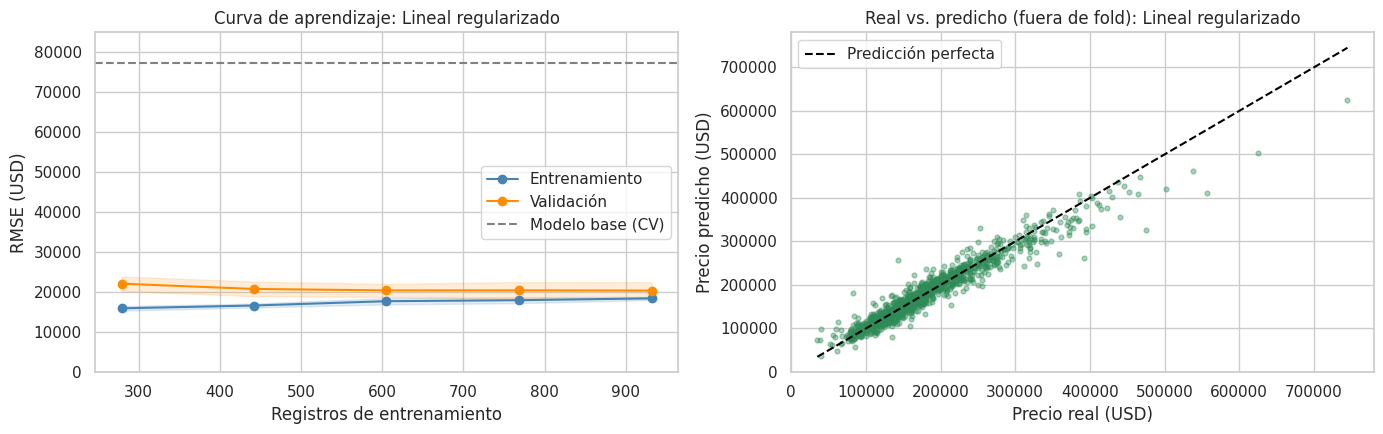

,Registros,RMSE entrenamiento,RMSE validación
0,279,15985.0,22141.0
1,442,16682.0,20825.0
2,605,17760.0,20464.0
3,768,18012.0,20470.0
4,932,18475.0,20417.0


In [42]:
display(graficar_modelo('Lineal regularizado', busquedas['Lineal regularizado']))

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**P9a. Lineal regularizado: Elastic Net (α = 0.01, l1_ratio = 0.2, Yeo-Johnson). Ajuste adecuado**

* **Búsqueda:** 70 configuraciones (Ridge, Lasso y Elastic Net × fuerza de regularización × transformación numérica). La de menor RMSE fue **Lasso (α = 0.001): 19,673 USD**, con una brecha del 13.4 %.
* **Configuración elegida por la regla de 1 EE:** Elastic Net α = 0.01, l1_ratio = 0.2, con Yeo-Johnson. RMSE de validación de **20,423 USD**, dentro del umbral 19,673 + 1,713/√5 = 20,439, y con la menor brecha del grupo empatado (**9.6 %**). Una regularización más fuerte sacrifica 3.8 % de RMSE en promedio a cambio de un modelo más estable y menos dependiente del entrenamiento.
* **Referencia sin regularización (OLS con `drop='first'`):** RMSE de validación de **21,340 USD** (4.5 % peor), con una **brecha del 28.1 %** (contra 9.6 %). Sin penalización, los 207 coeficientes se ajustan de más a las 932 casas de cada fold, y la colinealidad (por ejemplo, `GarageCars` con `GarageArea`) infla su varianza. En prueba, la OLS obtiene un RMSE menor (26,342 contra 27,329), pero la selección se basa en la validación cruzada, que promedia 5 estimaciones y no una sola partición; su brecha casi tres veces mayor indica un modelo menos confiable. Esto **confirma el valor de regularizar**.
* **Curva de aprendizaje:** el error de entrenamiento sube (16.0k → 18.5k) y el de validación baja (22.1k → 20.4k) hasta casi juntarse, y la validación se estabiliza a partir de ~600 registros. Es el patrón de un modelo **bien ajustado y limitado por sesgo**: más datos aportarían poco, porque su capacidad (relaciones lineales en el espacio transformado) ya está aprovechada.
* **Real vs. predicho:** los puntos siguen la diagonal en todo el rango, con subestimación en las casas de más de 450k USD, el segmento con menos ejemplos.
* **Prueba:** RMSE de 27,329, MAE de 15,409, R² de 0.900, MAPE de 8.2 % y RMSLE de 0.114. **Diagnóstico: ajuste adecuado.**

</div>

### **P9b. Árbol de decisión**

In [43]:
# P9b. Árbol de decisión.
malla_arbol = {P + 'max_depth': [4, 6, 8, 10, None], P + 'min_samples_leaf': [5, 10, 20, 30],
               P + 'ccp_alpha': [0.0, 0.001, 0.005]}
busquedas['Árbol de decisión'] = ajustar(armar_modelo(DecisionTreeRegressor(random_state=RANDOM_STATE), X_train, modelo_arbol=True), malla_arbol)
resumenes.append(resumen_busqueda('Árbol de decisión', busquedas['Árbol de decisión']))
display(tabla_configuraciones(busquedas['Árbol de decisión']))

,Hiperparámetros,RMSE val,Desv. val,RMSE entrenamiento,Brecha (%),Elegida
9,"{'ccp_alpha': 0.0, 'max_depth': 8, 'min_sample...",35557.7,3401.8,25666.6,27.8,
13,"{'ccp_alpha': 0.0, 'max_depth': 10, 'min_sampl...",35601.5,3341.5,25384.1,28.7,
17,"{'ccp_alpha': 0.0, 'max_depth': None, 'min_sam...",35621.6,3338.3,25332.9,28.9,
5,"{'ccp_alpha': 0.0, 'max_depth': 6, 'min_sample...",35700.4,3816.5,27061.4,24.2,
29,"{'ccp_alpha': 0.001, 'max_depth': 8, 'min_samp...",35980.6,3396.0,26676.5,25.9,
25,"{'ccp_alpha': 0.001, 'max_depth': 6, 'min_samp...",36084.9,3574.7,27532.0,23.7,◀ elegida


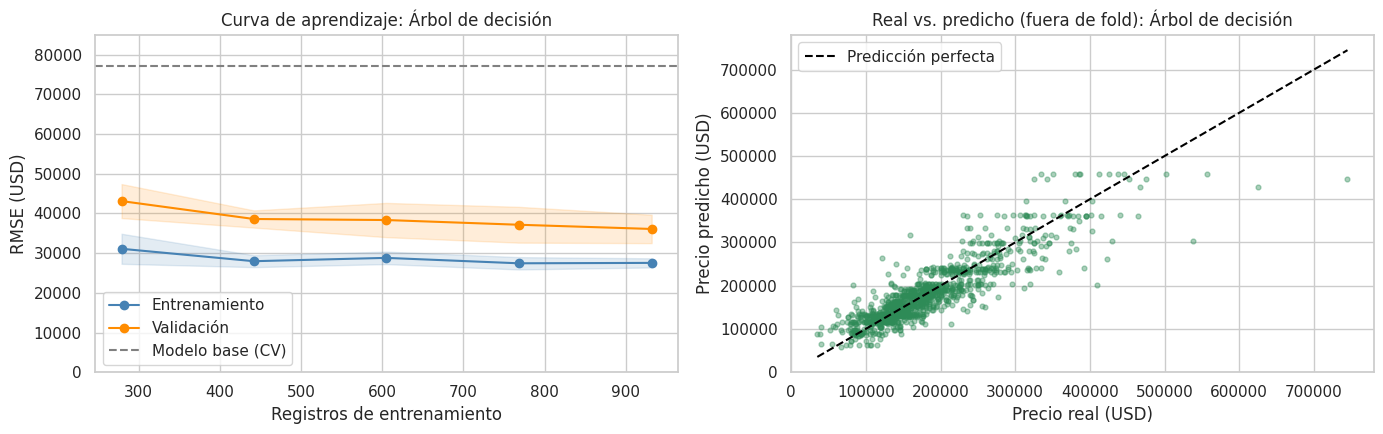

,Registros,RMSE entrenamiento,RMSE validación
0,279,31093.0,43109.0
1,442,27965.0,38596.0
2,605,28804.0,38334.0
3,768,27439.0,37149.0
4,932,27541.0,36084.0


In [44]:
display(graficar_modelo('Árbol de decisión', busquedas['Árbol de decisión']))

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**P9b. Árbol de decisión (profundidad 6, mín. 10 por hoja, ccp_alpha = 0.001). El más débil de los seis**

* **Búsqueda:** 60 configuraciones. El mejor RMSE fue 35,577 USD (profundidad 8, brecha de 27.9 %). La regla de 1 EE elige una versión **más podada** (profundidad 6 y poda por complejidad), con **36,085 USD** y una brecha de **23.7 %**.
* **Curva de aprendizaje:** las dos curvas se mantienen altas (entrenamiento 31.1k → 27.5k, validación 43.1k → 36.1k) y separadas. Hay una **combinación de sesgo y varianza**: un solo árbol aproxima la relación precio-superficie con **escalones** (pocas predicciones distintas, tantas como hojas), así que no puede representar relaciones suaves. Además, sus cortes cambian mucho con cada muestra.
* **Real vs. predicho:** se observan bandas horizontales, es decir, muchas casas distintas reciben exactamente el mismo precio (el de su hoja).
* **Prueba:** RMSE de 40,631, R² de 0.780 y **MAPE de 14.2 %**, casi el doble que los mejores modelos.
* **Diagnóstico: sobreajuste leve controlado** según el criterio de brecha, pero con un **error alto en ambos conjuntos** (47 % del modelo base, cerca del umbral de subentrenamiento). Su valor es interpretativo (reglas legibles), no predictivo.

</div>

### **P9c. Bosque aleatorio**

In [45]:
# P9c. Bosque aleatorio.
malla_rf = {P + 'max_features': [0.33, 0.5], P + 'min_samples_leaf': [1, 3, 5, 8], P + 'max_samples': [None, 0.7]}
rf_base = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)
busquedas['Bosque aleatorio'] = ajustar(armar_modelo(rf_base, X_train, modelo_arbol=True), malla_rf)
resumenes.append(resumen_busqueda('Bosque aleatorio', busquedas['Bosque aleatorio']))
display(tabla_configuraciones(busquedas['Bosque aleatorio']))

,Hiperparámetros,RMSE val,Desv. val,RMSE entrenamiento,Brecha (%),Elegida
8,"{'max_features': 0.5, 'max_samples': None, 'mi...",25932.9,4451.3,10535.9,59.4,
0,"{'max_features': 0.33, 'max_samples': None, 'm...",26332.2,4899.8,10690.6,59.4,
12,"{'max_features': 0.5, 'max_samples': 0.7, 'min...",26556.9,4870.5,14291.2,46.2,
9,"{'max_features': 0.5, 'max_samples': None, 'mi...",26616.4,4851.8,15472.3,41.9,
4,"{'max_features': 0.33, 'max_samples': 0.7, 'mi...",26691.7,5127.5,14329.0,46.3,
14,"{'max_features': 0.5, 'max_samples': 0.7, 'min...",27692.2,5318.5,21568.4,22.1,◀ elegida


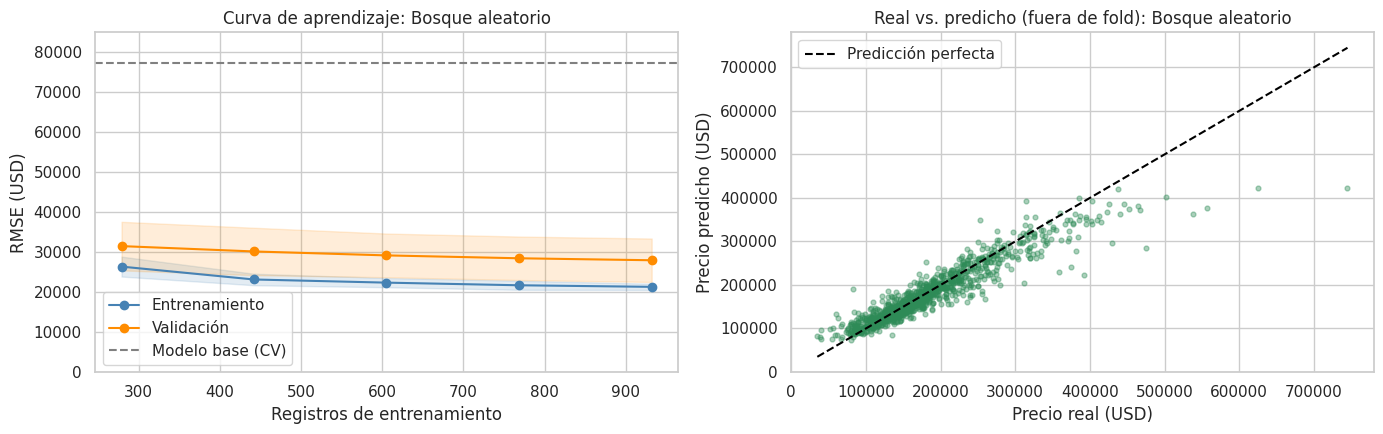

,Registros,RMSE entrenamiento,RMSE validación
0,279,26410.0,31534.0
1,442,23191.0,30197.0
2,605,22404.0,29213.0
3,768,21746.0,28494.0
4,932,21350.0,27997.0


In [46]:
display(graficar_modelo('Bosque aleatorio', busquedas['Bosque aleatorio']))

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**P9c. Bosque aleatorio (max_features = 0.5, max_samples = 0.7, mín. 5 por hoja). Sobreajuste leve controlado**

* **Búsqueda:** 16 configuraciones (300 árboles). La de menor RMSE (25,896 USD) usa hojas de un solo registro y tiene una **brecha del 59.4 %**: memoriza el entrenamiento (RMSE de entrenamiento de 10.5k).
* **La regla de 1 EE es decisiva aquí:** elige hojas de 5 registros y submuestreo del 70 %, con **27,710 USD** (dentro del umbral de 27,902) y la brecha baja a **22.2 %**. Se cambia un 7 % de RMSE de validación por un modelo mucho menos memorizador.
* **Curva de aprendizaje:** la validación baja de forma sostenida (31.5k → 28.0k) y la brecha se reduce: el modelo está **limitado por varianza**, y más datos lo mejorarían.
* **Limitación estructural:** un bosque **promedia** precios observados, así que no puede predecir por encima del rango de cada hoja. Por eso subestima de forma sistemática las casas caras (la nube real vs. predicho se aplana arriba de 400k USD). En prueba obtiene un RMSE de 34,507, R² de 0.841 y MAPE de 9.4 %.
* **Diagnóstico: sobreajuste leve controlado.** Es inferior a los modelos lineales en este problema, porque la relación log(precio)-características es predominantemente aditiva y suave.

</div>

### **P9d. XGBoost**

In [ ]:
# P9d. XGBoost (búsqueda aleatoria de 40 combinaciones sobre una malla de 2,916).
malla_xgb = {P + 'n_estimators': [600, 1000, 1500], P + 'learning_rate': [0.02, 0.03, 0.05],
             P + 'max_depth': [2, 3, 4], P + 'subsample': [0.6, 0.8], P + 'colsample_bytree': [0.2, 0.3, 0.5],
             P + 'min_child_weight': [1, 3, 5], P + 'reg_lambda': [1, 5, 10], P + 'gamma': [0, 0.01]}
xgb_base = XGBRegressor(random_state=RANDOM_STATE, n_jobs=1)
busquedas['XGBoost'] = ajustar(armar_modelo(xgb_base, X_train, modelo_arbol=True), malla_xgb, n_iter=40)
resumenes.append(resumen_busqueda('XGBoost', busquedas['XGBoost']))
display(tabla_configuraciones(busquedas['XGBoost']))

,Hiperparámetros,RMSE val,Desv. val,RMSE entrenamiento,Brecha (%),Elegida
2,"{'subsample': 0.6, 'reg_lambda': 1, 'n_estimat...",21812.8,3433.9,9205.7,57.8,
8,"{'subsample': 0.8, 'reg_lambda': 1, 'n_estimat...",21813.2,3290.0,11095.5,49.1,
37,"{'subsample': 0.8, 'reg_lambda': 1, 'n_estimat...",21886.3,3332.2,8835.3,59.6,
11,"{'subsample': 0.8, 'reg_lambda': 1, 'n_estimat...",22158.8,3360.7,8542.0,61.5,
15,"{'subsample': 0.8, 'reg_lambda': 1, 'n_estimat...",22184.5,3865.7,4849.4,78.1,
28,"{'subsample': 0.6, 'reg_lambda': 10, 'n_estima...",22797.1,3973.1,15470.6,32.1,◀ elegida


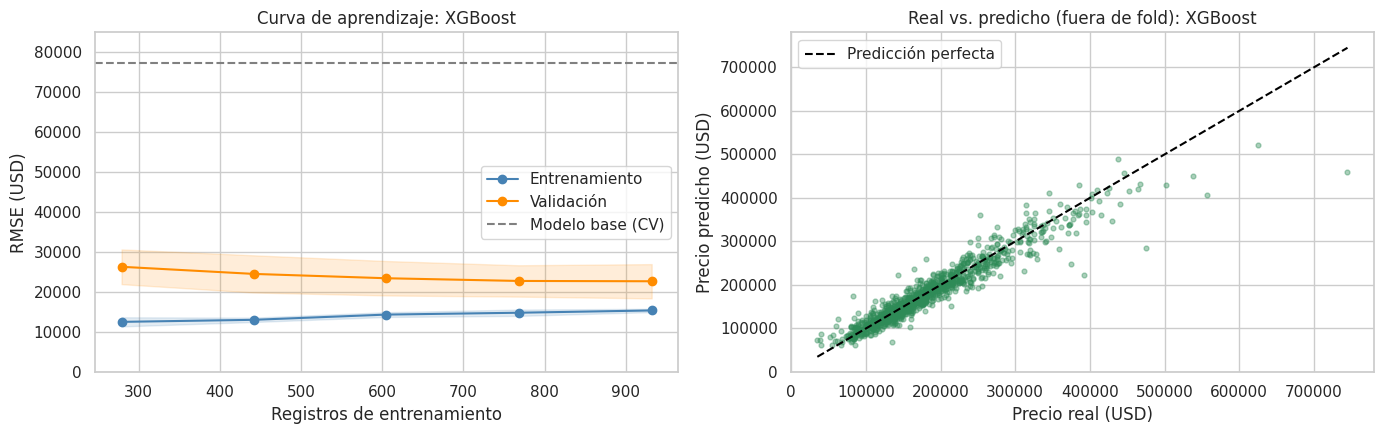

,Registros,RMSE entrenamiento,RMSE validación
0,279,12596.0,26364.0
1,442,13108.0,24583.0
2,605,14413.0,23501.0
3,768,14878.0,22824.0
4,932,15449.0,22747.0


In [48]:
display(graficar_modelo('XGBoost', busquedas['XGBoost']))

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**P9d. XGBoost (1,500 árboles de profundidad 2, learning_rate = 0.02, colsample = 0.3, λ = 10). Sobreentrenado según el criterio, pero competitivo**

* **Búsqueda aleatoria** de 40 combinaciones sobre una malla de 2,916. Las mejores configuraciones alcanzan **≈21,800 USD**, pero con brechas del 49 al 78 %: el boosting reduce el error de entrenamiento casi a voluntad.
* **Configuración elegida (1 EE):** árboles muy poco profundos (profundidad 2, es decir, interacciones de segundo orden como máximo), aprendizaje lento (0.02), 30 % de las variables por árbol y regularización L2 fuerte (λ = 10). RMSE de **22,797 USD**; la brecha baja a **32.1 %**.
* **Curva de aprendizaje:** el error de validación baja de 26.4k a 22.7k y el de entrenamiento sube de 12.6k a 15.4k. **La brecha se cierra al agregar datos** (de 52 % a 32 %): el sobreajuste es de varianza y disminuiría con más ventas, no es una falla del modelo.
* **Prueba:** RMSE de 27,529, R² de 0.899 y **el menor MAPE de prueba de los seis modelos (7.9 %)**: en error relativo es muy competitivo.
* **Diagnóstico: sobreentrenado** según el umbral de brecha del 30 %, aunque apenas por encima (32.1 %). Es la configuración menos sobreajustada entre las estadísticamente empatadas. Con 1,166 casas, un modelo de esta flexibilidad no alcanza a superar a los lineales.

</div>

### **P9e. Red neuronal de perceptrón multicapa (MLP)**

In [49]:
# P9e. Red neuronal de perceptrón multicapa (MLP) con paro temprano.
malla_mlp = {P + 'hidden_layer_sizes': [(32,), (64,), (128,), (64, 32)], P + 'alpha': [0.3, 1, 3, 10], **TRANSFORMAR}
mlp_base = MLPRegressor(max_iter=3000, early_stopping=True, random_state=RANDOM_STATE)
busquedas['Red neuronal MLP'] = ajustar(armar_modelo(mlp_base, X_train), malla_mlp)
resumenes.append(resumen_busqueda('Red neuronal MLP', busquedas['Red neuronal MLP']))
display(tabla_configuraciones(busquedas['Red neuronal MLP']))

,Hiperparámetros,RMSE val,Desv. val,RMSE entrenamiento,Brecha (%),Elegida
15,"{'alpha': 1, 'hidden_layer_sizes': (64, 32), '...",20626.7,2589.2,13765.3,33.3,
14,"{'alpha': 1, 'hidden_layer_sizes': (64, 32), '...",20975.4,2158.5,13869.0,33.9,
23,"{'alpha': 3, 'hidden_layer_sizes': (64, 32), '...",21274.8,2558.0,17472.3,17.9,◀ elegida
7,"{'alpha': 0.3, 'hidden_layer_sizes': (64, 32),...",21302.5,2368.3,12973.0,39.1,
10,"{'alpha': 1, 'hidden_layer_sizes': (64,), 'tra...",21510.4,1717.7,14367.4,33.2,


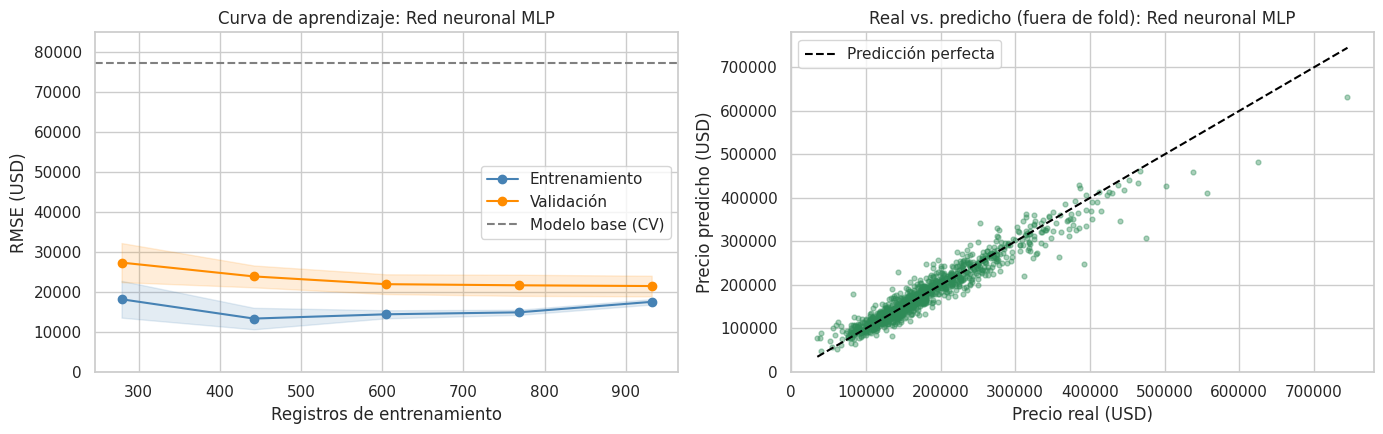

,Registros,RMSE entrenamiento,RMSE validación
0,279,18248.0,27413.0
1,442,13420.0,23955.0
2,605,14491.0,22016.0
3,768,14975.0,21738.0
4,932,17599.0,21551.0


In [50]:
display(graficar_modelo('Red neuronal MLP', busquedas['Red neuronal MLP']))

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**P9e. Red neuronal MLP (capas 64-32, alpha = 3, estandarización). Sobreajuste leve controlado**

* **Búsqueda:** 32 configuraciones (arquitectura × regularización L2 × transformación). La de menor RMSE (20,627 USD, alpha = 1) tiene una **brecha del 33.3 %**. La regla de 1 EE elige **alpha = 3** (regularización más fuerte): **21,275 USD** con una brecha del **17.9 %**. La validación cruzada eligió **estandarizar** las numéricas en lugar de Yeo-Johnson.
* **Paro temprano** (`early_stopping=True`): el 10 % del entrenamiento de cada ajuste se reserva internamente para detener el aprendizaje cuando deja de mejorar, otra defensa contra el sobreajuste.
* **Curva de aprendizaje:** la validación baja de 27.4k a 21.6k, la mayor mejora relativa de los seis modelos al agregar datos. Durante el desarrollo se observó que con el 20 % del entrenamiento (186 registros) la red era numéricamente inestable en algún fold (predicciones explosivas), por lo que las curvas inician en el 30 %. Las redes necesitan más datos que los modelos lineales para ser confiables, y con 1,166 casas esta red apenas está en zona estable.
* **Prueba:** **el menor RMSE de prueba de los seis** (26,076 USD, R² de 0.909), pero el tercero en validación cruzada y **más variable entre folds** que la SVR y el lineal (±2,558 USD contra ±1,801 y ±2,109).
* **Diagnóstico: sobreajuste leve controlado.** Es un buen modelo, pero menos consistente que la SVR y el lineal.

</div>

### **P9f. Máquina de vector soporte (SVM)**

In [51]:
# P9f. Máquina de vector soporte para regresión (SVR) con kernel RBF y lineal.
malla_svr = [{P + 'kernel': ['rbf'], P + 'C': [1, 3, 10, 30], P + 'gamma': [1e-4, 3e-4, 1e-3], P + 'epsilon': [0.05, 0.1], **TRANSFORMAR},
             {P + 'kernel': ['linear'], P + 'C': [0.001, 0.003, 0.01, 0.03], P + 'epsilon': [0.05, 0.1], **TRANSFORMAR}]
busquedas['SVM (SVR)'] = ajustar(armar_modelo(SVR(), X_train), malla_svr)
resumenes.append(resumen_busqueda('SVM (SVR)', busquedas['SVM (SVR)']))
display(tabla_configuraciones(busquedas['SVM (SVR)']))

,Hiperparámetros,RMSE val,Desv. val,RMSE entrenamiento,Brecha (%),Elegida
60,"{'C': 0.03, 'epsilon': 0.05, 'kernel': 'linear...",19615.4,1613.7,17656.5,10.0,
62,"{'C': 0.03, 'epsilon': 0.1, 'kernel': 'linear'...",19689.8,1690.1,17483.7,11.2,
43,"{'C': 30, 'epsilon': 0.1, 'gamma': 0.0001, 'ke...",19874.5,1599.4,17604.5,11.4,
58,"{'C': 0.01, 'epsilon': 0.1, 'kernel': 'linear'...",20130.7,1800.6,18742.5,6.9,◀ elegida
56,"{'C': 0.01, 'epsilon': 0.05, 'kernel': 'linear...",20137.2,1685.8,18614.0,7.6,


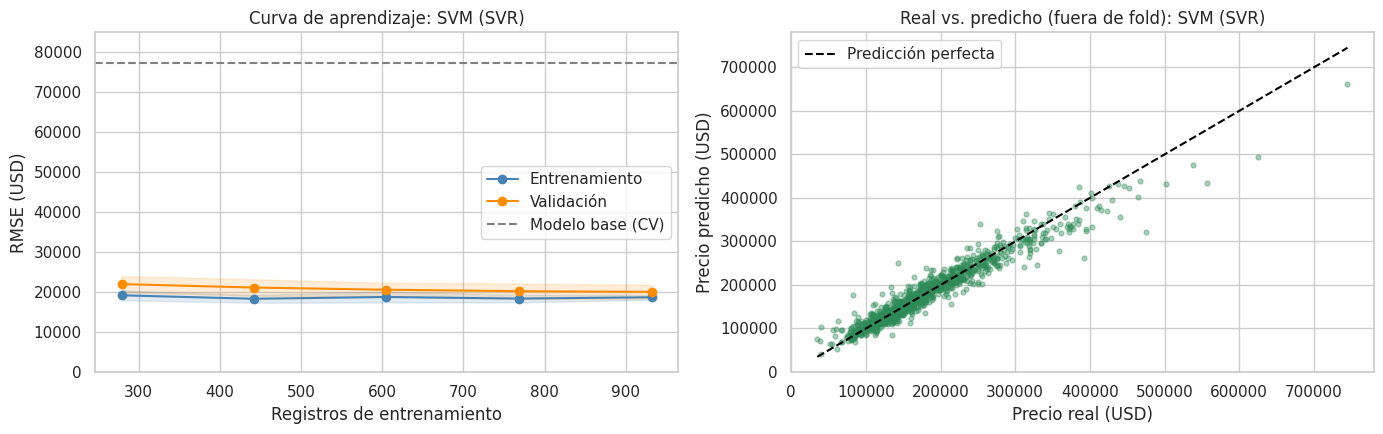

,Registros,RMSE entrenamiento,RMSE validación
0,279,19236.0,22041.0
1,442,18366.0,21175.0
2,605,18813.0,20630.0
3,768,18418.0,20262.0
4,932,18749.0,20100.0


In [52]:
display(graficar_modelo('SVM (SVR)', busquedas['SVM (SVR)']))

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**P9f. SVR con kernel lineal (C = 0.01, ε = 0.1, Yeo-Johnson). Mejor modelo en validación cruzada**

* **Búsqueda:** 64 configuraciones (kernel RBF y lineal × C × ε × γ × transformación). El kernel RBF alcanza **19,874 USD** (C = 30, γ = 10⁻⁴), muy cerca del lineal, pero el mejor es el **kernel lineal** con C = 0.03 (19,616 USD).
* **Configuración elegida (1 EE):** kernel lineal con **C = 0.01** (más regularización) y ε = 0.1. RMSE de **20,130 USD**, dentro del umbral de 20,337, con la **menor brecha de los seis modelos (6.9 %)**.
* **Por qué funciona:** la SVR lineal es un modelo lineal con **pérdida ε-insensible**: ignora los errores menores que ε (en el logaritmo estandarizado) y penaliza linealmente, no cuadráticamente, los grandes. Esto la hace **menos sensible a casas atípicas** que la pérdida cuadrática de Ridge, Lasso y Elastic Net.
* **Curva de aprendizaje:** el error de entrenamiento es estable (≈18.4k a 19.2k) y el de validación converge hacia él (22.0k → 20.1k). Es el **ajuste más equilibrado** de los seis.
* **Prueba:** RMSE de 27,246, MAE de 15,126, R² de 0.901, MAPE de 8.1 % y RMSLE de 0.115 (en la escala de la competencia de Kaggle). **Diagnóstico: ajuste adecuado.**

</div>

### **P9. Resultados consolidados**

In [53]:
# P9. Tabla consolidada: validación cruzada (selección) y conjunto de prueba (evaluación final).
tabla_modelos = pd.DataFrame(resumenes).set_index('Modelo')
cols_val = ['RMSE val', 'Desv. val', 'MAE val', 'R2 val', 'MAPE val (%)', 'RMSLE val', 'RMSE entrenamiento', 'Brecha (%)', 'Diagnóstico']
cols_test = ['RMSE prueba', 'MAE prueba', 'R2 prueba', 'MAPE prueba (%)', 'RMSLE prueba',
             'Tiempo entrenamiento (s)', 'Tiempo búsqueda (s)', 'Configuraciones evaluadas']
display(tabla_modelos[cols_val].sort_values('RMSE val').round(3))
display(tabla_modelos[cols_test].sort_values('RMSE prueba').round(3))
mejores_hiperparametros = pd.DataFrame({nombre: describir(b.best_params_) for nombre, b in busquedas.items()}).T
display(mejores_hiperparametros.fillna('-').astype(str))

,RMSE val,Desv. val,MAE val,R2 val,MAPE val (%),RMSLE val,RMSE entrenamiento,Brecha (%),Diagnóstico
Modelo,,,,,,,,,
SVM (SVR),20130.691,1800.600,13448.372,0.930,7.932,0.113,18742.540,6.896,Ajuste adecuado
Lineal regularizado,20422.908,2109.232,13671.688,0.929,8.039,0.113,18470.316,9.561,Ajuste adecuado
Red neuronal MLP,21274.778,2557.991,14453.802,0.923,8.620,0.119,17472.315,17.873,Sobreajuste leve controlado
XGBoost,22797.058,3973.101,14448.725,0.911,8.341,0.119,15470.580,32.138,Sobreentrenado
Bosque aleatorio,27692.187,5318.537,17154.851,0.871,9.897,0.141,21568.392,22.114,Sobreajuste leve controlado
Árbol de decisión,36084.871,3574.660,24574.649,0.774,14.431,0.193,27531.978,23.702,Sobreajuste leve controlado


,RMSE prueba,MAE prueba,R2 prueba,MAPE prueba (%),RMSLE prueba,Tiempo entrenamiento (s),Tiempo búsqueda (s),Configuraciones evaluadas
Modelo,,,,,,,,
Red neuronal MLP,26075.980,15270.271,0.909,8.483,0.123,1.085,64.974,32
SVM (SVR),27254.959,15128.055,0.901,8.068,0.115,0.231,87.717,64
Lineal regularizado,27328.934,15409.087,0.900,8.150,0.114,0.139,54.256,70
XGBoost,27529.328,15181.649,0.899,7.933,0.112,0.764,113.165,40
Bosque aleatorio,34506.180,17676.226,0.841,9.434,0.139,1.573,104.059,16
Árbol de decisión,40631.086,25640.635,0.780,14.220,0.191,0.055,27.586,60


,modelo,alpha,l1_ratio,transformar,ccp_alpha,max_depth,min_samples_leaf,max_features,max_samples,subsample,reg_lambda,n_estimators,min_child_weight,learning_rate,gamma,colsample_bytree,hidden_layer_sizes,C,epsilon,kernel
Lineal regularizado,ElasticNet,0.01,0.2,PowerTransformer,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-
Árbol de decisión,-,-,-,-,0.001,6.0,10.0,-,-,-,-,-,-,-,-,-,-,-,-,-
Bosque aleatorio,-,-,-,-,-,-,5.0,0.5,0.7,-,-,-,-,-,-,-,-,-,-,-
XGBoost,-,-,-,-,-,2.0,-,-,-,0.6,10.0,1500.0,1.0,0.02,0.01,0.3,-,-,-,-
Red neuronal MLP,-,3,-,StandardScaler,-,-,-,-,-,-,-,-,-,-,-,-,"(64, 32)",-,-,-
SVM (SVR),-,-,-,PowerTransformer,-,-,-,-,-,-,-,-,-,-,-,-,-,0.01,0.1,linear


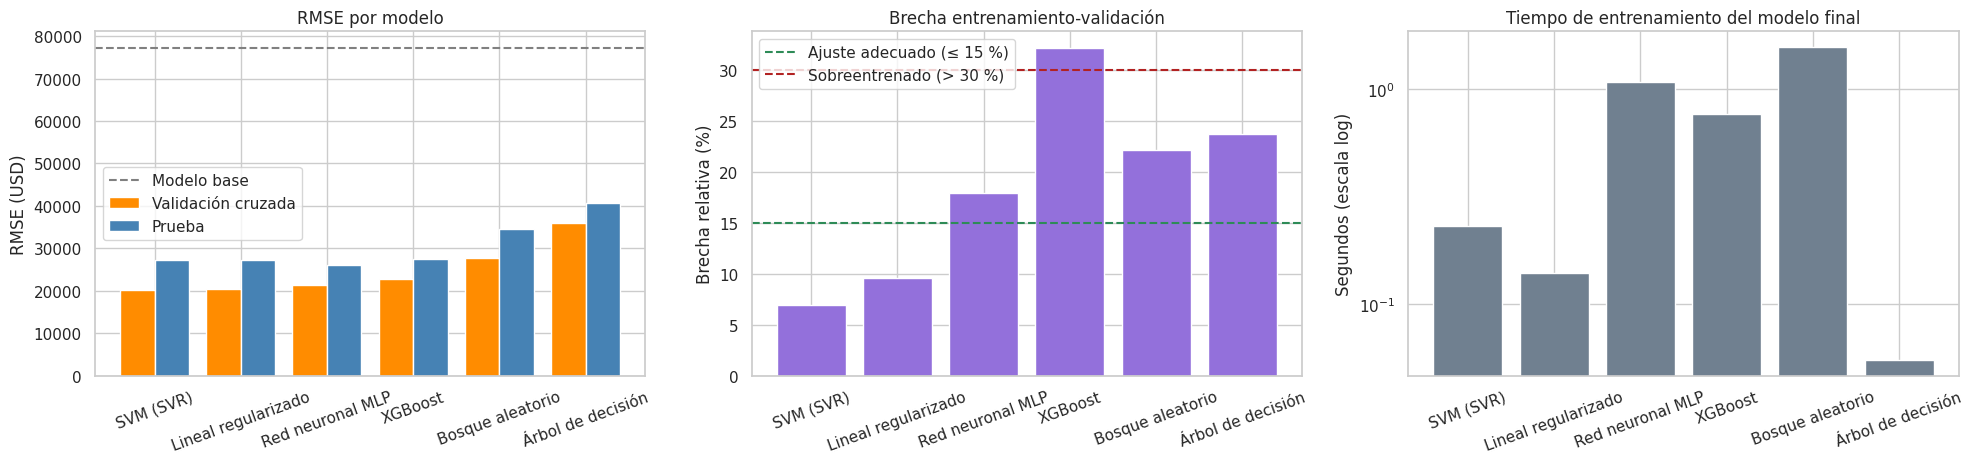

In [54]:
# P9. Comparación visual del desempeño, del ajuste (brecha) y del costo computacional.
orden = tabla_modelos.sort_values('RMSE val').index
posiciones = np.arange(len(orden))
fig, ejes = plt.subplots(1, 3, figsize=(20, 4.8))
ejes[0].bar(posiciones - 0.2, tabla_modelos.loc[orden, 'RMSE val'], width=0.4, label='Validación cruzada', color='darkorange')
ejes[0].bar(posiciones + 0.2, tabla_modelos.loc[orden, 'RMSE prueba'], width=0.4, label='Prueba', color='steelblue')
ejes[0].axhline(RMSE_BASE, ls='--', color='gray', label='Modelo base')
ejes[0].set(title='RMSE por modelo', ylabel='RMSE (USD)')
ejes[0].legend()
ejes[1].bar(posiciones, tabla_modelos.loc[orden, 'Brecha (%)'], color='mediumpurple')
ejes[1].axhline(15, ls='--', color='seagreen', label='Ajuste adecuado (≤ 15 %)')
ejes[1].axhline(30, ls='--', color='firebrick', label='Sobreentrenado (> 30 %)')
ejes[1].set(title='Brecha entrenamiento-validación', ylabel='Brecha relativa (%)')
ejes[1].legend()
ejes[2].bar(posiciones, tabla_modelos.loc[orden, 'Tiempo entrenamiento (s)'], color='slategray')
ejes[2].set(title='Tiempo de entrenamiento del modelo final', ylabel='Segundos (escala log)', yscale='log')
for eje in ejes:
    eje.set_xticks(posiciones)
    eje.set_xticklabels(orden, rotation=20)
plt.tight_layout()
plt.show()

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P9. Resultados consolidados**

**Ranking por RMSE de validación cruzada (métrica de referencia):**

| Lugar | Modelo | RMSE val | R² val | MAPE val | RMSLE val | Brecha | Diagnóstico | RMSE prueba |
|---|---|---|---|---|---|---|---|---|
| 1 | **SVR (lineal)** | **20,130** | 0.930 | 7.9 % | 0.113 | 6.9 % | Ajuste adecuado | 27,246 |
| 2 | Lineal regularizado | 20,423 | 0.929 | 8.0 % | 0.113 | 9.6 % | Ajuste adecuado | 27,329 |
| 3 | MLP | 21,275 | 0.923 | 8.6 % | 0.119 | 17.9 % | Sobreajuste leve | **26,076** |
| 4 | XGBoost | 22,797 | 0.911 | 8.3 % | 0.119 | 32.1 % | Sobreentrenado (límite) | 27,529 |
| 5 | Bosque aleatorio | 27,710 | 0.871 | 9.9 % | 0.141 | 22.2 % | Sobreajuste leve | 34,507 |
| 6 | Árbol de decisión | 36,085 | 0.774 | 14.4 % | 0.193 | 23.7 % | Sobreajuste leve (error alto) | 40,631 |

**Lectura de los resultados.**
* **Todos los modelos superan con amplitud al modelo base** (77,249 USD): el mejor reduce el error en **74 %**, y ninguno queda subentrenado según el criterio. La gráfica central muestra la brecha de cada modelo frente a los umbrales del 15 % y el 30 %: los dos modelos lineales están en la zona de ajuste adecuado, y solo XGBoost cruza, por poco, el umbral de sobreentrenamiento.
* **Los modelos lineales (SVR lineal y Elastic Net) dominan.** Con el logaritmo del precio y las variables transformadas, la relación es casi aditiva: cada unidad de una característica transformada aporta un porcentaje del precio. Los modelos de árboles necesitan muchos cortes para aproximar esa suavidad y no pueden extrapolar a las casas caras.
* **Referencia con Kaggle:** el RMSLE de los mejores modelos es de ≈ 0.113 en validación y de ≈ 0.115 en prueba. Está en la misma escala que la métrica oficial de la competencia, aunque la comparación con su tabla de posiciones es solo orientativa, porque esta se calcula con otro conjunto de prueba.
* **¿Por qué el RMSE de prueba (≈26-27k) es mayor que el de validación (≈20k)?** El conjunto de prueba es más disperso (desviación estándar de 86.8k contra 77.6k) y contiene casas caras difíciles, como la Id 692 de 755,000 USD (ver P15). **El MAPE de validación y el de prueba son casi iguales** (SVR: 7.9 % y 8.1 %), así que el error relativo se mantiene y no hay evidencia de sobreajuste a la validación cruzada: el aumento del RMSE se explica por unas pocas casas de alto valor, a las que el RMSE es muy sensible.
* **Costo computacional:** todos los modelos finales entrenan en **menos de 2 segundos**, desde 0.05 s del árbol hasta 1.50 s del bosque. La búsqueda de hiperparámetros toma entre 27.6 y 113.2 segundos (los tiempos varían ligeramente entre ejecuciones y equipos). El costo no es un factor diferenciador en este volumen de datos.
* **Consistencia:** la MLP gana en prueba, pero es tercera en validación cruzada y más variable entre folds. En cambio, la SVR y el lineal son estables en ambos criterios. Para decidir pesa más la validación cruzada (5 estimaciones) que una sola partición de prueba.

</div>

# **6. Análisis de factores y selección de modelos (P10 y P11)**

## **P10. Análisis de factores del mejor modelo**

In [55]:
# P10. Análisis de factores del mejor modelo (menor RMSE de validación cruzada).
MEJOR = tabla_modelos['RMSE val'].idxmin()
mejor_modelo = busquedas[MEJOR].best_estimator_
display(pd.DataFrame({'Mejor modelo': [MEJOR], 'Algoritmo': [type(mejor_modelo.regressor_.named_steps['modelo']).__name__],
                      'RMSE val': [tabla_modelos.loc[MEJOR, 'RMSE val'].round(0)]}))

# Importancia por permutación sobre el conjunto de prueba: cuánto empeora el RMSE al desordenar cada variable.
perm = permutation_importance(mejor_modelo, X_test, y_test, scoring='neg_root_mean_squared_error',
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importancia = pd.DataFrame({'Aumento del RMSE (USD)': perm.importances_mean, 'Desv. estándar': perm.importances_std},
                           index=X_test.columns).sort_values('Aumento del RMSE (USD)', ascending=False)
importancia['% del total'] = importancia['Aumento del RMSE (USD)'].clip(lower=0) / importancia['Aumento del RMSE (USD)'].clip(lower=0).sum() * 100
display(importancia.head(15).round(1))
display(importancia.tail(5).round(1))

,Mejor modelo,Algoritmo,RMSE val
0,SVM (SVR),SVR,20131.0


,Aumento del RMSE (USD),Desv. estándar,% del total
GrLivArea,19374.4,1402.8,25.7
OverallQual,9819.5,906.6,13.0
TotalBsmtSF,8421.0,797.8,11.2
AgeHouse,4739.9,801.5,6.3
LotArea,4305.8,909.9,5.7
1stFlrSF,3985.6,524.3,5.3
OverallCond,2145.2,1278.7,2.8
Neighborhood,2105.4,294.7,2.8
GarageCars,2085.5,373.9,2.8
FullBath,1619.3,266.7,2.1


,Aumento del RMSE (USD),Desv. estándar,% del total
PoolArea,-84.2,66.9,0.0
BsmtFullBath,-93.7,159.7,0.0
MoSold_cos,-129.1,110.5,0.0
BsmtUnfSF,-342.3,441.1,0.0
BedroomAbvGr,-585.9,281.6,0.0


In [56]:
# P10. Robustez del ranking: importancia por permutación en cada fold de validación del entrenamiento.
importancias_cv = []
for entrena, valida in CV.split(X_train):
    modelo_fold = clone(mejor_modelo).fit(X_train.iloc[entrena], y_train.iloc[entrena])
    perm_fold = permutation_importance(modelo_fold, X_train.iloc[valida], y_train.iloc[valida],
                                       scoring='neg_root_mean_squared_error', n_repeats=5,
                                       random_state=RANDOM_STATE, n_jobs=-1)
    importancias_cv.append(perm_fold.importances_mean)
importancia['Aumento del RMSE en CV (USD)'] = pd.Series(np.mean(importancias_cv, axis=0), index=X_train.columns)
importancia['Lugar en prueba'] = range(1, len(importancia) + 1)
importancia['Lugar en CV'] = importancia['Aumento del RMSE en CV (USD)'].rank(ascending=False).astype(int)
display(importancia[['Aumento del RMSE (USD)', 'Aumento del RMSE en CV (USD)', 'Lugar en prueba', 'Lugar en CV']].head(10).round(1))
top10_prueba, top10_cv = set(importancia.index[:10]), set(importancia['Lugar en CV'].nsmallest(10).index)
display(pd.DataFrame({'Variables en el top 10 de ambos': [len(top10_prueba & top10_cv)],
                      'Correlación de Spearman entre rankings': [importancia['Lugar en prueba'].corr(importancia['Lugar en CV'], method='spearman')]}).round(3))

,Aumento del RMSE (USD),Aumento del RMSE en CV (USD),Lugar en prueba,Lugar en CV
GrLivArea,19374.4,15665.7,1,1
OverallQual,9819.5,9249.4,2,2
TotalBsmtSF,8421.0,6254.5,3,3
AgeHouse,4739.9,4394.5,4,5
LotArea,4305.8,5231.6,5,4
1stFlrSF,3985.6,2947.4,6,6
OverallCond,2145.2,2757.2,7,7
Neighborhood,2105.4,2012.7,8,8
GarageCars,2085.5,1847.7,9,9
FullBath,1619.3,892.5,10,13


,Variables en el top 10 de ambos,Correlación de Spearman entre rankings
0,9,0.824


,Variables transformadas,Coeficientes exactamente en cero
0,232,3


,Coeficiente,Efecto en el precio (%)
GrLivArea,0.245,10.177
OverallQual,0.147,5.977
LotArea,0.129,5.248
TotalBsmtSF,0.128,5.194
AgeHouse,-0.122,-4.715
OverallCond,0.114,4.594
Neighborhood_Edwards,-0.109,-4.223
Neighborhood_Crawfor,0.106,4.284
Neighborhood_StoneBr,0.104,4.185
Neighborhood_NoRidge,0.100,4.044


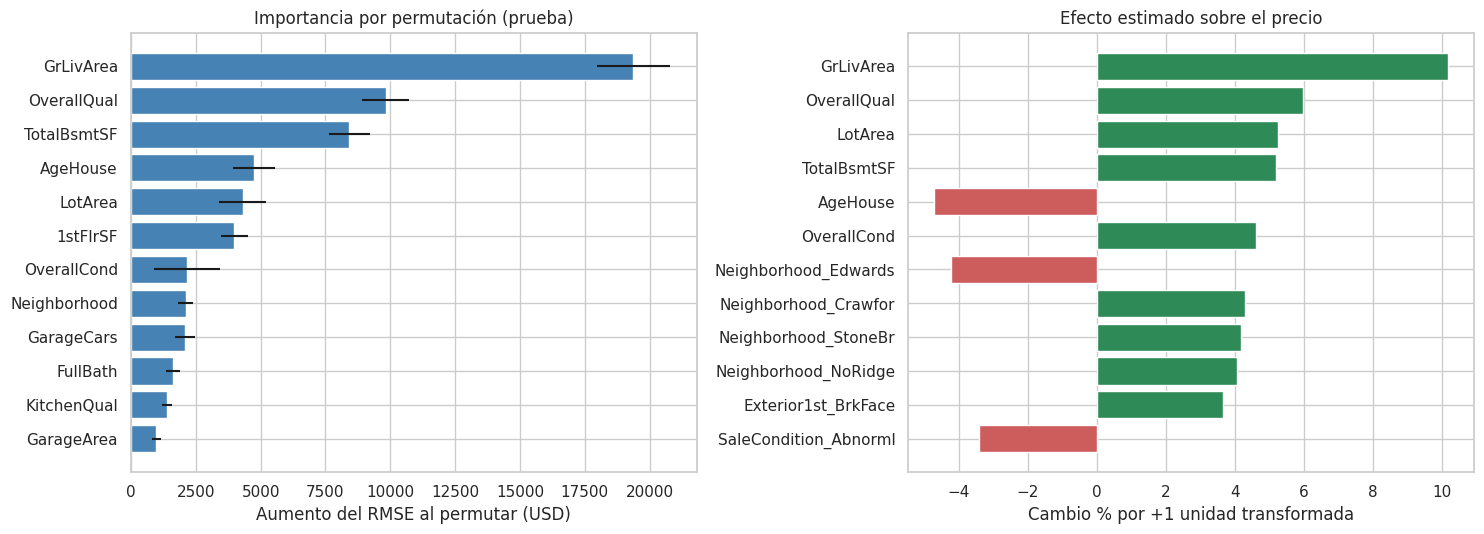

In [57]:
# P10. Dirección y magnitud de los efectos: coeficientes del modelo lineal expresados en % del precio.
modelo_final = mejor_modelo.regressor_.named_steps['modelo']
nombres = mejor_modelo.regressor_.named_steps['prepro'].get_feature_names_out()
sigma_log = mejor_modelo.transformer_.named_steps['estandarizar'].scale_[0]   # desv. estándar de log(precio)
coef = pd.Series(np.ravel(modelo_final.coef_), index=[n.split('__', 1)[1] for n in nombres])   # sin prefijo del bloque
efectos = pd.DataFrame({'Coeficiente': coef, 'Efecto en el precio (%)': (np.exp(coef * sigma_log) - 1) * 100})
efectos = efectos.reindex(efectos['Coeficiente'].abs().sort_values(ascending=False).index)
display(pd.DataFrame({'Variables transformadas': [len(coef)], 'Coeficientes exactamente en cero': [(coef == 0).sum()]}))
display(efectos.head(15).round(3))

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
top_perm = importancia.head(12).iloc[::-1]
ejes[0].barh(top_perm.index, top_perm['Aumento del RMSE (USD)'], xerr=top_perm['Desv. estándar'], color='steelblue')
ejes[0].set(title='Importancia por permutación (prueba)', xlabel='Aumento del RMSE al permutar (USD)')
top_coef = efectos.head(12).iloc[::-1]
ejes[1].barh(top_coef.index, top_coef['Efecto en el precio (%)'],
             color=np.where(top_coef['Efecto en el precio (%)'] > 0, 'seagreen', 'indianred'))
ejes[1].set(title='Efecto estimado sobre el precio', xlabel='Cambio % por +1 unidad transformada')
plt.tight_layout()
plt.show()

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P10. ¿Qué determina el precio de una casa en Ames?**

El mejor modelo por RMSE de validación es la **SVR con kernel lineal**: un modelo aditivo en el logaritmo del precio, por lo que sus coeficientes se interpretan como **cambios porcentuales** del precio. Se combinan dos lentes complementarias:
* La **importancia por permutación** (conjunto de prueba, 10 repeticiones), que mide cuánto empeora el RMSE si se "desordena" una variable. Es agnóstica al modelo y agrupa todas las columnas de una misma variable (por ejemplo, los 25 barrios).
* Los **coeficientes**, que dan la **dirección** y la magnitud. En las **numéricas y ordinales**, el efecto corresponde a aumentar una unidad de la variable transformada (≈ una desviación estándar). En las **categorías** (dummies con `drop=None`), como todas las categorías tienen coeficiente y la regularización reparte el efecto entre ellas, cada coeficiente se lee como la **contribución de esa categoría en la parametrización del modelo**, y no frente a una categoría de referencia. Para comparar Crawford con otro barrio, debe utilizarse la diferencia entre sus coeficientes, convertida a la escala del precio.

**Robustez del ranking:** la importancia se calculó dos veces, en el conjunto de prueba y en los 5 folds de validación del entrenamiento (reentrenando el modelo en cada fold). **9 de las 10 variables más importantes coinciden** en ambos rankings (correlación de Spearman de 0.82) y **el top 3 es idéntico**. Los factores no son un artefacto de una partición particular.

| # | Factor | Importancia (aumento del RMSE) | Efecto | Interpretación en el negocio |
|---|---|---|---|---|
| 1 | **Superficie habitable** (`GrLivArea`) | 19,382 USD (25.7 %) | **+10.2 %** | El tamaño es el primer determinante del valor: más superficie construida sobre el nivel del suelo implica un precio mayor, con rendimientos decrecientes (de ahí la utilidad de Yeo-Johnson). |
| 2 | **Calidad general** (`OverallQual`) | 9,823 USD (13.0 %) | **+6.0 %** | Materiales y acabados: a igual tamaño, una casa mejor construida vale más. Es el factor con mayor correlación individual con el precio (ρ = 0.82). |
| 3 | **Superficie del sótano** (`TotalBsmtSF`) | 8,426 USD (11.2 %) | **+5.2 %** | En Iowa el sótano es espacio útil (habitaciones, almacenamiento, refugio ante tormentas) y el mercado lo valora como superficie adicional. |
| 4 | **Antigüedad** (`AgeHouse`) | 4,738 USD (6.3 %) | **−4.7 %** | Cada desviación estándar de antigüedad transformada se asocia con un precio menor, lo que podría reflejar desgaste, obsolescencia de las instalaciones y mantenimiento esperado. Confirma el valor de la transformación pedida en la P2. |
| 5 | **Terreno** (`LotArea`) | 4,305 USD (5.7 %) | **+5.2 %** | Más terreno se traduce en mayor valor, una vez comprimida la cola de lotes muy grandes. |

**Otros factores con lectura de negocio clara:**
* **Ubicación** (`Neighborhood`, 2.8 % de la importancia en conjunto): Crawford, Stone Brook y Northridge tienen **coeficientes positivos**, mientras que Edwards tiene un **coeficiente negativo**, a igualdad de las demás características.
* **Estado de conservación** (`OverallCond`, **+4.6 %**): complementa a la calidad.
* **Condiciones de la venta:** una venta anormal (`SaleCondition = Abnorml`: remates, ventas cortas o intercambios) tiene un coeficiente negativo, al igual que estar junto a una avenida principal (Condition1 = Artery).

**El mes de venta casi no influye en el modelo final:** `MoSold_cos` aparece entre las variables de menor importancia (−129 USD) y `MoSold_sin` no figura entre las 15 más importantes, algo coherente con el efecto estacional débil de la P3. Las variables con importancia ligeramente negativa (por ejemplo, `BedroomAbvGr`) no aportan información adicional una vez considerada la superficie: más recámaras en la misma superficie significan recámaras más pequeñas. Solo 3 de los 232 coeficientes son exactamente cero, porque la SVR no realiza selección de variables como Lasso: la regularización reduce los coeficientes poco útiles hacia cero, pero no los anula.

Para finalizar es importante precisar sobre la diferencia entre asociación estadística y causalidad. Las relaciones identificadas por el modelo no necesariamente implican que una característica provoque un incremento o disminución en el precio.

</div>

## **P11. Los tres mejores modelos según RMSE + MAE**

In [58]:
# P11. Ranking por la suma RMSE + MAE (validación cruzada) y selección de los tres mejores.
ranking = tabla_modelos[['RMSE val', 'MAE val', 'RMSE prueba', 'MAE prueba']].copy()
ranking['RMSE + MAE val'] = ranking['RMSE val'] + ranking['MAE val']
ranking['RMSE + MAE prueba'] = ranking['RMSE prueba'] + ranking['MAE prueba']
ranking['Cociente RMSE / MAE val'] = ranking['RMSE val'] / ranking['MAE val']
ranking = ranking.sort_values('RMSE + MAE val')
ranking['Lugar'] = range(1, len(ranking) + 1)
display(ranking.round(2))
TOP3 = ranking.index[:3].tolist()
display(pd.DataFrame({'Tres mejores modelos': TOP3}))

,RMSE val,MAE val,RMSE prueba,MAE prueba,RMSE + MAE val,RMSE + MAE prueba,Cociente RMSE / MAE val,Lugar
Modelo,,,,,,,,
SVM (SVR),20130.69,13448.37,27254.96,15128.05,33579.06,42383.01,1.50,1
Lineal regularizado,20422.91,13671.69,27328.93,15409.09,34094.60,42738.02,1.49,2
Red neuronal MLP,21274.78,14453.80,26075.98,15270.27,35728.58,41346.25,1.47,3
XGBoost,22797.06,14448.73,27529.33,15181.65,37245.78,42710.98,1.58,4
Bosque aleatorio,27692.19,17154.85,34506.18,17676.23,44847.04,52182.41,1.61,5
Árbol de decisión,36084.87,24574.65,40631.09,25640.63,60659.52,66271.72,1.47,6


,Tres mejores modelos
0,SVM (SVR)
1,Lineal regularizado
2,Red neuronal MLP


<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P11. Los tres mejores modelos según RMSE + MAE: SVR (lineal), lineal regularizado y MLP**

| Lugar | Modelo | RMSE + MAE (validación) | RMSE + MAE (prueba) |
|---|---|---|---|
| 1 | **SVR (lineal)** | **33,579** | 42,373 |
| 2 | **Lineal regularizado** | **34,095** | 42,738 |
| 3 | **MLP** | **35,729** | 41,346 |
| 4 | XGBoost | 37,246 | 42,711 |
| 5 | Bosque aleatorio | 44,883 | 52,193 |
| 6 | Árbol de decisión | 60,660 | 66,272 |

La selección se hace con la **validación cruzada**, no con la prueba, para no "elegir con los datos de evaluación". El orden coincide con el del RMSE solo.

**Ventajas de la suma RMSE + MAE en este problema:**
* **Combina dos riesgos distintos del negocio.** El **MAE** es el error típico en dólares ("en promedio nos equivocamos 13,448 USD por casa") y es robusto a los casos extremos. El **RMSE** eleva al cuadrado los errores y castiga con fuerza las equivocaciones grandes, que son las más costosas para una inmobiliaria (una casa de lujo mal valuada por 150k USD puede quedarse sin vender o venderse muy por debajo de su valor). Un modelo solo destaca en la suma si es bueno **en ambas**.
* **Están en las mismas unidades** (dólares), así que la suma tiene sentido y no requiere normalizar.
* **Desempata modelos** con un RMSE similar pero diferente distribución del error. El cociente RMSE/MAE (de 1.47 a 1.61 en la tabla de código) indica qué tan concentrado está el error en pocos casos grandes: el bosque aleatorio (1.61) y XGBoost (1.58) cometen proporcionalmente más errores grandes que los modelos lineales (1.49-1.50).

**Desventajas:**
* **Hay doble conteo y el RMSE domina.** Siempre se cumple RMSE ≥ MAE, y ambos están muy correlacionados. En la práctica el RMSE aporta ~60 % de la suma, así que la métrica se comporta casi como "1.67 × RMSE" y rara vez cambia el ranking, como ocurre aquí.
* **El peso relativo es arbitrario** (50/50). Ningún criterio de negocio justifica por sí solo esa proporción; si el costo de los errores grandes fuera distinto, convendría una ponderación explícita.
* **No tiene una interpretación directa.** "33,579 USD" no corresponde a ninguna cantidad observable, a diferencia del MAE.
* **Sigue siendo una métrica absoluta**: domina el error en las casas caras. Un error de 20k USD pesa igual en una casa de 100k (20 %) que en una de 500k (4 %); el MAPE o el RMSE logarítmico de Kaggle capturan mejor el error relativo.

</div>

# **7. Modelos de ensamble (P12 a P15)**

## **P12. VotingRegressor y StackingRegressor**

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P12. Ensambles por votación y por apilamiento**

Los **métodos de ensamble** combinan las predicciones de varios modelos base para reducir el error de generalización. Funcionan mejor cuando los modelos base son **buenos y cometen errores distintos** (poco correlacionados), porque al combinarlos los errores se compensan parcialmente.

**`VotingRegressor` (votación o promedio).** Entrena cada modelo base de forma independiente con todos los datos y predice con el **promedio de sus predicciones**, simple o ponderado mediante `weights`. No aprende cómo combinar: los pesos se fijan de antemano o se eligen por validación cruzada.
* *Ventajas:* sencillo, sin riesgo adicional de sobreajuste en la combinación y fácil de explicar. Promediar reduce la varianza.
* *Desventajas:* si un modelo es claramente superior, promediarlo con otros peores puede diluir su desempeño. Además, el costo de cómputo y mantenimiento es la suma de los modelos base.

**`StackingRegressor` (apilamiento o *stacked generalization*, Wolpert, 1992).** Agrega un **meta-modelo** (`final_estimator`) que **aprende a combinar** las predicciones de los modelos base. Para evitar la fuga de información, el meta-modelo se entrena con **predicciones fuera de fold** obtenidas por validación cruzada interna (`cv`): cada predicción base proviene de un modelo que no vio ese registro. Después, los modelos base se reentrenan con todos los datos.
* *Ventajas:* puede asignar más peso al modelo más confiable y aprovechar sus complementariedades. Suele igualar o superar al mejor modelo individual.
* *Desventajas:* es más costoso (cada modelo base se entrena *k* + 1 veces), menos interpretable y propenso a sobreajustar el meta-modelo si este es muy flexible o hay pocos datos. Por eso se recomienda un meta-modelo simple y regularizado, como una regresión lineal con pesos no negativos (Breiman, 1996).

**Diferencia clave:** la votación combina con una **regla fija** (promedio), mientras que el apilamiento **aprende la regla** a partir de los datos.

*Referencias:* Wolpert, D. (1992). *Stacked generalization*. Neural Networks, 5(2). · Breiman, L. (1996). *Stacked regressions*. Machine Learning, 24(1). · Documentación de scikit-learn: `sklearn.ensemble.VotingRegressor` y `sklearn.ensemble.StackingRegressor`.

</div>

## **P13. Método de votación (VotingRegressor)**

In [59]:
# P13. VotingRegressor con los tres mejores modelos (pipelines completos ya ajustados como plantilla).
estimadores_top3 = [(nombre, clone(busquedas[nombre].best_estimator_)) for nombre in TOP3]
malla_voting = {'weights': [None, [2, 1, 1], [1, 2, 1], [1, 1, 2]]}
busquedas['VotingRegressor'] = ajustar(VotingRegressor(estimators=estimadores_top3), malla_voting)
resumenes.append(resumen_busqueda('VotingRegressor', busquedas['VotingRegressor']))
display(tabla_configuraciones(busquedas['VotingRegressor']))

,Hiperparámetros,RMSE val,Desv. val,RMSE entrenamiento,Brecha (%),Elegida
1,"{'weights': [2, 1, 1]}",19946.9,2069.6,17772.7,10.9,◀ elegida
0,{'weights': None},19989.7,2165.2,17561.3,12.1,
2,"{'weights': [1, 2, 1]}",20022.9,2152.3,17720.9,11.5,
3,"{'weights': [1, 1, 2]}",20117.7,2272.0,17315.8,13.9,


<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P13. VotingRegressor: promedio ponderado de los tres mejores (SVR con doble peso)**

* **Implementación:** `VotingRegressor` con los tres **pipelines completos** de la P11 (cada uno con su preprocesamiento, su transformación del objetivo y sus hiperparámetros óptimos). Cada pipeline se reajusta dentro de cada fold, así que no hay fuga de información. Los pesos se eligieron por **RMSE de validación cruzada** entre cuatro opciones (iguales, o doble peso para uno de los tres) con la misma regla de 1 EE.
* **Configuración elegida:** pesos **[2, 1, 1]**: 50 % SVR, 25 % lineal y 25 % MLP. El modelo más consistente recibe más peso.
* **Resultados:** RMSE de validación de **19,947 USD** (±2,070, brecha del 10.9 %), **0.9 % mejor que la SVR sola**. En prueba: RMSE de 26,667, MAE de 14,870, R² de 0.905 y **MAPE de 7.9 %**, prácticamente igual al de XGBoost, el más bajo.
* **Lectura:** promediar modelos con sesgos inductivos distintos (lineal con pérdida ε-insensible, lineal con pérdida cuadrática y red no lineal) compensa parte de sus errores. La mejora es modesta, probablemente porque la SVR y el modelo lineal, ambos lineales, cometen errores parecidos y se compensan poco entre sí. Entrenar el ensamble toma **0.754 s**.

</div>

## **P14. Método de apilamiento (StackingRegressor)**

In [60]:
# P14. StackingRegressor: un meta-modelo lineal con pesos no negativos combina las predicciones fuera de fold.
CV_INTERNA = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE + 1)
stacking = StackingRegressor(estimators=estimadores_top3, final_estimator=LinearRegression(positive=True), cv=CV_INTERNA)
malla_stacking = {'final_estimator__fit_intercept': [True, False]}
busquedas['StackingRegressor'] = ajustar(stacking, malla_stacking)
resumenes.append(resumen_busqueda('StackingRegressor', busquedas['StackingRegressor']))
display(tabla_configuraciones(busquedas['StackingRegressor']))
meta = busquedas['StackingRegressor'].best_estimator_.final_estimator_
display(pd.DataFrame({'Peso en el meta-modelo': meta.coef_}, index=TOP3).round(3))

,Hiperparámetros,RMSE val,Desv. val,RMSE entrenamiento,Brecha (%),Elegida
0,{'fit_intercept': True},19668.1,1707.5,17244.3,12.3,
1,{'fit_intercept': False},19934.1,1938.4,17577.3,11.8,◀ elegida


,Peso en el meta-modelo
SVM (SVR),0.398
Lineal regularizado,0.347
Red neuronal MLP,0.268


<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P14. StackingRegressor: el meta-modelo aprende a repartir el peso entre los tres**

* **Implementación:** `StackingRegressor` con los mismos tres pipelines como modelos base y una **regresión lineal con coeficientes no negativos** (`LinearRegression(positive=True)`) como meta-modelo. Un meta-modelo simple y restringido evita sobreajustar la combinación, y la restricción de positividad impide pesos negativos sin sentido de negocio. El meta-modelo se entrena con **predicciones fuera de fold** (CV interna de 5 folds con una semilla distinta a la externa), así que nunca ve predicciones hechas sobre datos que los modelos base usaron para entrenar.
* **Selección por RMSE con la regla de 1 EE:** con intercepto, el RMSE de validación es 19,668 USD (brecha del 12.3 %); sin intercepto es **19,934 USD** (brecha del 11.8 %). La versión sin intercepto está dentro del umbral (20,432) y tiene menor brecha, así que se elige. Sin intercepto, la predicción es una combinación ponderada pura de los tres modelos.
* **Pesos aprendidos: SVR 0.399, lineal 0.346 y MLP 0.268** (suma ≈ 1.01). A diferencia de la votación, el meta-modelo **sí asigna un peso considerable a la MLP**: aunque es la más débil por separado, como modelo no lineal se equivoca en casas distintas que los dos modelos lineales, y el meta-modelo aprovecha esa información complementaria.
* **Resultados:** RMSE de validación de **19,934 USD** (±1,938), **1.0 % mejor que la SVR sola**. En prueba obtiene un RMSE de **26,081**, prácticamente empatado con la MLP (26,076), y **el menor MAE de todos los modelos (14,788 USD)**, con R² de 0.909 y MAPE de 8.0 %.
* **Costo:** **4.869 s** de entrenamiento, aproximadamente 21 veces más que la SVR (0.231 s), porque cada modelo base se entrena 6 veces (5 folds internos + 1 final). En términos absolutos sigue siendo un costo trivial.

</div>

## **P15. Comparación de los ensambles con los tres mejores modelos**

,RMSE val,Desv. val,MAE val,R2 val,MAPE val (%),Brecha (%),RMSE prueba,MAE prueba,R2 prueba,MAPE prueba (%),Tiempo entrenamiento (s),RMSE + MAE val,Mejora RMSE val vs. mejor individual (%)
Modelo,,,,,,,,,,,,,
StackingRegressor,19934.089,1938.449,13481.440,0.932,8.067,11.823,26083.630,14788.315,0.909,7.996,4.869,33415.529,0.977
VotingRegressor,19946.877,2069.575,13316.892,0.932,7.862,10.900,26670.966,14870.920,0.905,7.945,0.754,33263.769,0.913
SVM (SVR),20130.691,1800.600,13448.372,0.930,7.932,6.896,27254.959,15128.055,0.901,8.068,0.231,33579.063,0.000
Lineal regularizado,20422.908,2109.232,13671.688,0.929,8.039,9.561,27328.934,15409.087,0.900,8.150,0.139,34094.596,-1.452
Red neuronal MLP,21274.778,2557.991,14453.802,0.923,8.620,17.873,26075.980,15270.271,0.909,8.483,1.085,35728.580,-5.683


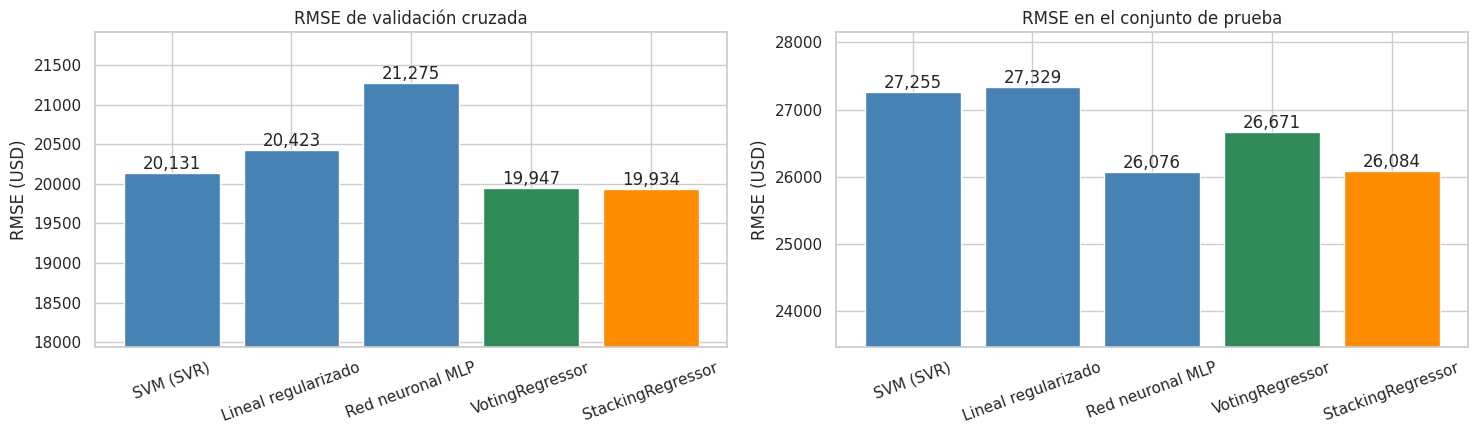

In [61]:
# P15. Comparación de los ensambles con los tres mejores modelos individuales.
tabla_modelos = pd.DataFrame(resumenes).set_index('Modelo')
comparar = TOP3 + ['VotingRegressor', 'StackingRegressor']
cols_comp = ['RMSE val', 'Desv. val', 'MAE val', 'R2 val', 'MAPE val (%)', 'Brecha (%)', 'RMSE prueba', 'MAE prueba',
             'R2 prueba', 'MAPE prueba (%)', 'Tiempo entrenamiento (s)']
comparacion_final = tabla_modelos.loc[comparar, cols_comp].copy()
comparacion_final['RMSE + MAE val'] = comparacion_final['RMSE val'] + comparacion_final['MAE val']
mejor_individual = comparacion_final.loc[TOP3, 'RMSE val'].min()
comparacion_final['Mejora RMSE val vs. mejor individual (%)'] = (1 - comparacion_final['RMSE val'] / mejor_individual) * 100
display(comparacion_final.sort_values('RMSE val').round(3))

fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5))
posiciones = np.arange(len(comparar))
colores = ['steelblue'] * 3 + ['seagreen', 'darkorange']
ejes[0].bar_label(ejes[0].bar(posiciones, comparacion_final.loc[comparar, 'RMSE val'], color=colores), fmt='{:,.0f}')
ejes[0].set(title='RMSE de validación cruzada', ylabel='RMSE (USD)', xticks=posiciones,
            ylim=(comparacion_final['RMSE val'].min() * 0.9, comparacion_final['RMSE val'].max() * 1.03))
ejes[0].set_xticklabels(comparar, rotation=20)
ejes[1].bar_label(ejes[1].bar(posiciones, comparacion_final.loc[comparar, 'RMSE prueba'], color=colores), fmt='{:,.0f}')
ejes[1].set(title='RMSE en el conjunto de prueba', ylabel='RMSE (USD)', xticks=posiciones,
            ylim=(comparacion_final['RMSE prueba'].min() * 0.9, comparacion_final['RMSE prueba'].max() * 1.03))
ejes[1].set_xticklabels(comparar, rotation=20)
plt.tight_layout()
plt.show()

In [62]:
# P15. Selección del modelo recomendado: la misma regla de un error estándar, ahora entre modelos.
componentes = {**{nombre: 1 for nombre in TOP3}, 'VotingRegressor': len(TOP3), 'StackingRegressor': len(TOP3) + 1}
seleccion = comparacion_final[['RMSE val', 'Desv. val', 'RMSE prueba', 'Tiempo entrenamiento (s)']].copy()
seleccion['Modelos que lo componen'] = pd.Series(componentes)
mejor_cv = seleccion['RMSE val'].idxmin()
umbral = seleccion.loc[mejor_cv, 'RMSE val'] + seleccion.loc[mejor_cv, 'Desv. val'] / np.sqrt(N_FOLDS)
seleccion['Empata estadísticamente con el mejor'] = seleccion['RMSE val'] <= umbral
candidatos = seleccion[seleccion['Empata estadísticamente con el mejor']].sort_values(['Modelos que lo componen', 'RMSE val'])
RECOMENDADO = candidatos.index[0]
display(seleccion.sort_values('RMSE val').round(2))
display(pd.DataFrame({'Menor RMSE de validación': [mejor_cv], 'Umbral (mejor + 1 error estándar)': [round(umbral, 0)],
                      'Opción B (menor RMSE)': [mejor_cv], 'Opción A (más simple dentro del empate)': [RECOMENDADO],
                      'Modelo recomendado': [RECOMENDADO]}))

,RMSE val,Desv. val,RMSE prueba,Tiempo entrenamiento (s),Modelos que lo componen,Empata estadísticamente con el mejor
Modelo,,,,,,
StackingRegressor,19934.09,1938.45,26083.63,4.87,4,True
VotingRegressor,19946.88,2069.57,26670.97,0.75,3,True
SVM (SVR),20130.69,1800.60,27254.96,0.23,1,True
Lineal regularizado,20422.91,2109.23,27328.93,0.14,1,True
Red neuronal MLP,21274.78,2557.99,26075.98,1.08,1,False


,Menor RMSE de validación,Umbral (mejor + 1 error estándar),Opción B (menor RMSE),Opción A (más simple dentro del empate),Modelo recomendado
0,StackingRegressor,20801.0,StackingRegressor,SVM (SVR),SVM (SVR)


<div style="background-color:#FFF4DC; border-left:6px solid #B7791F; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Evaluación de dos criterios para elegir el modelo final y decisión**

Al comparar los ensambles con los modelos individuales hay **dos criterios defendibles**, y se evaluaron ambos:

| | **Opción A: regla de 1 EE (simplicidad)** | **Opción B: menor RMSE** |
|---|---|---|
| Criterio | Entre los modelos dentro del umbral de un error estándar, elegir **el más simple** | Elegir el modelo con el **menor RMSE de validación** |
| Modelo resultante | **SVR (lineal)**: 20,130 USD, 1 modelo | **StackingRegressor**: 19,934 USD, 3 modelos + meta-modelo |
| A favor | Coherente con el criterio usado en toda la P9; más simple, rápido y explicable (un coeficiente por variable); menor brecha (6.9 %) | Menor RMSE en validación y MAE más bajo en prueba; diversifica el riesgo entre tres modelos |
| En contra | 1.0 % más de RMSE de validación que el Stacking | Su ventaja (196 USD) es **menor que un error estándar** (867 USD); triplica los modelos que hay que mantener; menos interpretable |

**Umbral de selección (calculado por código):** el umbral es 19,934 + 1,938/√5 = **20,801 USD**. Stacking, Voting, SVR y lineal regularizado quedan **dentro del umbral**; la MLP queda fuera.

**Decisión: Opción A, la SVR con kernel lineal.**
1. **Coherencia metodológica:** la regla de 1 EE se aplicó para elegir los hiperparámetros de cada modelo (P9); aplicar otro criterio al elegir el modelo final sería incoherente. Con 5 folds, una diferencia menor a un error estándar se considera pequeña bajo el criterio adoptado.
2. **No se decide con el conjunto de prueba:** la mejora del Stacking en prueba (4.3 %) es una sola partición de 292 casas. Usarla para elegir convertiría la prueba en validación y la evaluación final dejaría de ser independiente.
3. **Valor para el negocio:** la SVR lineal se explica con los coeficientes de la P10, entrena en menos de un segundo y tiene un solo componente que mantener y monitorear.

El Stacking queda documentado como **alternativa evaluada**. Se justificaría si en el futuro, con más datos, su ventaja superara el error estándar.

</div>

In [63]:
# P15. Error del modelo recomendado por rango de precio (conjunto de prueba): ¿dónde se equivoca más?
pred_rec = busquedas[RECOMENDADO].predict(X_test)
rangos = pd.qcut(y_test, q=4, labels=['Q1 (más baratas)', 'Q2', 'Q3', 'Q4 (más caras)'])
errores = pd.DataFrame({'Id': df_test['Id'], 'Condición de venta': df_test['SaleCondition'],
                        'Real': y_test, 'Predicho': pred_rec, 'Rango': rangos})
errores['Error absoluto'] = (errores['Real'] - errores['Predicho']).abs()
errores['Error %'] = errores['Error absoluto'] / errores['Real'] * 100
display(errores.groupby('Rango', observed=True).agg(Casas=('Real', 'count'), Precio_mediano=('Real', 'median'),
                                                     MAE=('Error absoluto', 'mean'), MAPE=('Error %', 'mean'),
                                                     Error_max=('Error absoluto', 'max')).round(1))
display(pd.DataFrame({'Modelo recomendado': [RECOMENDADO],
                      '% de casas con error < 10%': [(errores['Error %'] < 10).mean() * 100],
                      '% de casas con error < 20%': [(errores['Error %'] < 20).mean() * 100]}).round(1))
errores['Tipo de venta'] = np.where(errores['Condición de venta'].eq('Partial'), 'Partial (casa nueva no terminada)', 'Resto de condiciones')
display(errores.groupby('Tipo de venta').agg(Casas=('Real', 'count'), MAE=('Error absoluto', 'mean'),
                                             MAPE=('Error %', 'mean'), Error_max=('Error absoluto', 'max')).round(1))
display(errores.sort_values('Error absoluto', ascending=False).head(5).drop(columns='Tipo de venta').round(0))

,Casas,Precio_mediano,MAE,MAPE,Error_max
Rango,,,,,
Q1 (más baratas),73,109500.0,8972.9,9.8,40204.6
Q2,73,143750.0,10217.8,7.1,130512.2
Q3,73,182000.0,13087.6,7.2,49504.5
Q4 (más caras),73,260000.0,28234.0,8.2,182396.2


,Modelo recomendado,% de casas con error < 10%,% de casas con error < 20%
0,SVM (SVR),75.0,93.2


,Casas,MAE,MAPE,Error_max
Tipo de venta,,,,
Partial (casa nueva no terminada),25,43474.1,14.5,160288.0
Resto de condiciones,267,12473.9,7.5,182396.2


,Id,Condición de venta,Real,Predicho,Rango,Error absoluto,Error %
691,692,Normal,755000,572604.0,Q4 (más caras),182396.0,24.0
803,804,Partial,582933,422645.0,Q4 (más caras),160288.0,27.0
898,899,Partial,611657,463169.0,Q4 (más caras),148488.0,24.0
1324,1325,Partial,147000,277512.0,Q2,130512.0,89.0
1181,1182,Partial,392500,273764.0,Q4 (más caras),118736.0,30.0


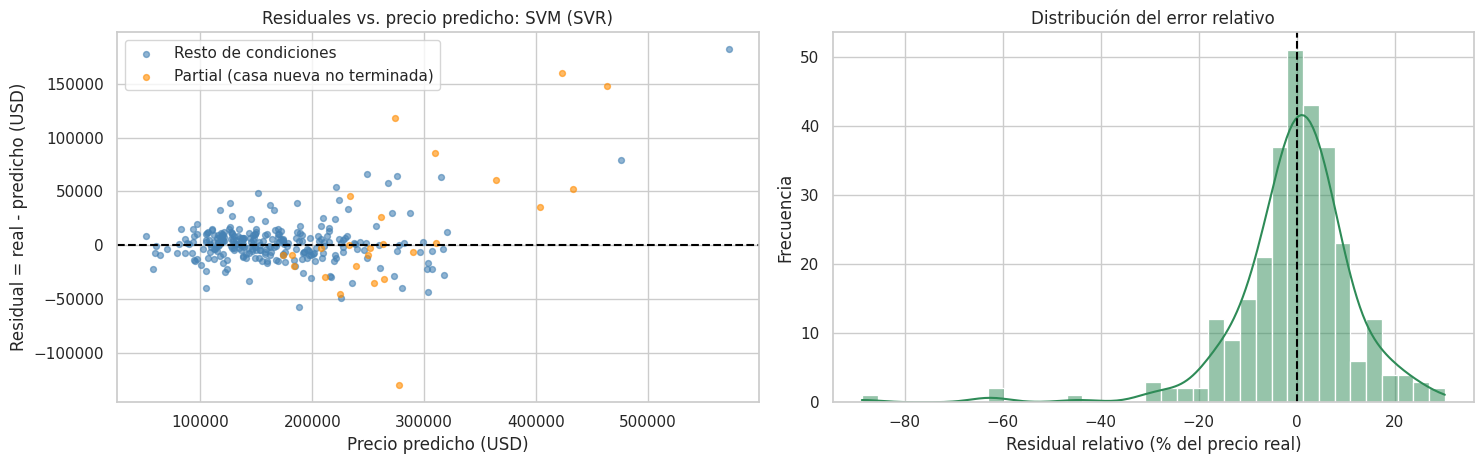

,Sesgo medio (USD),Residual mediano (USD),% de casas subestimadas,Residual medio en el cuartil más caro (USD)
0,3311.5,1320.4,53.8,17676.9


In [64]:
# P15. Análisis de residuales del modelo recomendado en el conjunto de prueba.
errores['Residual'] = errores['Real'] - errores['Predicho']
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.8))
for tipo, color in [('Resto de condiciones', 'steelblue'), ('Partial (casa nueva no terminada)', 'darkorange')]:
    grupo = errores[errores['Tipo de venta'] == tipo]
    ejes[0].scatter(grupo['Predicho'], grupo['Residual'], alpha=0.6, s=18, color=color, label=tipo)
ejes[0].axhline(0, ls='--', color='black')
ejes[0].set(title=f'Residuales vs. precio predicho: {RECOMENDADO}', xlabel='Precio predicho (USD)', ylabel='Residual = real - predicho (USD)')
ejes[0].legend()
sns.histplot(errores['Residual'] / errores['Real'] * 100, kde=True, ax=ejes[1], color='seagreen')
ejes[1].axvline(0, ls='--', color='black')
ejes[1].set(title='Distribución del error relativo', xlabel='Residual relativo (% del precio real)', ylabel='Frecuencia')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Sesgo medio (USD)': [errores['Residual'].mean()], 'Residual mediano (USD)': [errores['Residual'].median()],
                      '% de casas subestimadas': [(errores['Residual'] > 0).mean() * 100],
                      'Residual medio en el cuartil más caro (USD)': [errores.loc[errores['Rango'] == 'Q4 (más caras)', 'Residual'].mean()]}).round(1))

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P15. Los ensambles mejoran poco y dentro del ruido: se recomienda la SVR lineal individual**

| Modelo | RMSE val | MAE val | RMSE prueba | MAE prueba | MAPE prueba | Entrenamiento |
|---|---|---|---|---|---|---|
| StackingRegressor | **19,934** | 13,482 | 26,081 | **14,788** | 8.0 % | 4.869 s |
| VotingRegressor | 19,947 | **13,317** | 26,667 | 14,870 | **7.9 %** | 0.754 s |
| **SVR (lineal), recomendado** | 20,130 | 13,448 | 27,246 | 15,126 | 8.1 % | 0.231 s |
| Lineal regularizado | 20,423 | 13,672 | 27,329 | 15,409 | 8.2 % | 0.139 s |
| MLP | 21,275 | 14,454 | **26,076** | 15,270 | 8.5 % | 1.085 s |

**Comparación.**
* **Ambos ensambles superan a cada modelo individual en validación cruzada, pero por poco:** −1.0 % (Stacking) y −0.9 % (Voting) frente a la SVR, **menos que un error estándar** (867 USD). En prueba, el Stacking reduce el RMSE 4.3 % y tiene el menor MAE, pero esa es una sola partición.
* El Voting tiene el menor MAE de validación y el menor MAPE de prueba con pesos fijos; el Stacking aprende pesos similares (40 % SVR, 35 % lineal, 27 % MLP). Ninguno aporta una mejora que supere un error estándar.
* **¿Conviene usar un ensamble en lugar de los modelos individuales? No en este caso.** Con el criterio de la regla de 1 EE (ver la evaluación de las opciones A y B arriba), el ensamble no ofrece una ganancia que, según el criterio adoptado, compense su costo: más componentes, aproximadamente 21 veces más tiempo de entrenamiento y menor interpretabilidad. Se recomienda la **SVR lineal**.

**¿Dónde se equivoca la SVR? (conjunto de prueba)**
* **75.0 % de las casas** tienen un error menor al 10 %, y **93.2 %**, menor al 20 %.
* Por rango de precio, el **error relativo es homogéneo** (MAPE de 7.1 a 9.8 %). El error absoluto crece con el precio (MAE de 9.0k en el cuartil más barato y de 28.2k en el más caro).
* **Hallazgo clave: las ventas `Partial`** (casas nuevas no terminadas al momento del avalúo) tienen un **MAPE de 14.5 %**, el doble que el resto (7.5 %), y **4 de los 5 errores más grandes** son de este tipo (Id 804, 899, 1182 y 1325, construidas entre 2006 y 2009). Su precio refleja condiciones de preventa, no solo las características de la casa, como advierte De Cock. El quinto caso es la casa de lujo Id 692 (755k USD), subestimada en 24 %: en el entrenamiento casi no hay ejemplos comparables.
* **Residuales:** el sesgo medio es de **+3,303 USD** (el modelo subestima ligeramente; el 53.8 % de las casas queda por debajo de su precio real), y se concentra en las casas caras: en el cuartil superior la subestimación media es de **17,654 USD**. La gráfica muestra el patrón de embudo típico (la dispersión crece con el precio), y los puntos naranjas (`Partial`) ocupan los extremos en ambas direcciones. El error relativo está **centrado cerca de cero** y concentrado entre −20 % y +20 %, con una **cola izquierda** de pocas casas sobrevaluadas, como la Id 1325 (−89 %).
 La reflexión que consideramos importante agregar es sobre el costo económico de los errores de predicción. Sobreestimar y subestimar una vivienda no necesariamente tienen las mismas consecuencias económicas. Esto cobra relevancia porque encontramos mayores errores y una tendencia a subestimar las viviendas de mayor valor.

</div>

# **8. Reportes finales (P16) y conclusiones (P17)**

## **P16a. Reporte para el equipo técnico**

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Decisión técnica: desplegar la SVR con kernel lineal; el StackingRegressor queda como alternativa evaluada**

**1. Métricas (selección por validación cruzada, evaluación en prueba independiente).**

| Criterio | **SVR lineal (recomendada)** | StackingRegressor (alternativa) | Modelo base |
|---|---|---|---|
| RMSE validación cruzada | **20,130 USD** (± 1,801) | 19,934 USD (± 1,938) | 77,249 USD |
| RMSE / MAE prueba | 27,246 / 15,126 USD | 26,081 / 14,788 USD | 86,624 / 58,749 USD |
| R² / MAPE prueba | 0.901 / 8.1 % | 0.909 / 8.0 % | — |
| Brecha entrenamiento-validación | **6.9 %** | 11.8 % | — |
| Componentes / tiempo de entrenamiento | **1 / 0.231 s** | 4 / 4.869 s | — |

**2. Criterio de decisión.** Se aplicó la **regla de un error estándar** en dos niveles: (a) para elegir los hiperparámetros de cada modelo y (b) para elegir el modelo final. El Stacking tiene el menor RMSE, pero su ventaja (196 USD) es menor que un error estándar (867 USD), y la SVR es el modelo más simple dentro del umbral. Se evaluaron explícitamente ambas opciones (ver P15).

**3. Ajuste.**
* Configuración final: SVR con kernel lineal, C = 0.01, ε = 0.1, Yeo-Johnson en las numéricas, ordinales codificadas en orden, One-Hot sin `drop` y objetivo `log1p` estandarizado.
* Brecha de 6.9 % (la menor de todos los modelos) y curva de aprendizaje convergente: el modelo está **limitado por sesgo**, así que agregar datos aportaría poco; las mejoras deben venir de nuevas variables.
* **Descartados:** el árbol de decisión (RMSE de 36k, predicciones escalonadas), el bosque aleatorio (27.7k; no extrapola a las casas caras) y la OLS sin regularizar (brecha del 28 %). XGBoost (22.8k) queda como candidato para una iteración futura con más datos, porque su brecha se cierra al agregar registros.

**4. Costo computacional.** Entrenamiento en **0.231 s**; la búsqueda de hiperparámetros de la SVR toma ~87.7 s, y el cuaderno completo (seis modelos, ensambles y experimentos) ~10 minutos en 2 núcleos. No se requiere GPU ni infraestructura especial. El costo dominante es el **reentrenamiento periódico**, no la predicción.

**5. Mantenimiento de la solución.**
* **Artefacto del modelo:** preprocesamiento, transformación del objetivo y modelo forman un objeto de scikit-learn serializable con `joblib`. Se deben **fijar las versiones** (scikit-learn 1.9.1 y xgboost 3.4.1, como en la celda de instalación).
* **Contrato de datos:** leer los archivos con `keep_default_na=False, na_values=['NA']` (si no, `None` se convierte en faltante); validar las escalas ordinales contra el diccionario; aplicar las reglas de NA estructural de la función `preparar`. Las categorías nominales nuevas se manejan sin error (`handle_unknown='ignore'`), pero deben registrarse. También deben registrarse las inconsistencias como las de `MasVnrType`/`MasVnrArea`.
* **Monitoreo:** MAPE por segmento (rango de precio, barrio, condición de venta), porcentaje de casas con error mayor al 20 % y deriva en la distribución de `GrLivArea`, `OverallQual` y `Neighborhood`, sus factores más importantes (P10).
* **Reentrenamiento:** al acumular nuevas ventas (por ejemplo, cada trimestre) o cuando el MAPE de monitoreo supere el 10 %, repitiendo el mismo flujo de validación. Con más datos debe **reevaluarse el Stacking**: si su ventaja supera un error estándar, conviene adoptarlo.

**6. Riesgos técnicos y mitigación.**
* **Nivel de precios desactualizado:** los datos son de 2006 a 2010. Por la restricción de valuación estática, el modelo no ajusta por tiempo, así que **debe reentrenarse con ventas recientes** antes de usarse en 2026 o en otro mercado.
* **Ventas `Partial` y casas nuevas:** MAPE de 14.5 % (el doble del resto). Se recomienda marcarlas para revisión o modelarlas por separado cuando haya más datos.
* **Casas de lujo:** el modelo las subestima (−17.7k en promedio en el cuartil más caro). Se recomienda una alerta automática para casas de más de 4,000 ft² o con predicciones superiores a 450k USD.
* **Mejoras sugeridas:** variables derivadas (superficie total, baños totales), intervalos de predicción (regresión cuantílica) para comunicar la incertidumbre y ampliar los rangos de hiperparámetros que quedaron en el borde de la malla.

</div>

## **P16b. Reporte para el director de la empresa inmobiliaria**

<div style="background-color:#FFF4DC; border-left:6px solid #B7791F; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Recomendación: adoptar el valuador automático como herramienta de apoyo, con revisión humana en casos especiales**

**¿Qué se construyó?** Un sistema que estima en segundos el precio de venta de una casa a partir de sus características (tamaño, calidad, antigüedad, ubicación, etc.). Se compararon seis tipos de modelos y dos formas de combinarlos. Se eligió **el modelo más sencillo entre los que dieron los mejores resultados**: combinar varios modelos mejoraba la precisión en menos de 1 %, una diferencia que no compensa la complejidad adicional.

**Beneficios**
* **Precisión:** en casas que el sistema nunca vio, el error típico es de **alrededor del 8 % del precio** (unos 15,100 USD en promedio). **3 de cada 4 casas** quedan con un error menor al 10 %, y **más de 9 de cada 10**, con menos del 20 %. Frente a estimar con el precio promedio del mercado, el error promedio por casa se reduce en **74 %** (de 58,700 a 15,100 USD).
* **Rapidez y consistencia:** valúa al instante y siempre con el mismo criterio, lo que libera tiempo de los valuadores para los casos complejos.
* **Es explicable:** cada estimación puede desglosarse en cuánto aporta cada característica. El sistema confirma lo que un experto esperaría: el precio lo determinan, en ese orden, la **superficie habitable**, la **calidad de construcción**, el **sótano**, la **antigüedad**, el **terreno** y la **ubicación**. Esto facilita justificar cada valuación ante clientes.

**Riesgos**
* **Precios de referencia antiguos:** el sistema aprendió con ventas de 2006 a 2010 en Ames, Iowa. **Antes de usarlo, debe actualizarse con ventas recientes** del mercado donde operará la empresa; de lo contrario, sus precios no reflejarán el nivel actual.
* **Casas nuevas en preventa y casas de lujo:** son los casos donde más se equivoca (el error se duplica en ventas de casas no terminadas, y las casas más caras tienden a quedar subvaluadas). Estas valuaciones deben pasar por revisión de un valuador.
* **No sustituye un avalúo formal:** es una estimación estadística basada en ventas pasadas. Sirve para cotizar, priorizar y detectar precios fuera de mercado, no para dictaminar.

**Costos**
* **Tecnológicos: muy bajos.** El sistema se entrena en menos de un segundo en una computadora convencional; no requiere servidores especiales.
* **Operativos: el costo principal es la información.** Hay que recopilar y depurar las ventas recientes, actualizar el sistema periódicamente (por ejemplo, cada trimestre) y contar con un analista que vigile su precisión.

**Siguiente paso propuesto:** un **piloto de 3 meses** en el que el sistema estime todas las propiedades nuevas en cartera, en paralelo con los valuadores. Se medirá la diferencia entre ambos y el tiempo ahorrado, y se decidirá su uso definitivo con esa evidencia.

Es necesario destacar la distinción entre el precio estimado de transacción y el precio óptimo de comercialización, ya que este último también depende de las condiciones de demanda, los tiempos esperados de venta y los costos de mantener una propiedad en el mercado.

</div>

## **P17. Conclusiones de la actividad**

<div style="background-color:#E8F1FB; border-left:6px solid #1F5FAE; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**Respuesta P17. Conclusiones de la actividad**

1. **La calidad de los datos se decide en los detalles.** Leer el archivo con la configuración por omisión de pandas habría fabricado 864 faltantes falsos en `MasVnrType`, y tratar todos los NA como faltantes habría "imputado" garajes, sótanos y albercas inexistentes. Validar fila por fila con variables de soporte convirtió el 99.5 % de "faltantes" de `PoolQC` en información confiable.

2. **Las restricciones temporales tienen respaldo empírico.** `YrSold` no se asocia con el precio (Kruskal-Wallis p = 0.76), las edades conservan la señal de los años sin su referencia absoluta, y el mes tiene un efecto estacional débil que se representa mejor de forma cíclica. Además, `GarageYrBlt` requería el mismo tratamiento aunque el enunciado no la mencionara.

3. **La transformación del objetivo fue la decisión individual más rentable.** Modelar `log(SalePrice)` redujo el RMSE de Ridge en 27.5 % y estabilizó a la MLP. Estandarizar ese logaritmo resultó decisivo para la red neuronal.

4. **En este problema ganan los modelos lineales regularizados.** En la escala logarítmica, el precio es casi una suma de efectos porcentuales (tamaño, calidad, antigüedad y ubicación), y con 1,166 casas los modelos simples generalizan mejor. La SVR lineal (20,130 USD) y Elastic Net (20,423 USD) superaron a XGBoost (22,797), al bosque aleatorio (27,710) y al árbol (36,085), y los modelos de árboles mostraron además su incapacidad para extrapolar a las casas de lujo.

5. **Cuidar el sobreentrenamiento tiene un costo explícito, y el criterio debe aplicarse con coherencia.** La regla de un error estándar redujo la brecha entrenamiento-validación del bosque aleatorio de 59 % a 22 %, y la de la MLP de 33 % a 18 %, a cambio de pocos puntos porcentuales de RMSE. Las curvas de aprendizaje distinguieron los modelos limitados por sesgo (lineales) de los limitados por varianza (XGBoost y bosque), que mejorarían con más datos.

6. **Los ensambles no justificaron su complejidad.** El StackingRegressor obtuvo el menor RMSE de validación (−1.0 % frente a la SVR), pero su ventaja es menor que un error estándar. Se evaluaron dos criterios de selección (menor RMSE y la regla de 1 EE), y se eligió la **SVR lineal** por coherencia metodológica, simplicidad e interpretabilidad, sin usar el conjunto de prueba para decidir. La ganancia de los ensambles es pequeña porque dos de sus tres componentes son lineales y cometen errores parecidos.

7. **El error es relativamente homogéneo, pero se concentra en pocos casos.** El MAPE es prácticamente igual en validación y en prueba (≈ 8 %). La diferencia entre el RMSE de validación y el de prueba se explica por unas pocas casas caras y casas nuevas vendidas como `Partial` (MAPE del 14.5 % contra 7.5 % del resto), segmentos que requieren revisión humana.

8. **El RMSE y el MAE deben complementarse con métricas relativas.** Una misma cifra en dólares significa cosas distintas en una casa de 100k y en una de 500k; el MAPE y el análisis por rango de precio completan la evaluación para el negocio.

9. **Evaluación de la utilidad económica del modelo** Sería conveniente contrastar las predicciones con los precios efectivamente negociados y los tiempos de comercialización, además de las métricas de desempeño estadístico.

</div>

# **Conclusiones**

Incluyan los comentarios y conclusiones de esta actividad. En particular, respondan sobre los siguientes puntos:

* ¿En qué casos el uso de LLMs fue de mayor provecho?
* ¿En cuáles casos la intervención como expertos en combinación con los LLM fue importante para alcanzar con los objetivos propuestos?


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

<div style="background-color:#F3F0FA; border-left:6px solid #5E35B1; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**¿En qué casos el uso de LLMs fue de mayor provecho?**

* **Lectura e integración de fuentes:** el LLM leyó el enunciado, el diccionario de datos, la página del reto en Kaggle y el artículo original de De Cock (2011). De este último salió el criterio documentado para los atípicos, la recomendación de eliminar las ventas `Partial` de más de 4,000 ft².
* **Exploración rápida y sistemática de alternativas:** permitió convertir cada decisión en un experimento con validación cruzada (cuatro opciones de `MoSold`, tres imputaciones, tres transformaciones numéricas, objetivo con o sin logaritmo, `drop` del One-Hot), algo que manualmente habría tomado varias sesiones.
* **Detección de problemas sutiles en los datos:** identificó que pandas convertía la categoría `None` en faltante y que el NA de 14 variables era estructural, y lo verificó con código.
* **Generación y depuración de código:** pipelines, búsquedas de hiperparámetros, gráficas y tablas. También detectó incompatibilidades de versión (por ejemplo, argumentos posicionales que scikit-learn ya no acepta en `MLPRegressor`).
* **Redacción** de las justificaciones y de los reportes para dos audiencias distintas.

</div>

<div style="background-color:#F3F0FA; border-left:6px solid #5E35B1; padding:10px 16px; border-radius:4px; color:#1B1B1B;">

**¿En cuáles casos la intervención como expertos en combinación con los LLM fue importante?**

* **Fijar el estándar metodológico antes de empezar:** el equipo estableció las reglas que el LLM debía cumplir, como no inventar información, tomar toda decisión con evidencia del propio conjunto, separar el análisis en celdas de texto, presentar la evidencia en DataFrames y calcular todo por código. También incorporó la retroalimentación del tutor en actividades previas (la declaración del LLM desde la identificación y no encadenar `StandardScaler` después de `PowerTransformer`).
* **Exigir la fuente original y no el resumen:** solicitar la lectura completa de la página de Kaggle llevó al artículo de De Cock, que respalda la decisión sobre los atípicos con un criterio del dominio y no con un umbral arbitrario.
* **No aceptar la primera respuesta:** varias decisiones iniciales cambiaron al revisar la evidencia. El tratamiento de `MoSold` pasó de "eliminar" a "cíclica" cuando la CV repetida mostró que la cíclica ganaba en ambas familias de modelos, y la transformación numérica pasó de ser una elección fija a un hiperparámetro cuando los datos no mostraron una ganadora universal.
* **Revisión crítica del resultado como lo haría el profesor:** al pedirle al LLM que evaluara el cuaderno contra el enunciado y lo calificara, aparecieron huecos que el propio LLM había dejado. El más importante fue una **incoherencia de criterio**: se usaba la regla de 1 EE para los hiperparámetros, pero se recomendaba el Stacking aunque su ventaja estaba dentro del error estándar. El equipo decidió evaluar ambas opciones de forma explícita y adoptar la coherente (SVR). Esa revisión también agregó la OLS de referencia, los experimentos de codificación de ordinales y de variables casi constantes, y la fijación de versiones.
* **Juicio sobre el sobre y subentrenamiento:** definir qué significa "cuidar que no estén sobreentrenados" en regresión (la regla de 1 EE y los umbrales de brecha) es una decisión de criterio, no de cálculo. El LLM propone; el experto decide qué riesgo está dispuesto a aceptar.
* **Interpretación para el negocio:** traducir coeficientes y errores en recomendaciones (revisión humana para casas de lujo y ventas `Partial`, actualización de precios a 2026) requiere entender el contexto inmobiliario, no solo las métricas.

</div>

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **Anexo**

**Incluir a continuación los prompts que consideren hayan sido los más importantes, así como el nombre del modelo LLM utilizado.**

### +++++++++++ Inicia sección de prompts ++++++++++++++++

**Modelo LLM utilizado:** Claude Opus 5.5 (Anthropic), mediante la aplicación Claude con ejecución de código.

**Prompts más importantes (en orden cronológico):**

1. **Marco de trabajo y reglas de calidad.** *"Contexto y reglas de oro — Maestría en IA Aplicada [...] NUNCA asumas ni inventes información [...] Análisis, interpretaciones y conclusiones van SOLO en celdas de texto [...] La evidencia se presenta con DataFrames [...] Todo se obtiene por código [...] Justificar en texto cada decisión metodológica."* Se incluyó además la retroalimentación del tutor en actividades previas: la declaración del LLM desde la celda de identificación y evitar `StandardScaler` después de `PowerTransformer`.
2. **Comprensión de la actividad.** *"Avísame cuando ya tengas todo leído, comprendido y revisado a detalle [...] avísame si te hace falta que te comparta algo."* Se compartieron el PDF de instrucciones, el cuaderno base y las ligas de Kaggle.
3. **Plan de trabajo.** *"Quiero que lo que armes, además de cumplir con lo que piden las 17 preguntas, también siga el mismo esquema de los otros ejercicios [...] dame un plan de trabajo que sea impecable para cumplir con todo lo solicitado."*
4. **Lectura de la fuente original.** *"Quiero que leas a detalle toda la página con la información que hay en ella para lograr el resultado que se solicita"* (página del reto en Kaggle y artículo de De Cock, 2011).
5. **Ejecución completa con evidencia.** *"Revisa en tu entorno todas las variables y prueba lo que consideres necesario; con base en ello genera el resultado completo del ipynb [...] debemos tener una muy buena justificación para cada ejercicio."*
6. **Revisión como profesor.** *"Haz una estricta validación de todo lo que pide la actividad vs lo que estamos entregando y califica tu resultado, como si fueras el profesor de la materia, y dame una tabla de sugerencias y mejoras."*
7. **Decisión sobre el modelo final.** *"Si la opción que tú seleccionas es la A, hagámoslo, pero dejemos en claro en el cuaderno que evaluamos ambas y por qué decidimos usar esa; asimismo aplica todas las mejoras que has sugerido."*

**Tabla de trazabilidad del uso del LLM por pregunta**

| Pregunta | Uso del LLM | Verificación y criterio del equipo |
|---|---|---|
| Carga y EDA | Detección de que `None` se leía como faltante; diagnóstico del NA estructural con variables de soporte | Se exigió cuantificar el efecto (872 contra 8) y validar cada regla con los datos |
| P1 | Prueba de Kruskal-Wallis y tabla por año | Se verificó que la decisión cumple la restricción de valuación estática |
| P2 | Cálculo de edades y análisis de redundancia; propuesta de tratar también `GarageYrBlt` | Año obtenido por código y verificado como 2026; correlación −1 como evidencia |
| P3 | Experimento con las 4 opciones en 2 familias de modelos | La decisión inicial ("eliminar") se cambió a "cíclica" al revisar la CV repetida |
| P4 | Comparación de imputaciones, transformaciones, objetivo logarítmico, codificación de ordinales y variables casi constantes | Regla del tutor: sin `StandardScaler` después de `PowerTransformer`; transformación elegida por CV para cada modelo |
| P5 | Cruces NA contra área del elemento | Se rechazó imputar con la moda; la evidencia fila por fila respalda la decisión |
| P6 | Experimento `drop='first'` contra `None` con conteo de categorías no vistas | Se contrastó la teoría (trampa de dummies) con la evidencia empírica |
| P7-P8 | Partición estratificada, prueba KS y modelos ingenuos | Conjunto de prueba reservado antes de cualquier análisis |
| P9 | Mallas de hiperparámetros, regla de 1 EE, curvas de aprendizaje | Criterio de sobre y subentrenamiento definido explícitamente; revisión visual de cada gráfica (se corrigió la escala de la MLP) |
| P10-P11 | Importancia por permutación y coeficientes en % del precio | Interpretación en el contexto inmobiliario de Ames |
| P12-P15 | Investigación conceptual, implementación de los ensambles y comparación mediante el umbral de un error estándar | El equipo eligió entre dos criterios (opción A: regla de 1 EE; opción B: menor RMSE) y documentó ambos; se corrigieron afirmaciones contra las cifras reales |
| Revisión final | Evaluación estricta del cuaderno contra el enunciado, con calificación y tabla de mejoras | El equipo ordenó aplicar todas las mejoras: OLS de referencia, experimentos de la P4, versiones fijas, importancia por CV, residuales, RMSLE y selección de `MoSold` por código |
| P16-P17 | Redacción de los reportes técnico y ejecutivo | Recomendaciones con los riesgos de negocio identificados |

### +++++++++++ Termina sección de prompts ++++++++++++++++

# **<<< Fin de la Actividad de la Semana - Predicción de Precios de Casas >>>**